این تکلیف شش بخش و ۴۰ زیرسؤال دارد و روی هم ۱۰۰ نمره است: بخش‌های ۱ تا ۴ روی دیتاست adult.csv (۴۰ نمره)، بخش ۵ روی Airbnb_Open_Data.csv و بخش ۶ روی Airline Dataset.csv (روی هم ۶۰ نمره). نام دیتاست هر بخش در سربرگ همان بخش آمده است.
-

# تکلیف تحلیل داده و داده‌کاوی

این نوت‌بوک برای بررسی و تحلیل مجموعه‌داده **Adult (Census Income)** تهیه شده است. هدف آن، آماده‌سازی داده‌ها، شناخت ساختار و انواع متغیرها، محاسبه شاخص‌های آماری و ارائه نمایش‌های مناسب از داده‌ها است. بخش‌های بعدی تکلیف در ادامه همین نوت‌بوک اضافه خواهند شد.

تمام نتایج عددی و تفسیری باید از اجرای واقعی کد روی داده‌های بارگذاری‌شده به دست آیند؛ بنابراین از حدس‌زدن مقدارها یا جایگزین‌کردن داده مصنوعی خودداری می‌شود.

## آماده‌سازی محیط و کتابخانه‌ها

در این بخش کتابخانه‌های موردنیاز برای بارگذاری، بررسی و نمایش داده وارد می‌شوند. در صورت وجود محدودیت فونت فارسی، تنظیمات نمودار به‌گونه‌ای انتخاب می‌شود که تا حد امکان خوانا باقی بماند.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("data") / "adult.csv"
print(f"مسیر نسبی مورد استفاده برای داده: {DATA_PATH}")

مسیر نسبی مورد استفاده برای داده: data\adult.csv


## بارگذاری و بررسی اولیه دیتاست

### منبع و شیوه آماده‌سازی

فایل `adult.csv` از رکورد **Adult (Census Income)** در Zenodo با شناسه ۷۲۱۴۲۷۵ دریافت شده است. این نسخه بر اساس داده‌های عمومی Adult ارائه شده و در مسیر `DataMining/data/adult.csv` ذخیره شده است.

بررسی محتوای فایل نشان می‌دهد که فایل بدون ردیف عنوان است، جداکننده آن ویرگول است، مقادیر با فاصله ابتدایی ذخیره شده‌اند و مقدار گمشده با علامت `?` نمایش داده می‌شود. بنابراین در بارگذاری از `header=None`، `skipinitialspace=True` و `na_values=["?"]` استفاده می‌کنیم. نام‌های اصلی استاندارد Adult حفظ می‌شوند؛ تفاوت احتمالی آن‌ها با نام‌های مورد استفاده در صورت سؤال (مانند `marital.status` و `education.num`) در ادامه با یک نگاشت مستند مدیریت خواهد شد.

In [2]:
adult_columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income",
]

if not DATA_PATH.exists():
    raise FileNotFoundError(f"فایل دیتاست پیدا نشد: {DATA_PATH}")

adult = pd.read_csv(
    DATA_PATH,
    header=None,
    names=adult_columns,
    sep=",",
    skipinitialspace=True,
    na_values=["?"],
    keep_default_na=True,
)

print(f"بارگذاری با موفقیت انجام شد: {DATA_PATH}")
print(f"تعداد ردیف‌ها: {adult.shape[0]:,}")
print(f"تعداد ستون‌ها: {adult.shape[1]}")

بارگذاری با موفقیت انجام شد: data\adult.csv
تعداد ردیف‌ها: 32,561
تعداد ستون‌ها: 15


In [3]:
print("نام ستون‌ها:")
print(list(adult.columns))

print("\nنوع داده هر ستون:")
display(adult.dtypes.rename("نوع داده").to_frame())

print("\nپنج سطر نخست:")
display(adult.head())

print("\nتعداد مقادیر گمشده در هر ستون:")
missing_summary = adult.isna().sum().rename("تعداد مقادیر گمشده").to_frame()
missing_summary["درصد از کل ردیف‌ها"] = (missing_summary["تعداد مقادیر گمشده"] / len(adult) * 100).round(2)
display(missing_summary)

print("تعداد کل سلول‌های گمشده:", int(adult.isna().sum().sum()))

نام ستون‌ها:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

نوع داده هر ستون:


,نوع داده
age,int64
workclass,object
fnlwgt,int64
education,object
education-num,int64
marital-status,object
occupation,object
relationship,object
race,object
sex,object



پنج سطر نخست:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



تعداد مقادیر گمشده در هر ستون:


,تعداد مقادیر گمشده,درصد از کل ردیف‌ها
age,0,0.00
workclass,1836,5.64
fnlwgt,0,0.00
education,0,0.00
education-num,0,0.00
marital-status,0,0.00
occupation,1843,5.66
relationship,0,0.00
race,0,0.00
sex,0,0.00


تعداد کل سلول‌های گمشده: 4262


In [4]:
important_columns = [
    "marital-status", "education", "sex", "age", "income",
    "education-num", "workclass",
]

missing_columns = [column for column in important_columns if column not in adult.columns]
if missing_columns:
    raise KeyError(f"ستون‌های اصلی در داده پیدا نشدند: {missing_columns}")

column_mapping = {
    "marital.status": "marital-status",
    "education.num": "education-num",
}
print("نگاشت نام‌های صورت سؤال به نام‌های واقعی دیتاست:")
display(pd.Series(column_mapping, name="نام واقعی در دیتاست"))

for column in important_columns:
    print(f"\nمقادیر متمایز ستون {column}:")
    display(adult[column].value_counts(dropna=False).rename("تعداد").to_frame())

نگاشت نام‌های صورت سؤال به نام‌های واقعی دیتاست:


marital.status    marital-status
education.num      education-num
Name: نام واقعی در دیتاست, dtype: object


مقادیر متمایز ستون marital-status:


,تعداد
marital-status,
Married-civ-spouse,14976
Never-married,10683
Divorced,4443
Separated,1025
Widowed,993
Married-spouse-absent,418
Married-AF-spouse,23



مقادیر متمایز ستون education:


...

,تعداد
income,
<=50K,24720
>50K,7841



مقادیر متمایز ستون education-num:


,تعداد
education-num,
9,10501
10,7291
13,5355
14,1723
11,1382
7,1175
12,1067
6,933
4,646



مقادیر متمایز ستون workclass:


,تعداد
workclass,
Private,22696
Self-emp-not-inc,2541
Local-gov,2093
NaN,1836
State-gov,1298
Self-emp-inc,1116
Federal-gov,960
Without-pay,14
Never-worked,7


### جمع‌بندی بررسی اولیه

در سلول‌های بالا ابعاد واقعی داده، نام و نوع ستون‌ها، نمونه‌ای از رکوردها، مقادیر گمشده و مقادیر متمایز ستون‌های اصلی نمایش داده شد. در ادامه تکلیف، روش مدیریت مقادیر گمشده برای هر محاسبه به‌صورت جداگانه و با ذکر دلیل مشخص خواهد شد. در این مرحله هیچ ردیفی به‌صورت خودکار حذف یا مقدار دسته‌ای `income` تغییر داده نشده است.

## بخش ۱: شناخت انواع داده

در این بخش، نوع معنایی ویژگی‌ها و شاخص گرایش به مرکز مناسب برای داده‌های کیفی بررسی می‌شود.

### سؤال ۱.۱ — تشخیص نوع ویژگی‌ها

**صورت سؤال:**

«برای هر یک از ویژگی‌های `marital.status`، `education`، `sex`، `age` و `income`، نوع دقیق آن ویژگی (Nominal، Ordinal، Binary، Numeric) را مشخص کنید. اگر عددی است، مشخص کنید interval-scaled یا ratio-scaled است؟»

نوع ویژگی بر اساس معنای داده تعیین می‌شود، نه فقط نوع ذخیره‌سازی آن در Python. دسته‌های Nominal، Ordinal و Binary الزاماً متقابلاً انحصاری نیستند؛ برای نمونه، یک ویژگی دودویی می‌تواند هم‌زمان اسمی یا ترتیبی نیز باشد.

In [5]:
# بررسی واقعی تعداد دسته‌ها و نوع ذخیره‌سازی ستون‌های سؤال ۱.۱
question_11_columns = {
    "marital.status": "marital-status", "education": "education", "sex": "sex",
    "age": "age", "income": "income",
}
question_11_summary = pd.DataFrame({
    "نام ویژگی در سؤال": list(question_11_columns),
    "نام ستون در دیتاست": list(question_11_columns.values()),
    "نوع ذخیره‌سازی در pandas": [str(adult[c].dtype) for c in question_11_columns.values()],
    "تعداد مقادیر متمایز": [int(adult[c].nunique(dropna=True)) for c in question_11_columns.values()],
    "مقادیر متمایز غیرگمشده": [list(adult[c].dropna().unique()) for c in question_11_columns.values()],
})
display(question_11_summary)
print("\nبررسی تعداد دسته‌های sex و income:")
print("sex:", adult["sex"].dropna().unique().tolist())
print("income:", adult["income"].dropna().unique().tolist())

,نام ویژگی در سؤال,نام ستون در دیتاست,نوع ذخیره‌سازی در pandas,تعداد مقادیر متمایز,مقادیر متمایز غیرگمشده
0,marital.status,marital-status,object,7,"[Never-married, Married-civ-spouse, ..."
1,education,education,object,16,"[Bachelors, HS-grad, 11th, Masters, ..."
2,sex,sex,object,2,"[Male, Female]"
3,age,age,int64,73,"[39, 50, 38, 53, 28, 37, 49, 52, 31,..."
4,income,income,object,2,"[<=50K, >50K]"



بررسی تعداد دسته‌های sex و income:
sex: ['Male', 'Female']
income: ['<=50K', '>50K']


#### پاسخ تحلیلی سؤال ۱.۱

| نام ویژگی | نوع ویژگی از بین گزینه‌های سؤال | نوع مقیاس در صورت کاربرد | دلیل |
|---|---|---|---|
| `marital.status` | اسمی (Nominal) | کاربرد ندارد | وضعیت‌های تأهل دسته‌های کیفی‌اند و ترتیب طبیعی میان آن‌ها وجود ندارد. این ستون ۷ دستهٔ غیرگمشده دارد، پس دودویی نیست. |
| `education` | ترتیبی (Ordinal) | کاربرد ندارد | سطح‌های تحصیلی ترتیب معنایی دارند؛ بااین‌حال فاصلهٔ میان برچسب‌ها الزاماً برابر نیست و خود برچسب‌ها عددی نیستند. |
| `sex` | دودویی (Binary) | کاربرد ندارد | در دادهٔ حاضر دو دستهٔ غیرگمشده مشاهده شده است؛ بنابراین از گزینه‌های سؤال، نوع آن دودویی است. |
| `age` | عددی نسبی (Numeric, ratio-scaled) | نسبی | سن کمیتی عددی است، صفر به معنای نبود سنِ سپری‌شده از تولد است و نسبت‌ها قابل تفسیرند؛ مثلاً ۴۰ سال دو برابر ۲۰ سال از نظر مدت زمان سپری‌شده است. |
| `income` | دودویی (Binary) | کاربرد ندارد | دو دستهٔ واقعی `<=50K` و `>50K` وجود دارد؛ بنابراین از گزینه‌های سؤال، نوع آن دودویی است. |

در این جدول برای رعایت قالب سؤال، برای هر ویژگی فقط یک گزینهٔ اصلی انتخاب شده است. گرچه `sex` از نظر معنایی اسمی و `income` از نظر ترتیب آستانه‌ای قابل مرتب‌سازی است، پاسخ نهایی آن‌ها در میان گزینه‌های داده‌شده «دودویی» است.

#### پاسخ نهایی کوتاه سؤال ۱.۱

- `marital.status`: **اسمی**؛ هفت دستهٔ مشاهده‌شده دارد و ترتیب طبیعی ندارد.
- `education`: **ترتیبی**؛ سطح‌های تحصیلی ترتیب دارند، اما فاصلهٔ عددی برابر میان آن‌ها تعریف نشده است.
- `sex`: **دودویی**؛ در داده دو دستهٔ مشاهده‌شده دارد.
- `age`: **عددی نسبی**؛ صفر و نسبت‌ها معنای قابل تفسیر دارند.
- `income`: **دودویی**؛ دو دستهٔ مشاهده‌شده دارد.

### سؤال ۱.۲ — نوع ویژگی دودویی بیماری نادر

**صورت سؤال:**

«فرض کنید یک ویژگی به نام `has_rare_disease` (ابتلا به یک بیماری نادر) داشتیم. توضیح دهید این ویژگی در کدام‌یک از دسته‌های ویژگی‌های Binary قرار می‌گیرد؟ چرا؟»

ویژگی دودویی فقط دو مقدار ممکن دارد، اما این دو مقدار همیشه اهمیت معنایی یکسانی ندارند.

#### توضیح مفهومی و پاسخ سؤال ۱.۲

- در **Binary متقارن (Symmetric Binary)**، دو حالت اهمیت تقریباً یکسان دارند و جابه‌جایی نقش صفر و یک نتیجهٔ مفهومی را تغییر نمی‌دهد؛ نمونهٔ معمول، نتیجهٔ شیر یا خط است.
- در **Binary نامتقارن (Asymmetric Binary)**، یکی از حالت‌ها مهم‌تر یا نادرتر است و حضور آن اطلاعات بیشتری دارد.

ویژگی `has_rare_disease` یک ویژگی **Binary نامتقارن** است، زیرا ابتلا به بیماری نادر رخدادی کم‌تعداد و از نظر پزشکی مهم است، درحالی‌که عدم ابتلا حالت غالب و هم‌ارز با ابتلا نیست. نمایش مناسب:

- `0`: فرد به بیماری نادر مبتلا نیست.
- `1`: فرد به بیماری نادر مبتلا است.

در این مثال، اهمیت اصلی در تشخیص مقدار `1` است؛ پس ویژگی نامتقارن است.

### سؤال ۱.۳ — میانگین `education` یا `education.num`

**صورت سؤال:**

«محاسبهٔ میانگین برای کدام‌یک از دو ویژگی `education` و `education.num` معنای ریاضی درستی دارد؟ چرا؟»

برای پاسخ، نوع داده، مقادیر متمایز و رابطهٔ احتمالی این دو ستون در دیتاست واقعی بررسی می‌شود. باید میان «امکان اجرای عملیات عددی در Python» و «قابل دفاع بودن تفسیر آماری» تفاوت گذاشت.

In [6]:
education_columns = ["education", "education-num"]
education_inspection = pd.DataFrame({
    "نوع ذخیره‌سازی": adult[education_columns].dtypes.astype(str),
    "تعداد مقادیر متمایز غیرگمشده": adult[education_columns].nunique(dropna=True),
    "تعداد مقادیر گمشده": adult[education_columns].isna().sum(),
})
display(education_inspection)

education_levels = (
    adult[["education", "education-num"]]
    .dropna()
    .drop_duplicates()
    .sort_values("education-num")
)
print("نگاشت مشاهده‌شده بین برچسب تحصیلی و education-num:")
display(education_levels)
print(f"میانگین education-num با نادیده‌گرفتن مقادیر گمشده: {adult['education-num'].mean(skipna=True):.3f}")

,نوع ذخیره‌سازی,تعداد مقادیر متمایز غیرگمشده,تعداد مقادیر گمشده
education,object,16,0
education-num,int64,16,0


نگاشت مشاهده‌شده بین برچسب تحصیلی و education-num:


,education,education-num
224,Preschool,1
160,1st-4th,2
56,5th-6th,3
15,7th-8th,4
6,9th,5
77,10th,6
3,11th,7
415,12th,8
2,HS-grad,9
10,Some-college,10


میانگین education-num با نادیده‌گرفتن مقادیر گمشده: 10.081


#### پاسخ نهایی سؤال ۱.۳

محاسبهٔ میانگین برای **`education-num`** از نظر محاسباتی ممکن و از نظر تفسیری قابل دفاع‌تر است، زیرا این ستون کد عددیِ مرتب برای سطح تحصیلات است و برای سطح‌های مختلف مقدارهای عددی متناظر دارد. در اجرای بالا، نوع داده، تعداد دسته‌ها، مقدارهای گمشده و نگاشت آن با `education` بررسی شد و میانگین فقط با نادیده‌گرفتن مقدارهای گمشده محاسبه شد؛ هیچ ردیفی بی‌دلیل حذف نشد.

در مقابل، `education` شامل برچسب‌هایی مانند `HS-grad` و `Bachelors` است و میانگین‌گیری مستقیم از رشته‌ها معنای ریاضی ندارد. عددی بودن `education-num` نیز مجوز انجام هر عملیات آماری بدون قید نیست: این ستون سطح تحصیلات را به‌صورت ترتیبی کد می‌کند و نباید با یک اندازه‌گیری پیوستهٔ دقیق اشتباه شود. بنابراین میانگین آن خلاصه‌ای عددی از کدهای سطح تحصیلات است، نه میانگین برچسب‌های `education`.

### سؤال ۱.۴ — شاخص گرایش به مرکز برای `workclass`

**صورت سؤال:**

«اگر بخواهیم برای ویژگی `workclass` گرایش به مرکز (Central Tendency) را گزارش کنیم، از کدام شاخص (Mode، Mean، Median) باید استفاده کرد؟»

ابتدا نوع معنایی `workclass` تعیین می‌شود، سپس مناسب‌ترین شاخص از نظر مفهومی مشخص می‌شود و در پایان پرتکرارترین دسته از دادهٔ واقعی به دست می‌آید.

In [7]:
workclass_counts = adult["workclass"].value_counts(dropna=False)
workclass_mode = adult["workclass"].mode(dropna=True)
print("فراوانی دسته‌های workclass (مقدارهای گمشده نیز گزارش شده‌اند):")
display(workclass_counts.rename("تعداد").to_frame())
print("\nمد workclass با نادیده‌گرفتن مقدارهای گمشده:")
display(workclass_mode.rename("مد").to_frame())
print(f"تعداد مقدارهای گمشده workclass: {int(adult['workclass'].isna().sum())}")

فراوانی دسته‌های workclass (مقدارهای گمشده نیز گزارش شده‌اند):


,تعداد
workclass,
Private,22696
Self-emp-not-inc,2541
Local-gov,2093
NaN,1836
State-gov,1298
Self-emp-inc,1116
Federal-gov,960
Without-pay,14
Never-worked,7



مد workclass با نادیده‌گرفتن مقدارهای گمشده:


,مد
0,Private


تعداد مقدارهای گمشده workclass: 1836


#### پاسخ مفهومی و نهایی سؤال ۱.۴

`workclass` یک ویژگی **اسمی (Nominal)** است؛ دسته‌های آن فقط نوع اشتغال را نام‌گذاری می‌کنند و ترتیب یا فاصلهٔ عددی میان آن‌ها تعریف نشده است. بنابراین **Mode (مد)** مناسب است، زیرا پرتکرارترین دسته را نشان می‌دهد. **Mean (میانگین)** مناسب نیست، چون دسته‌ها عددی نیستند و **Median (میانه)** نیز مناسب نیست، چون ترتیب معتبر وجود ندارد.

در محاسبهٔ بالا، مقدارهای گمشده در تعیین مد نادیده گرفته شدند، اما تعداد آن‌ها جداگانه گزارش شد و هیچ ردیفی حذف نشد. دستهٔ پرتکرار واقعی و تعداد آن در خروجی محاسبات نمایش داده شده است؛ بنابراین پاسخ مفهومی «Mode» از نتیجهٔ عددی مد جدا نگه داشته شده است.

## بخش ۲: بررسی شاخص‌های آماری و نمایش داده



### سؤال ۲.۱ — محاسبه شاخص‌های آماری

**صورت سؤال:**

«برای ویژگی‌های `age` و `education.num` مقادیر میانگین، میانه، مد، انحراف معیار و واریانس را محاسبه و در یک جدول گزارش کنید.»

در این سؤال، ستون `education.num` همان ستون واقعی `education-num` در فایل `adult.csv` است. ابتدا نوع داده، تعداد مقادیر معتبر و تعداد مقادیر گمشده بررسی می‌شود. برای انحراف معیار و واریانس، چون سؤال جامعه آماری یا نمونه را مشخص نکرده است، از برآورد نمونه‌ای متداول در pandas با `ddof=1` استفاده می‌کنیم. مقادیر گمشده در محاسبات کنار گذاشته می‌شوند و تعداد آن‌ها جداگانه گزارش خواهد شد.

In [8]:
question_21_columns = {
    "age": "age",
    "education.num": "education-num",
}

question_21_rows = []
question_21_series = {}
for feature_name, column_name in question_21_columns.items():
    numeric_values = pd.to_numeric(adult[column_name], errors="coerce")
    question_21_series[feature_name] = numeric_values.dropna()
    question_21_rows.append({
        "ویژگی": feature_name,
        "نام ستون در دیتاست": column_name,
        "نوع داده": str(adult[column_name].dtype),
        "تعداد مشاهدات معتبر": int(numeric_values.notna().sum()),
        "تعداد مقادیر گمشده یا نامعتبر": int(numeric_values.isna().sum()),
    })

question_21_data_quality = pd.DataFrame(question_21_rows)
print("بررسی نوع داده و تعداد مشاهدات:")
display(question_21_data_quality)

question_21_results = []
for feature_name, values in question_21_series.items():
    mode_values = values.mode(dropna=True)
    question_21_results.append({
        "ویژگی": feature_name,
        "میانگین": values.mean(),
        "میانه": values.median(),
        "مد": ", ".join(f"{value:g}" for value in mode_values.tolist()),
        "انحراف معیار": values.std(ddof=1),
        "واریانس": values.var(ddof=1),
    })

question_21_table = pd.DataFrame(question_21_results)
print("شاخص‌های آماری با نادیده‌گرفتن مقادیر گمشده و با ddof=1:")
display(question_21_table)

print("تعداد مدهای هر ویژگی:")
for feature_name, values in question_21_series.items():
    mode_values = values.mode(dropna=True).tolist()
    print(f"{feature_name}: {len(mode_values)} مد -> {mode_values}")

بررسی نوع داده و تعداد مشاهدات:


,ویژگی,نام ستون در دیتاست,نوع داده,تعداد مشاهدات معتبر,تعداد مقادیر گمشده یا نامعتبر
0,age,age,int64,32561,0
1,education.num,education-num,int64,32561,0


شاخص‌های آماری با نادیده‌گرفتن مقادیر گمشده و با ddof=1:


,ویژگی,میانگین,میانه,مد,انحراف معیار,واریانس
0,age,38.581647,37.0,36,13.640433,186.06140
1,education.num,10.080679,10.0,9,2.572720,6.61889


تعداد مدهای هر ویژگی:
age: 1 مد -> [36]
education.num: 1 مد -> [9]


#### روش محاسبه و تفسیر سؤال ۲.۱

میانگین از مجموع مقادیر تقسیم بر تعداد مشاهدات معتبر، میانه از صدک پنجاه‌ام، و مد از پرتکرارترین مقدار یا مقدارها به دست می‌آید. انحراف معیار میزان پراکندگی حول میانگین را در واحد خود ویژگی نشان می‌دهد و واریانس مربع انحراف معیار است؛ بنابراین واحد واریانس با مربع واحد ویژگی بیان می‌شود. در این محاسبه `ddof=1` به‌کار رفته است، یعنی مخرج انحراف معیار و واریانس برابر `n-1` است و برآورد نمونه‌ای به دست می‌آید. اگر داده‌ها کل جامعه موردنظر باشند، می‌توان `ddof=0` را به‌کار برد که معمولاً مقدار کمی کوچک‌تر می‌دهد.

### سؤال ۲.۲ — تشخیص چولگی توزیع `age`

**صورت سؤال:**

«ابتدا بدون رسم نمودار بررسی کنید که آیا ویژگی `age` دارای چولگی است؟ (نحوهٔ تشخیص خود را توضیح دهید.) سپس با رسم نمودار، درستی پاسخ خود را بررسی و تحلیل کنید.»

ابتدا چولگی را به‌صورت عددی و بدون نمودار محاسبه می‌کنیم. مقدار چولگی، جهت و شدت نامتقارن‌بودن توزیع را خلاصه می‌کند: مقدار مثبت معمولاً با دنبالهٔ راست‌کشیده و مقدار منفی معمولاً با دنبالهٔ چپ‌کشیده همراه است. آستانه‌های عددی مانند ۰٫۵ و ۱ تقریبی و قراردادی‌اند؛ بنابراین نتیجه باید هم‌زمان با مقایسهٔ میانگین و میانه و شکل نمودار بررسی شود. نزدیک‌بودن میانگین و میانه فقط یک نشانه است و به‌تنهایی اثبات قطعی جهت چولگی نیست.

تعداد مشاهدات معتبر age: 32,561
چولگی age: 0.558743
میانگین age: 38.581647
میانه age: 37.000000
تفاوت میانگین و میانه: 1.581647
تفسیر عددی: بر اساس آستانهٔ تقریبی قراردادی ۰٫۵، توزیع در دستهٔ «چوله به راست» قرار می‌گیرد؛ این آستانه به‌تنهایی ملاک قطعی نیست.


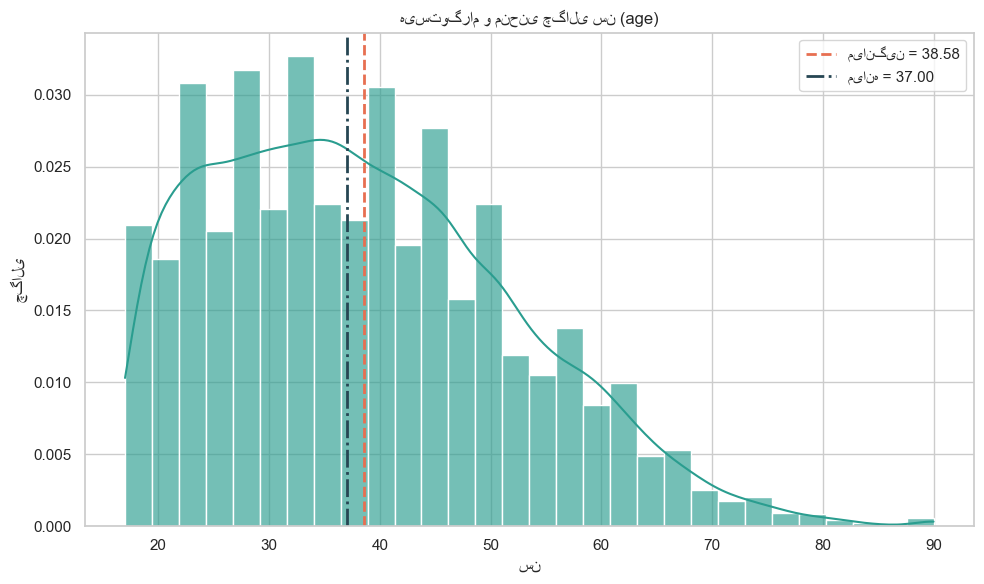

پاسخ نهایی سؤال ۲.۲: با توجه به چولگی عددی 0.5587 و مقایسهٔ میانگین و میانه، age در این داده «چوله به راست» است. نمودار نیز باید وجود دنباله و میزان تقارن را بررسی کند.


In [9]:
age_values = pd.to_numeric(adult["age"], errors="coerce").dropna()
age_skewness = age_values.skew()
age_mean = age_values.mean()
age_median = age_values.median()
age_mean_median_difference = age_mean - age_median

print(f"تعداد مشاهدات معتبر age: {len(age_values):,}")
print(f"چولگی age: {age_skewness:.6f}")
print(f"میانگین age: {age_mean:.6f}")
print(f"میانه age: {age_median:.6f}")
print(f"تفاوت میانگین و میانه: {age_mean_median_difference:.6f}")

if age_skewness > 0.5:
    age_skewness_category = "چوله به راست"
elif age_skewness < -0.5:
    age_skewness_category = "چوله به چپ"
else:
    age_skewness_category = "تقریباً متقارن"

print(
    "تفسیر عددی: بر اساس آستانهٔ تقریبی قراردادی ۰٫۵، "
    f"توزیع در دستهٔ «{age_skewness_category}» قرار می‌گیرد؛ "
    "این آستانه به‌تنهایی ملاک قطعی نیست."
)

plt.figure(figsize=(10, 6))
sns.histplot(age_values, bins=30, kde=True, stat="density", color="#2a9d8f", alpha=0.65)
plt.axvline(age_mean, color="#e76f51", linestyle="--", linewidth=2, label=f"میانگین = {age_mean:.2f}")
plt.axvline(age_median, color="#264653", linestyle="-.", linewidth=2, label=f"میانه = {age_median:.2f}")
plt.title("هیستوگرام و منحنی چگالی سن (age)")
plt.xlabel("سن")
plt.ylabel("چگالی")
plt.legend()
plt.tight_layout()
plt.show()

print(
    f"پاسخ نهایی سؤال ۲.۲: با توجه به چولگی عددی {age_skewness:.4f} "
    f"و مقایسهٔ میانگین و میانه، age در این داده «{age_skewness_category}» است. "
    "نمودار نیز باید وجود دنباله و میزان تقارن را بررسی کند."
)

#### تحلیل سؤال ۲.۲

در نمودار، ارتفاع میله‌ها فراوانی نسبی سن‌ها را نشان می‌دهد و منحنی KDE یک تقریب هموار از چگالی است. خطوط میانگین و میانه برای مقایسهٔ مکان مرکزی رسم شده‌اند. KDE برای خلاصه‌سازی دیداری مفید است، اما نتیجهٔ اصلی چولگی از مقدار `skew()` و شکل توزیع واقعی داده به دست می‌آید. اگر فاصلهٔ میانگین و میانه کم باشد، این فقط نشانه‌ای از تقارن نسبی است و نباید به‌تنهایی برای رد یا اثبات چولگی استفاده شود.

### سؤال ۲.۳ — بررسی نرمال بودن `education.num`

**صورت سؤال:**

«با رسم نمودار، توزیع ویژگی `education.num` را تحلیل کنید. آیا توزیع نرمال دارد؟»

در این سؤال ابتدا مقدارهای متمایز و فراوانی آن‌ها را بررسی می‌کنیم. ویژگی `education.num` در این دیتاست عددیِ گسسته است؛ بنابراین نمودار میله‌ای برای نمایش فراوانی هر سطح مناسب‌تر از تفسیر مستقیم یک منحنی پیوسته است. شباهت ظاهری به زنگوله به‌تنهایی به معنای نرمال‌بودن دقیق نیست.

تعداد مشاهدات معتبر education.num: 32,561
مقادیر متمایز و فراوانی هر مقدار:


,فراوانی
education-num,
1,51
2,168
3,333
4,646
5,514
6,933
7,1175
8,433
9,10501


چولگی education.num: -0.311676
میانگین: 10.080679 | میانه: 10.000000


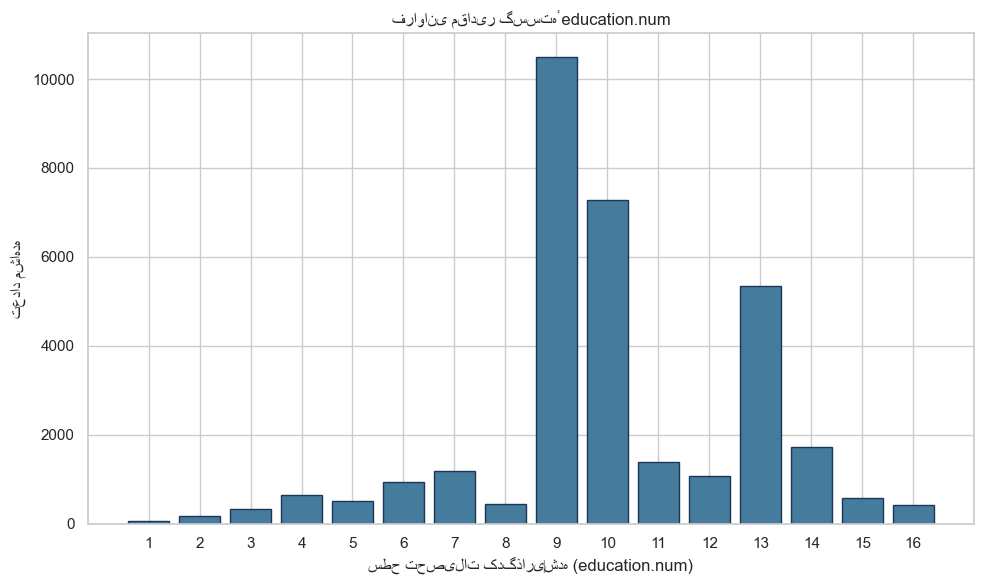

تحلیل نمودار: ویژگی گسسته است و بیشترین فراوانی در سطح/سطوح 9 دیده می‌شود. وجود تمرکز در چند سطح، فاصله‌های گسسته و شکل لزوماً نامتقارن، نرمال‌بودن دقیق را تأیید نمی‌کند.
پاسخ نهایی سؤال ۲.۳: بر اساس نمودار فراوانی واقعی، این ویژگی را نمی‌توان دارای توزیع نرمال دقیق دانست؛ هر شباهت کلی به زنگوله فقط تقریبی است.


In [10]:
education_num_values = pd.to_numeric(adult["education-num"], errors="coerce").dropna()
education_num_counts = education_num_values.value_counts().sort_index()

print(f"تعداد مشاهدات معتبر education.num: {len(education_num_values):,}")
print("مقادیر متمایز و فراوانی هر مقدار:")
display(education_num_counts.rename("فراوانی").to_frame())

education_num_skewness = education_num_values.skew()
education_num_mean = education_num_values.mean()
education_num_median = education_num_values.median()
print(f"چولگی education.num: {education_num_skewness:.6f}")
print(f"میانگین: {education_num_mean:.6f} | میانه: {education_num_median:.6f}")

plt.figure(figsize=(10, 6))
plt.bar(
    education_num_counts.index.astype(str),
    education_num_counts.values,
    color="#457b9d",
    edgecolor="#1d3557",
)
plt.title("فراوانی مقادیر گسستهٔ education.num")
plt.xlabel("سطح تحصیلات کدگذاری‌شده (education.num)")
plt.ylabel("تعداد مشاهده")
plt.tight_layout()
plt.show()

if education_num_counts.index.size >= 3:
    peak_count = education_num_counts.max()
    peak_levels = education_num_counts[education_num_counts == peak_count].index.tolist()
    peak_text = "، ".join(str(level) for level in peak_levels)
else:
    peak_text = "تعداد کافی برای تشخیص قله وجود ندارد"

print(
    f"تحلیل نمودار: ویژگی گسسته است و بیشترین فراوانی در سطح/سطوح {peak_text} دیده می‌شود. "
    "وجود تمرکز در چند سطح، فاصله‌های گسسته و شکل لزوماً نامتقارن، "
    "نرمال‌بودن دقیق را تأیید نمی‌کند."
)
print(
    "پاسخ نهایی سؤال ۲.۳: بر اساس نمودار فراوانی واقعی، این ویژگی را "
    "نمی‌توان دارای توزیع نرمال دقیق دانست؛ هر شباهت کلی به زنگوله فقط تقریبی است."
)

#### تحلیل سؤال ۲.۳

نمودار میله‌ای برای دادهٔ گسسته نشان می‌دهد کدام سطح‌های تحصیلی پرتکرارترند و آیا توزیع تک‌قله‌ای، چندقله‌ای یا نامتقارن است. در اینجا از KDE به‌عنوان مدرک نرمال‌بودن استفاده نمی‌کنیم، چون KDE یک تقریب پیوسته برای داده‌ای گسسته است و پهنای باند آن می‌تواند شکل ظاهری را تغییر دهد. بنابراین نتیجه‌گیری اصلی بر اساس فراوانی واقعی سطوح و تفاوت آن با یک منحنی زنگوله‌ای پیوسته انجام می‌شود.

### سؤال ۲.۴ — رسم و تفسیر نمودار جعبه‌ای برای `education.num`

**صورت سؤال:**

«ابتدا توضیح دهید نمودار جعبه‌ای (Boxplot) چگونه رسم می‌شود و چه مواردی را نمایش می‌دهد؟ سپس این نمودار را برای ویژگی `education.num` رسم کرده و آن را تفسیر کنید.»

در Boxplot، چارک اول `Q1`، میانه یا چارک دوم `Q2` و چارک سوم `Q3` محاسبه می‌شوند. جعبه از `Q1` تا `Q3` امتداد دارد و طول آن دامنهٔ بین‌چارکی یا `IQR = Q3 - Q1` است. در قاعدهٔ رایج `1.5 × IQR`، کران‌های مجاز برابر `Q1 - 1.5 × IQR` و `Q3 + 1.5 × IQR` هستند. سبیل‌ها تا دورترین مشاهدهٔ مجاز در این کران‌ها می‌روند و لزوماً تا کمینه و بیشینهٔ کل داده‌ها امتداد ندارند؛ نقاط بیرون از کران‌ها به‌عنوان پرت آماری نمایش داده می‌شوند.

,شاخص,مقدار
0,Q1,9.0
1,میانه (Q2),10.0
2,Q3,12.0
3,IQR,3.0
4,کران پایین,4.5
5,کران بالا,16.5


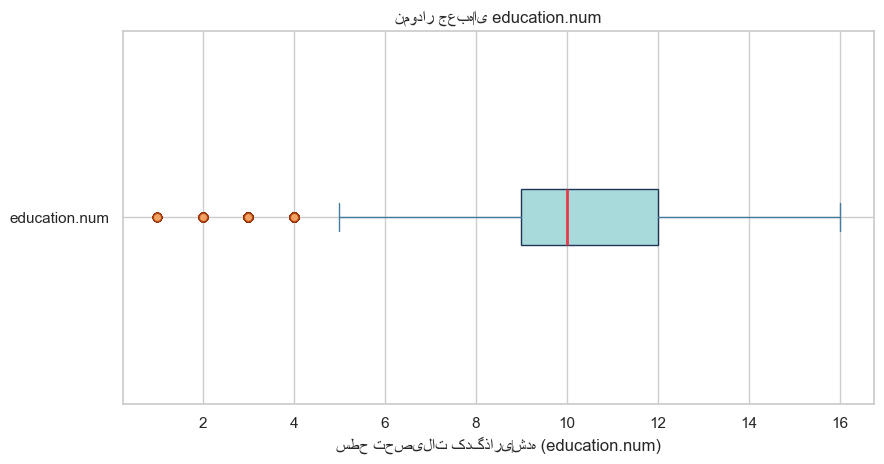

تفسیر Boxplot: میانه برابر 10 است و نیمی از مشاهدات بین 9 و 12 قرار دارند؛ IQR برابر 3 است.
سبیل‌ها بر اساس دورترین مقادیر مجاز در بازهٔ [4.5, 16.5] تعیین می‌شوند و 1,198 مشاهده طبق این قاعده پرت آماری‌اند. پرت آماری الزاماً به معنای خطای ثبت داده نیست.


In [11]:
education_num_q1 = education_num_values.quantile(0.25)
education_num_q2 = education_num_values.quantile(0.50)
education_num_q3 = education_num_values.quantile(0.75)
education_num_iqr = education_num_q3 - education_num_q1
education_num_lower_bound = education_num_q1 - 1.5 * education_num_iqr
education_num_upper_bound = education_num_q3 + 1.5 * education_num_iqr
education_num_non_outliers = education_num_values[
    education_num_values.between(education_num_lower_bound, education_num_upper_bound)
]
education_num_outliers = education_num_values[
    ~education_num_values.between(education_num_lower_bound, education_num_upper_bound)
]

question_24_summary = pd.DataFrame({
    "شاخص": ["Q1", "میانه (Q2)", "Q3", "IQR", "کران پایین", "کران بالا"],
    "مقدار": [
        education_num_q1,
        education_num_q2,
        education_num_q3,
        education_num_iqr,
        education_num_lower_bound,
        education_num_upper_bound,
    ],
})
display(question_24_summary)

plt.figure(figsize=(9, 4.8))
plt.boxplot(
    education_num_values,
    vert=False,
    patch_artist=True,
    boxprops={"facecolor": "#a8dadc", "color": "#1d3557"},
    medianprops={"color": "#e63946", "linewidth": 2},
    whiskerprops={"color": "#457b9d"},
    capprops={"color": "#457b9d"},
    flierprops={"marker": "o", "markerfacecolor": "#f4a261", "markeredgecolor": "#9c2f00", "alpha": 0.35},
)
plt.title("نمودار جعبه‌ای education.num")
plt.xlabel("سطح تحصیلات کدگذاری‌شده (education.num)")
plt.yticks([1], ["education.num"])
plt.tight_layout()
plt.show()

print(
    f"تفسیر Boxplot: میانه برابر {education_num_q2:g} است و نیمی از مشاهدات بین "
    f"{education_num_q1:g} و {education_num_q3:g} قرار دارند؛ IQR برابر {education_num_iqr:g} است."
)
print(
    f"سبیل‌ها بر اساس دورترین مقادیر مجاز در بازهٔ [{education_num_lower_bound:g}, "
    f"{education_num_upper_bound:g}] تعیین می‌شوند و {len(education_num_outliers):,} مشاهده "
    "طبق این قاعده پرت آماری‌اند. پرت آماری الزاماً به معنای خطای ثبت داده نیست."
)

#### تحلیل سؤال ۲.۴

جعبه بخش میانی توزیع و میانه را نشان می‌دهد؛ جابه‌جایی میانه درون جعبه و تفاوت طول سبیل‌ها می‌تواند دربارهٔ نامتقارنی توزیع اطلاعات بدهد. از آنجا که `education.num` گسسته است، هم‌پوشانی نقاط روی مقدارهای صحیح طبیعی است. نقاطی که Boxplot پرت نشان می‌دهد فقط با تعریف آماری `1.5 × IQR` پرت‌اند و بدون بررسی زمینهٔ داده نمی‌توان آن‌ها را خطای ثبت دانست.

### سؤال ۲.۵ — تشخیص داده‌های پرت با قاعدهٔ ۱٫۵ × IQR

**صورت سؤال:**

«با استفاده از معیار ۱٫۵ × IQR، داده‌های پرت ویژگی `education.num` را شناسایی کنید.»

با داده‌های معتبر `education.num`، ابتدا `Q1` و `Q3` و سپس رابطهٔ `IQR = Q3 - Q1` را محاسبه می‌کنیم. هر مشاهده‌ای که شرط دقیق `value < lower_bound` یا `value > upper_bound` را داشته باشد، پرت آماری محسوب می‌شود. چون ویژگی گسسته است، کران‌ها ممکن است اعشاری باشند و مقایسه همچنان با مقدار مشاهده‌شدهٔ واقعی انجام می‌شود.

In [12]:
question_25_summary = pd.DataFrame({
    "شاخص": [
        "Q1",
        "Q3",
        "IQR",
        "کران پایین",
        "کران بالا",
        "تعداد کل مشاهدات معتبر",
        "تعداد مشاهدات پرت",
        "درصد مشاهدات پرت",
    ],
    "مقدار": [
        education_num_q1,
        education_num_q3,
        education_num_iqr,
        education_num_lower_bound,
        education_num_upper_bound,
        len(education_num_values),
        len(education_num_outliers),
        education_num_outliers.size / len(education_num_values) * 100,
    ],
})
display(question_25_summary)

outlier_value_counts = education_num_outliers.value_counts().sort_index()
if outlier_value_counts.empty:
    print("هیچ مقدار پرت آماری با قاعدهٔ ۱٫۵ × IQR شناسایی نشد.")
else:
    print("مقادیر متمایز پرت و فراوانی هر مقدار:")
    display(outlier_value_counts.rename("فراوانی").to_frame())

print(
    f"شرط تشخیص: مقدار < {education_num_lower_bound:g} یا مقدار > "
    f"{education_num_upper_bound:g}. تعداد پرت‌ها {len(education_num_outliers):,} "
    f"از {len(education_num_values):,} مشاهده معتبر است."
)
print(
    "ارتباط با سؤال ۲.۴: نقاطی که Boxplot خارج از سبیل‌ها نشان می‌دهد با همین "
    "قاعده و همین چارک‌ها به‌دست می‌آیند؛ سبیل‌ها خودِ کمینه و بیشینه کل داده‌ها نیستند."
)

,شاخص,مقدار
0,Q1,9.000000
1,Q3,12.000000
2,IQR,3.000000
3,کران پایین,4.500000
4,کران بالا,16.500000
5,تعداد کل مشاهدات معتبر,32561.000000
6,تعداد مشاهدات پرت,1198.000000
7,درصد مشاهدات پرت,3.679248


مقادیر متمایز پرت و فراوانی هر مقدار:


,فراوانی
education-num,
1,51
2,168
3,333
4,646


شرط تشخیص: مقدار < 4.5 یا مقدار > 16.5. تعداد پرت‌ها 1,198 از 32,561 مشاهده معتبر است.
ارتباط با سؤال ۲.۴: نقاطی که Boxplot خارج از سبیل‌ها نشان می‌دهد با همین قاعده و همین چارک‌ها به‌دست می‌آیند؛ سبیل‌ها خودِ کمینه و بیشینه کل داده‌ها نیستند.


#### پاسخ تشریحی سؤال ۲.۵

این روش، پرت‌ها را نسبت به پراکندگی میانی داده و بدون فرض نرمال‌بودن شناسایی می‌کند. عدد اعشاری کران‌ها مشکلی ایجاد نمی‌کند، زیرا شرط روی مقدار مشاهده‌شده اعمال می‌شود. پرت‌بودن در اینجا یک برچسب آماری است و دربارهٔ درست یا نادرست بودن رکورد به‌تنهایی داوری نمی‌کند.

### سؤال ۲.۶ — مقایسه شکل توزیع `age` در گروه‌های درآمدی با Q-Q Plot

**صورت سؤال:**

«با استفاده از نمودار Q-Q Plot بررسی کنید آیا توزیع ویژگی `age` در گروه‌های درآمدی مختلف به یک شکل است یا خیر؟ نمودار خود را تفسیر کنید.»

در این سؤال، Q-Q Plot برای مقایسهٔ دو گروه ساخته می‌شود، نه برای آزمون جداگانهٔ نرمال‌بودن هر گروه. صدک‌های تجربی سن برای گروه‌های درآمدی روی یک شبکهٔ مشترک از احتمال‌ها محاسبه می‌شوند؛ صدک‌های گروه اول روی محور افقی و صدک‌های گروه دوم روی محور عمودی قرار می‌گیرند. نزدیکی نقاط به خط ۴۵ درجه یعنی صدک‌های متناظر مشابه‌اند، اما جابه‌جایی منظم نقاط می‌تواند تفاوت مکان و شیب متفاوت می‌تواند تفاوت پراکندگی را نشان دهد.

تعداد کل ردیف‌های دیتاست: 32,561
تعداد ردیف‌های حذف‌شده به دلیل age یا income گمشده/نامعتبر: 0
دسته‌های درآمدی واقعی پس از حذف ردیف‌های نامعتبر:


,تعداد
income,
<=50K,24720
>50K,7841


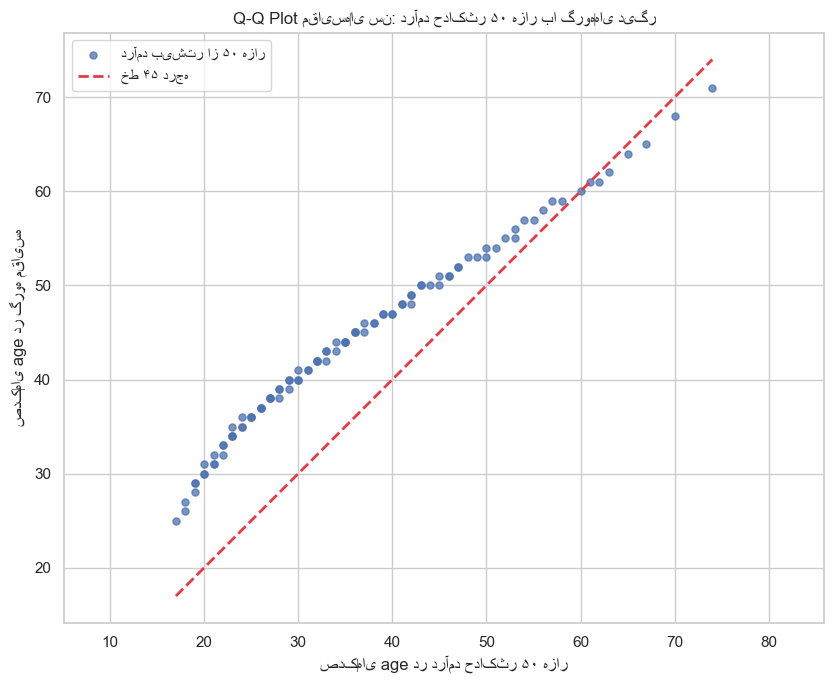

,گروه درآمدی,تعداد_مشاهدات,میانگین,میانه,انحراف_معیار
0,<=50K,24720,36.783738,34.0,14.020088
1,>50K,7841,44.249841,44.0,10.519028


همبستگی صدک‌های متناظر بین <=50K و >50K: 0.9919.
اختلاف صدک گروه مقایسه با گروه مرجع در صدک‌های ۱۰٪، ۵۰٪ و ۹۰٪: 10.00، 10.00 و 2.00 سال.
نتیجهٔ مقایسه: نقاط روند کلی منظم دارند، اما اختلاف صدک‌ها در طول نمودار ثابت نیست؛ بنابراین تفاوت مکان و/یا پراکندگی وجود دارد و شباهت شکل کامل نیست.
پاسخ نهایی سؤال ۲.۶: در این Q-Q Plot، نزدیک‌بودن کلی نقاط به خط ۴۵ درجه شباهت روند صدک‌ها را نشان می‌دهد، اما باید اختلاف صدک‌ها در چند بخش و آمار توصیفی نیز بررسی شود. بنابراین یکسان‌بودن کامل شکل توزیع‌ها از نمودار به‌تنهایی نتیجه نمی‌شود؛ نمودار فقط میزان پشتیبانی از شباهت شکل، تفاوت مکان و تفاوت پراکندگی را نشان می‌دهد.


In [13]:
income_age_data = adult[["age", "income"]].copy()
income_age_data["age"] = pd.to_numeric(income_age_data["age"], errors="coerce")
invalid_income_age_mask = income_age_data["age"].isna() | income_age_data["income"].isna()
income_age_valid = income_age_data.loc[~invalid_income_age_mask].copy()

print(f"تعداد کل ردیف‌های دیتاست: {len(income_age_data):,}")
print(f"تعداد ردیف‌های حذف‌شده به دلیل age یا income گمشده/نامعتبر: {int(invalid_income_age_mask.sum()):,}")
print("دسته‌های درآمدی واقعی پس از حذف ردیف‌های نامعتبر:")
display(income_age_valid["income"].value_counts().rename("تعداد").to_frame())

income_categories = income_age_valid["income"].value_counts().index.tolist()
preferred_income_order = [category for category in ["<=50K", ">50K"] if category in income_categories]
income_categories = preferred_income_order + [
    category for category in income_categories if category not in preferred_income_order
]
if len(income_categories) < 2:
    raise ValueError("برای Q-Q Plot مقایسه‌ای حداقل دو گروه درآمدی معتبر لازم است.")

income_labels = {
    "<=50K": "درآمد حداکثر ۵۰ هزار",
    ">50K": "درآمد بیشتر از ۵۰ هزار",
}
quantile_probabilities = np.linspace(0.01, 0.99, 99)
reference_income = income_categories[0]
reference_age = income_age_valid.loc[
    income_age_valid["income"] == reference_income, "age"
].to_numpy()
reference_quantiles = np.quantile(reference_age, quantile_probabilities)

plt.figure(figsize=(8.5, 7))
all_quantiles = [reference_quantiles]
comparison_correlations = {}
comparison_quantiles_by_income = {}
for comparison_income in income_categories[1:]:
    comparison_age = income_age_valid.loc[
        income_age_valid["income"] == comparison_income, "age"
    ].to_numpy()
    comparison_quantiles = np.quantile(comparison_age, quantile_probabilities)
    comparison_quantiles_by_income[comparison_income] = comparison_quantiles
    all_quantiles.append(comparison_quantiles)
    comparison_correlations[comparison_income] = np.corrcoef(
        reference_quantiles, comparison_quantiles
    )[0, 1]
    plt.scatter(
        reference_quantiles,
        comparison_quantiles,
        s=26,
        alpha=0.75,
        label=income_labels.get(comparison_income, str(comparison_income)),
    )

all_quantile_values = np.concatenate(all_quantiles)
line_min = all_quantile_values.min()
line_max = all_quantile_values.max()
plt.plot(
    [line_min, line_max],
    [line_min, line_max],
    linestyle="--",
    color="#e63946",
    linewidth=2,
    label="خط ۴۵ درجه",
)
plt.title(
    f"Q-Q Plot مقایسه‌ای سن: {income_labels.get(reference_income, reference_income)} با گروه‌های دیگر"
)
plt.xlabel(f"صدک‌های age در {income_labels.get(reference_income, reference_income)}")
plt.ylabel("صدک‌های age در گروه مقایسه")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.show()

income_age_summary = (
    income_age_valid.groupby("income")["age"]
    .agg(
        تعداد_مشاهدات="count",
        میانگین="mean",
        میانه="median",
        انحراف_معیار="std",
    )
    .reindex(income_categories)
    .reset_index()
    .rename(columns={"income": "گروه درآمدی"})
)
display(income_age_summary)

for comparison_income, correlation in comparison_correlations.items():
    comparison_quantiles = comparison_quantiles_by_income[comparison_income]
    quantile_differences = comparison_quantiles - reference_quantiles
    selected_probabilities = [0.10, 0.50, 0.90]
    selected_indices = [int(round(probability * 100)) - 1 for probability in selected_probabilities]
    selected_differences = quantile_differences[selected_indices]
    print(
        f"همبستگی صدک‌های متناظر بین {reference_income} و {comparison_income}: "
        f"{correlation:.4f}."
    )
    print(
        "اختلاف صدک گروه مقایسه با گروه مرجع "
        f"در صدک‌های ۱۰٪، ۵۰٪ و ۹۰٪: "
        f"{selected_differences[0]:.2f}، {selected_differences[1]:.2f} و "
        f"{selected_differences[2]:.2f} سال."
    )
    if np.ptp(quantile_differences) > 2:
        print(
            "نتیجهٔ مقایسه: نقاط روند کلی منظم دارند، اما اختلاف صدک‌ها در طول نمودار "
            "ثابت نیست؛ بنابراین تفاوت مکان و/یا پراکندگی وجود دارد و شباهت شکل کامل نیست."
        )
    else:
        print(
            "نتیجهٔ مقایسه: اختلاف صدک‌ها تقریباً ثابت است؛ شواهد نمودار با شکل‌های "
            "نسبتاً مشابه و تفاوت عمدتاً مکانی سازگار است."
        )

print(
    "پاسخ نهایی سؤال ۲.۶: در این Q-Q Plot، نزدیک‌بودن کلی نقاط به خط ۴۵ درجه "
    "شباهت روند صدک‌ها را نشان می‌دهد، اما باید اختلاف صدک‌ها در چند بخش و آمار توصیفی "
    "نیز بررسی شود. بنابراین یکسان‌بودن کامل شکل توزیع‌ها از نمودار به‌تنهایی نتیجه نمی‌شود؛ "
    "نمودار فقط میزان پشتیبانی از شباهت شکل، تفاوت مکان و تفاوت پراکندگی را نشان می‌دهد."
)

#### تحلیل و پاسخ تشریحی سؤال ۲.۶

در این مقایسه باید سه مفهوم جداگانه در نظر گرفته شود: **شکل توزیع** به الگوی کلی صدک‌ها و انحنا مربوط است، **مکان توزیع** به جابه‌جایی میانگین یا میانه مربوط می‌شود و **پراکندگی** به فاصلهٔ مقادیر و انحراف معیار مربوط است. اگر نقاط در بخشی از نمودار از خط مرجع فاصله بگیرند، ممکن است شکل توزیع در دم‌ها یا در بخش مرکزی متفاوت باشد؛ این انحراف به‌تنهایی اثبات قطعی یکسان یا متفاوت‌بودن کامل توزیع‌ها نیست. مقدارهای `age` و `income` گمشده یا نامعتبر در کد کنار گذاشته و تعداد آن‌ها گزارش شده‌اند.

#### پاسخ مستقیم بله/خیر به سؤال ۲.۶

**خیر.** شکل توزیع `age` در گروه‌های درآمدی کاملاً یکسان نیست. نمودار Q-Q شباهت کلی روند صدک‌ها را نشان می‌دهد، اما اختلاف صدک‌ها در بخش‌های مختلف ثابت نیست و آمار توصیفی نیز تفاوت مکان و پراکندگی دو گروه را نشان می‌دهد. بنابراین پاسخ دقیق‌تر این است: **شباهت نسبی وجود دارد، اما یکسان‌بودن کامل شکل توزیع‌ها تأیید نمی‌شود.**

## بخش ۳: بررسی شباهت بین داده‌ها

در این بخش، سطر nام دیتاست به‌عنوان فرد شماره n در نظر گرفته می‌شود؛ بنابراین انتخاب فرد شماره n با `iloc[n-1]` انجام می‌شود. این فرض برای همهٔ سؤال‌های بخش ۳ یکسان است. نام‌های صورت سؤال به نام ستون‌های واقعی نگاشت می‌شوند و دادهٔ اصلی بدون تغییر باقی می‌ماند.

### سؤال ۳.۱ — فاصلهٔ اقلیدسی و منهتن

**صورت سؤال:**

«با استفاده از ویژگی‌های `age`، `hours.per.week` و `education.num`، فاصلهٔ اقلیدسی (Euclidean Distance) و فاصلهٔ منهتن (Manhattan Distance) بین دو فرد شمارهٔ ۲۷ و ۸۱ را محاسبه کنید. توضیح دهید تفاوت این دو معیار در چیست؟»

برای فرد شمارهٔ `n` از سطر `n-1` در pandas استفاده می‌کنیم. اگر بردارهای دو فرد را `x` و `y` بنامیم، فرمول فاصلهٔ اقلیدسی برابر است با:

$$d_E(x,y)=\sqrt{\sum_i(x_i-y_i)^2}$$

و فاصلهٔ منهتن از رابطهٔ زیر به دست می‌آید:

$$d_M(x,y)=\sum_i|x_i-y_i|$$

فاصلهٔ اقلیدسی طول مستقیم بین دو نقطه را اندازه می‌گیرد، درحالی‌که فاصلهٔ منهتن مجموع حرکت‌های مطلق در هر بُعد است. چون این معیارها به مقیاس حساس‌اند، ویژگی‌ای با دامنهٔ عددی بزرگ‌تر می‌تواند سهم بیشتری در فاصله داشته باشد.

In [14]:
question_31_columns = {
    "age": "age",
    "hours.per.week": "hours-per-week",
    "education.num": "education-num",
}
missing_question_31_columns = [
    column for column in question_31_columns.values() if column not in adult.columns
]
if missing_question_31_columns:
    raise KeyError(f"ستون‌های سؤال ۳.۱ پیدا نشدند: {missing_question_31_columns}")

person_27 = adult.iloc[26]
person_81 = adult.iloc[80]
question_31_features = list(question_31_columns)
question_31_pair = pd.DataFrame(
    {
        "فرد شماره ۲۷": [person_27[column] for column in question_31_columns.values()],
        "فرد شماره ۸۱": [person_81[column] for column in question_31_columns.values()],
    },
    index=question_31_features,
)
question_31_pair.index.name = "ویژگی"
print("مقادیر واقعی ویژگی‌ها برای افراد ۲۷ و ۸۱:")
display(question_31_pair)

question_31_values_27 = question_31_pair["فرد شماره ۲۷"].astype(float).to_numpy()
question_31_values_81 = question_31_pair["فرد شماره ۸۱"].astype(float).to_numpy()
question_31_difference = question_31_values_27 - question_31_values_81
question_31_breakdown = pd.DataFrame(
    {
        "اختلاف (فرد ۲۷ منهای فرد ۸۱)": question_31_difference,
        "قدر مطلق اختلاف": np.abs(question_31_difference),
        "مربع اختلاف": question_31_difference**2,
    },
    index=question_31_features,
)
question_31_breakdown.index.name = "ویژگی"
display(question_31_breakdown)

question_31_euclidean = float(np.sqrt(np.sum(question_31_difference**2)))
question_31_manhattan = float(np.sum(np.abs(question_31_difference)))
question_31_independent = pd.Series(
    {
        "فاصله اقلیدسی": np.linalg.norm(question_31_values_27 - question_31_values_81),
        "فاصله منهتن": np.abs(question_31_values_27 - question_31_values_81).sum(),
    }
)
print(f"فاصلهٔ اقلیدسی: {question_31_euclidean:.4f}")
print(f"فاصلهٔ منهتن: {question_31_manhattan:.4f}")
print("بررسی مستقل با NumPy:")
display(question_31_independent.to_frame("مقدار"))

مقادیر واقعی ویژگی‌ها برای افراد ۲۷ و ۸۱:


,فرد شماره ۲۷,فرد شماره ۸۱
ویژگی,,
age,19,18
hours.per.week,40,30
education.num,9,9


,اختلاف (فرد ۲۷ منهای فرد ۸۱),قدر مطلق اختلاف,مربع اختلاف
ویژگی,,,
age,1.0,1.0,1.0
hours.per.week,10.0,10.0,100.0
education.num,0.0,0.0,0.0


فاصلهٔ اقلیدسی: 10.0499
فاصلهٔ منهتن: 11.0000
بررسی مستقل با NumPy:


,مقدار
فاصله اقلیدسی,10.049876
فاصله منهتن,11.000000


#### پاسخ نهایی سؤال ۳.۱

خروجی سلول قبل، مقادیر واقعی دو فرد، اختلاف هر ویژگی و دو فاصله را نمایش می‌دهد. فاصلهٔ اقلیدسی با جمع مربعات اختلاف‌ها و گرفتن ریشه محاسبه شد؛ فاصلهٔ منهتن مجموع قدرمطلق اختلاف‌هاست. بنابراین این دو مقدار از نظر تعریف و واحد با هم یکسان نیستند و پیش از مقایسهٔ افراد مختلف، اثر مقیاس ویژگی‌ها باید در نظر گرفته شود.

### سؤال ۳.۲ — محاسبهٔ مجدد فاصله‌ها پس از استانداردسازی

**صورت سؤال:**

«در این مرحله ابتدا ویژگی‌هایی را که در بخش قبل گفته شد با استفاده از Z-score استاندارد کنید؛ سپس مجدداً محاسبات خود را انجام دهید. نتایج به‌دست‌آمده را با بخش قبلی مقایسه و تحلیل کنید.»

برای هر ویژگی از کل داده‌های معتبر دیتاست میانگین و انحراف معیار محاسبه می‌کنیم و سپس از رابطهٔ زیر استفاده می‌کنیم:

$$z_i=\frac{x_i-\mu_i}{\sigma_i}$$

در این سؤال از `ddof=0` استفاده می‌شود؛ یعنی انحراف معیار جامعه‌ای بر اساس کل دادهٔ معتبر دیتاست. این انتخاب با تعریف رایج `StandardScaler` سازگار است. استانداردسازی اثر اختلاف واحد و دامنهٔ ویژگی‌ها را کاهش می‌دهد؛ بنابراین فاصلهٔ استانداردشده را نباید از نظر واحد اندازه‌گیری مستقیماً با فاصلهٔ خام مقایسه کرد.

In [15]:
question_32_data = adult[list(question_31_columns.values())].apply(pd.to_numeric, errors="coerce")
question_32_valid = question_32_data.dropna()
question_32_means = question_32_valid.mean()
question_32_stds = question_32_valid.std(ddof=0)
if (question_32_stds == 0).any():
    raise ValueError("استانداردسازی ویژگی با انحراف معیار صفر ممکن نیست.")

question_32_pair_raw = question_32_data.iloc[[26, 80]]
question_32_pair_standardized = (question_32_pair_raw - question_32_means) / question_32_stds
question_32_pair_standardized.index = ["فرد شماره ۲۷", "فرد شماره ۸۱"]
question_32_standardization_table = pd.DataFrame(
    {
        "میانگین کل داده معتبر": question_32_means.to_numpy(),
        "انحراف معیار جامعه‌ای (ddof=0)": question_32_stds.to_numpy(),
    },
    index=question_31_features,
)
question_32_standardization_table.index.name = "ویژگی"
print("پارامترهای استانداردسازی هر ویژگی:")
display(question_32_standardization_table)
print("مقادیر استانداردشدهٔ دو فرد:")
display(question_32_pair_standardized.rename(columns=dict(zip(question_31_columns.values(), question_31_features))))

question_32_values_27 = question_32_pair_standardized.iloc[0].to_numpy()
question_32_values_81 = question_32_pair_standardized.iloc[1].to_numpy()
question_32_euclidean = float(np.linalg.norm(question_32_values_27 - question_32_values_81))
question_32_manhattan = float(np.abs(question_32_values_27 - question_32_values_81).sum())
question_32_comparison = pd.DataFrame(
    {
        "فاصله اقلیدسی": [question_31_euclidean, question_32_euclidean],
        "فاصله منهتن": [question_31_manhattan, question_32_manhattan],
    },
    index=["داده خام", "داده استانداردشده"],
)
print("مقایسهٔ فاصله‌های خام و استانداردشده:")
display(question_32_comparison)
print(f"فاصلهٔ اقلیدسی استانداردشده: {question_32_euclidean:.4f}")
print(f"فاصلهٔ منهتن استانداردشده: {question_32_manhattan:.4f}")

پارامترهای استانداردسازی هر ویژگی:


,میانگین کل داده معتبر,انحراف معیار جامعه‌ای (ddof=0)
ویژگی,,
age,38.581647,13.640223
hours.per.week,40.437456,12.347239
education.num,10.080679,2.572681


مقادیر استانداردشدهٔ دو فرد:


,age,hours.per.week,education.num
فرد شماره ۲۷,-1.435581,-0.035429,-0.42006
فرد شماره ۸۱,-1.508894,-0.845327,-0.42006


مقایسهٔ فاصله‌های خام و استانداردشده:


,فاصله اقلیدسی,فاصله منهتن
داده خام,10.049876,11.00000
داده استانداردشده,0.813209,0.88321


فاصلهٔ اقلیدسی استانداردشده: 0.8132
فاصلهٔ منهتن استانداردشده: 0.8832


#### پاسخ نهایی سؤال ۳.۲

فاصله‌های جدید از مقادیر استانداردشدهٔ همان سه ویژگی به دست آمدند و در جدول مقایسه‌ای کنار فاصله‌های خام قرار گرفتند. پس از استانداردسازی، ویژگی‌ها در مقیاس قابل مقایسه‌تری قرار می‌گیرند و ویژگی دارای دامنهٔ بزرگ‌تر دیگر صرفاً به دلیل واحد اندازه‌گیری بر فاصله غالب نمی‌شود. تغییر مقدار فاصله به معنی تغییر واحد و مبنای محاسبه است، نه تغییر افراد یا دادهٔ اصلی.

### سؤال ۳.۳ — محاسبهٔ تفاوت داده‌های اسمی

**صورت سؤال:**

«با استفاده از ویژگی‌های `occupation`، `marital.status` و `workclass`، میزان تفاوت (Dissimilarity) بین دو فرد شمارهٔ ۲ و ۴ را محاسبه کنید.»

هر سه ویژگی اسمی هستند. برای هر ویژگی، اگر دو مقدار برابر باشند تفاوت آن ویژگی صفر و اگر متفاوت باشند تفاوت آن یک است:

$$d_k(x,y)=\begin{cases}0 & x_k=y_k\\1 & x_k\ne y_k\end{cases}$$

در نبود وزن خاص، تفاوت کلی میانگین تفاوت‌های معتبر سه ویژگی است. در این روش هیچ ترتیب یا اختلاف عددی مصنوعی بین دسته‌ها فرض نمی‌شود.

In [16]:
question_33_columns = {
    "occupation": "occupation",
    "marital.status": "marital-status",
    "workclass": "workclass",
}
person_2 = adult.iloc[1]
person_4 = adult.iloc[3]
question_33_rows = []
for feature_name, column_name in question_33_columns.items():
    value_2 = person_2[column_name]
    value_4 = person_4[column_name]
    missing_value = pd.isna(value_2) or pd.isna(value_4)
    difference = np.nan if missing_value else float(value_2 != value_4)
    question_33_rows.append(
        {
            "ویژگی": feature_name,
            "فرد شماره ۲": value_2,
            "فرد شماره ۴": value_4,
            "میزان تفاوت": difference,
        }
    )
question_33_table = pd.DataFrame(question_33_rows)
print("مقایسهٔ ویژگی‌های اسمی افراد ۲ و ۴:")
display(question_33_table)

question_33_valid_differences = question_33_table["میزان تفاوت"].dropna()
question_33_dissimilarity = float(question_33_valid_differences.mean())
question_33_same_count = int((question_33_valid_differences == 0).sum())
question_33_different_count = int((question_33_valid_differences == 1).sum())
question_33_independent = float(
    sum(question_33_valid_differences.tolist()) / len(question_33_valid_differences)
)
print(f"تعداد ویژگی‌های یکسان: {question_33_same_count}")
print(f"تعداد ویژگی‌های متفاوت: {question_33_different_count}")
print(f"تفاوت کلی: {question_33_dissimilarity:.4f}")
print(f"بررسی مستقل با میانگین تفاوت‌ها: {question_33_independent:.4f}")

مقایسهٔ ویژگی‌های اسمی افراد ۲ و ۴:


,ویژگی,فرد شماره ۲,فرد شماره ۴,میزان تفاوت
0,occupation,Exec-managerial,Handlers-cleaners,1.0
1,marital.status,Married-civ-spouse,Married-civ-spouse,0.0
2,workclass,Self-emp-not-inc,Private,1.0


تعداد ویژگی‌های یکسان: 1
تعداد ویژگی‌های متفاوت: 2
تفاوت کلی: 0.6667
بررسی مستقل با میانگین تفاوت‌ها: 0.6667


#### پاسخ نهایی سؤال ۳.۳

مقدار تفاوت کلی در خروجی کد، میانگین سه تفاوت اسمی است. مقدار صفر یعنی سه ویژگی در دو فرد یکسان‌اند و مقدار یک یعنی هر سه متفاوت‌اند؛ مقدارهای بین صفر و یک سهم ویژگی‌های متفاوت را نشان می‌دهند. این معیار به‌جای اختلاف عددی، فقط برابری یا نابرابری دسته‌ها را بررسی می‌کند.

### سؤال ۳.۴ — محاسبهٔ دستی شباهت کسینوسی

**صورت سؤال:**

«شباهت کسینوسی (Cosine Similarity) بین دو فرد شمارهٔ ۳۲ و ۶۴ را با استفاده از ویژگی‌های `age` و `education.num` به‌صورت دستی محاسبه کنید. سپس آن را روی نمودار نشان دهید.»

دو فرد به‌صورت بردارهای دوبعدی تعریف می‌شوند:

$$x=[age_{32},education.num_{32}],\qquad y=[age_{64},education.num_{64}]$$

فرمول شباهت کسینوسی چنین است:

$$cos(x,y)=\frac{x\cdot y}{\|x\|\times\|y\|}$$

در اینجا مقادیر ویژگی‌ها مستقیماً مؤلفه‌های بردارند؛ بنابراین نتیجه به نحوهٔ نمایش و مقیاس داده‌ها وابسته است. شباهت کسینوسی زاویهٔ بین بردارها را می‌سنجد و شباهت بالا الزاماً به معنای فاصلهٔ اقلیدسی کم نیست.

مقادیر واقعی بردارهای دو فرد:


,فرد شماره ۳۲,فرد شماره ۶۴
ویژگی,,
age,20.0,42.0
education.num,10.0,16.0


,مرحله,مقدار
0,ضرب داخلی,1000.000000
1,نرم فرد ۳۲,22.360680
2,نرم فرد ۶۴,44.944410
3,حاصل‌ضرب نرم‌ها,1004.987562
4,شباهت کسینوسی,0.995037


شباهت کسینوسی دستی: 0.9950
شباهت کسینوسی با پیاده‌سازی مستقل: 0.9950


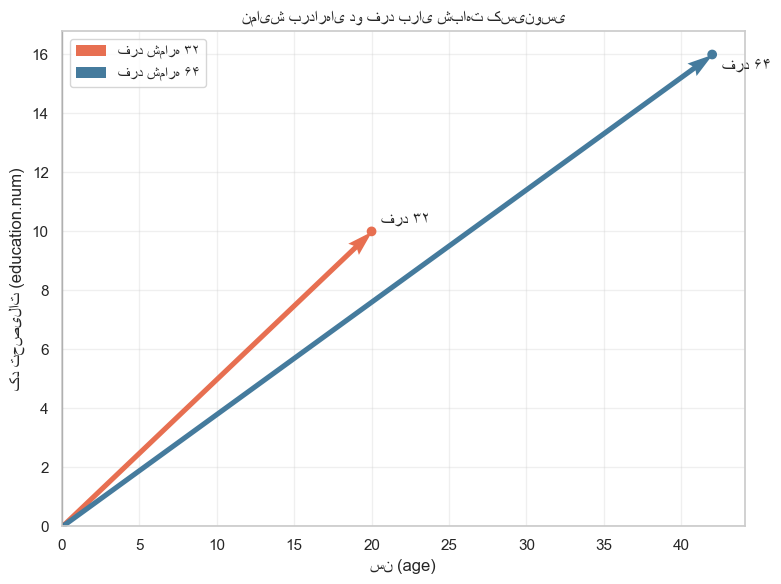

In [17]:
question_34_columns = {
    "age": "age",
    "education.num": "education-num",
}
person_32 = adult.iloc[31]
person_64 = adult.iloc[63]
question_34_vector_32 = np.array(
    [float(person_32[column]) for column in question_34_columns.values()]
)
question_34_vector_64 = np.array(
    [float(person_64[column]) for column in question_34_columns.values()]
)
question_34_values = pd.DataFrame(
    {
        "فرد شماره ۳۲": question_34_vector_32,
        "فرد شماره ۶۴": question_34_vector_64,
    },
    index=list(question_34_columns),
)
question_34_values.index.name = "ویژگی"
print("مقادیر واقعی بردارهای دو فرد:")
display(question_34_values)

question_34_dot_product = float(np.dot(question_34_vector_32, question_34_vector_64))
question_34_norm_32 = float(np.linalg.norm(question_34_vector_32))
question_34_norm_64 = float(np.linalg.norm(question_34_vector_64))
question_34_denominator = question_34_norm_32 * question_34_norm_64
question_34_cosine_manual = question_34_dot_product / question_34_denominator
question_34_cosine_independent = float(
    np.dot(question_34_vector_32, question_34_vector_64)
    / (np.linalg.norm(question_34_vector_32) * np.linalg.norm(question_34_vector_64))
)
question_34_steps = pd.DataFrame(
    {
        "مرحله": ["ضرب داخلی", "نرم فرد ۳۲", "نرم فرد ۶۴", "حاصل‌ضرب نرم‌ها", "شباهت کسینوسی"],
        "مقدار": [
            question_34_dot_product,
            question_34_norm_32,
            question_34_norm_64,
            question_34_denominator,
            question_34_cosine_manual,
        ],
    }
)
display(question_34_steps)
print(f"شباهت کسینوسی دستی: {question_34_cosine_manual:.4f}")
print(f"شباهت کسینوسی با پیاده‌سازی مستقل: {question_34_cosine_independent:.4f}")

plt.figure(figsize=(8, 6))
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.quiver(
    0,
    0,
    question_34_vector_32[0],
    question_34_vector_32[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="#e76f51",
    label="فرد شماره ۳۲",
)
plt.quiver(
    0,
    0,
    question_34_vector_64[0],
    question_34_vector_64[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="#457b9d",
    label="فرد شماره ۶۴",
)
plt.scatter(
    [question_34_vector_32[0], question_34_vector_64[0]],
    [question_34_vector_32[1], question_34_vector_64[1]],
    color=["#e76f51", "#457b9d"],
)
plt.annotate("فرد ۳۲", question_34_vector_32, xytext=(7, 5), textcoords="offset points")
plt.annotate("فرد ۶۴", question_34_vector_64, xytext=(7, -12), textcoords="offset points")
plt.title("نمایش بردارهای دو فرد برای شباهت کسینوسی")
plt.xlabel("سن (age)")
plt.ylabel("کد تحصیلات (education.num)")
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### پاسخ نهایی سؤال ۳.۴

محاسبهٔ دستی شامل ضرب داخلی، نرم اقلیدسی هر بردار و تقسیم ضرب داخلی بر حاصل‌ضرب نرم‌هاست. مقدار نهایی و مقدار پیاده‌سازی مستقل باید در خروجی برابر باشند. نمودار، هر دو بردار را از مبدأ نشان می‌دهد؛ زاویهٔ کوچک‌تر میان آن‌ها به شباهت کسینوسی بیشتر مربوط است، اما طول بردارها و فاصلهٔ اقلیدسی اطلاعات متفاوتی را بیان می‌کنند.

### سؤال ۳.۵ — مزیت شباهت کسینوسی نسبت به معیارهای فاصله‌ای

**صورت سؤال:**

«توضیح دهید شباهت کسینوسی (Cosine Similarity) چه مزیتی نسبت به معیارهای فاصله‌ای دارد؟»

فاصله‌های اقلیدسی و منهتن اختلاف مختصات را اندازه می‌گیرند، اما شباهت کسینوسی جهت دو بردار یا زاویهٔ بین آن‌ها را مقایسه می‌کند. به همین دلیل در داده‌های پُربُعد مانند بردارهای متنی، بازیابی اطلاعات، مقایسهٔ اسناد و سیستم‌های پیشنهاددهنده مفید است؛ دو بردار با جهت مشابه می‌توانند شباهت بالایی داشته باشند، حتی اگر اندازه‌هایشان متفاوت باشد.

این معیار محدودیت هم دارد: اندازهٔ بردار را مستقیماً وارد نمی‌کند، برای بردار صفر تعریف نشده است و در داده‌هایی که صفر و مبدأ معنای مهمی دارند، زاویه همیشه بهترین خلاصهٔ شباهت نیست. مثال عددی زیر آموزشی است و با افراد واقعی دیتاست اشتباه نمی‌شود.

In [18]:
educational_vector_a = np.array([1.0, 2.0])
educational_vector_b = np.array([2.0, 4.0])
educational_cosine = float(
    np.dot(educational_vector_a, educational_vector_b)
    / (np.linalg.norm(educational_vector_a) * np.linalg.norm(educational_vector_b))
)
educational_euclidean = float(np.linalg.norm(educational_vector_a - educational_vector_b))
educational_example = pd.DataFrame(
    {
        "بردار اول": educational_vector_a,
        "بردار دوم": educational_vector_b,
    },
    index=["مؤلفه اول", "مؤلفه دوم"],
)
display(educational_example)
print(f"مثال آموزشی - شباهت کسینوسی: {educational_cosine:.4f}")
print(f"مثال آموزشی - فاصله اقلیدسی: {educational_euclidean:.4f}")

,بردار اول,بردار دوم
مؤلفه اول,1.0,2.0
مؤلفه دوم,2.0,4.0


مثال آموزشی - شباهت کسینوسی: 1.0000
مثال آموزشی - فاصله اقلیدسی: 2.2361


#### پاسخ نهایی سؤال ۳.۵

مزیت اصلی شباهت کسینوسی این است که جهت بردارها را جدا از اندازهٔ آن‌ها مقایسه می‌کند؛ بنابراین برای بردارهای پُربُعد و پراکنده، مانند نمایش اسناد، اغلب مناسب‌تر از فاصلهٔ خام است. در مثال آموزشی، بردارهای `[1, 2]` و `[2, 4]` هم‌جهت‌اند، پس شباهت کسینوسی آن‌ها `۱` است، درحالی‌که فاصلهٔ اقلیدسی‌شان مثبت است. در مقابل، اگر بزرگی و فاصلهٔ واقعی اهمیت اصلی داشته باشد، معیارهای فاصله‌ای مناسب‌ترند.

### سؤال ۳.۶ — فاصلهٔ داده‌های ترکیبی (Mixed Types)

**صورت سؤال:**

«برای ترکیبی از ویژگی‌های عددی (`age` و `education.num`)، باینری (`sex`) و اسمی (`marital.status`)، فاصلهٔ بین افراد شمارهٔ ۵ و ۱۲۵ را با استفاده از فرمول داده‌های ترکیبی (Mixed Types) محاسبه کنید.»

در فایل‌های پروژه فرمول اختصاصی دیگری برای فاصلهٔ داده‌های ترکیبی پیدا نشد؛ بنابراین در این سؤال، **Gower Dissimilarity** با وزن برابر برای چهار ویژگی به‌عنوان فرض روش‌شناختی استفاده می‌شود. برای ویژگی عددی، اختلاف مطلق بر دامنهٔ همان ویژگی در کل دادهٔ معتبر تقسیم می‌شود. برای ویژگی‌های باینری و اسمی، برابری تفاوت صفر و نابرابری تفاوت یک است. فرمول کلی با وزن‌های برابر چنین است:

$$D(x,y)=\frac{\sum_k w_k d_k(x,y)}{\sum_k w_k}$$

اگر مقداری گمشده باشد، آن ویژگی معتبر نیست و در صورت و مخرج میانگین وارد نمی‌شود. اگر دامنهٔ عددی صفر باشد، تفاوت آن ویژگی صفر در نظر گرفته می‌شود، چون تمام مقدارهای معتبر آن یکسان‌اند.

In [19]:
question_36_columns = {
    "age": ("age", "عددی"),
    "education.num": ("education-num", "عددی"),
    "sex": ("sex", "باینری"),
    "marital.status": ("marital-status", "اسمی"),
}
person_5 = adult.iloc[4]
person_125 = adult.iloc[124]
question_36_rows = []
question_36_contributions = []

for feature_name, (column_name, feature_type) in question_36_columns.items():
    value_5 = person_5[column_name]
    value_125 = person_125[column_name]
    missing_value = pd.isna(value_5) or pd.isna(value_125)
    if missing_value:
        contribution = np.nan
        method = "مقدار گمشده؛ در میانگین وارد نشد"
    elif feature_type == "عددی":
        valid_numeric = pd.to_numeric(adult[column_name], errors="coerce").dropna()
        feature_range = float(valid_numeric.max() - valid_numeric.min())
        if feature_range == 0:
            contribution = 0.0
            method = "عددی؛ دامنه صفر، تفاوت نهایی صفر"
        else:
            contribution = abs(float(value_5) - float(value_125)) / feature_range
            method = f"عددی؛ قدرمطلق اختلاف تقسیم بر دامنه {feature_range:g}"
    else:
        contribution = float(value_5 != value_125)
        method = "دسته‌ای؛ صفر برای برابری و یک برای نابرابری"
    question_36_contributions.append(contribution)
    question_36_rows.append(
        {
            "ویژگی": feature_name,
            "نوع داده": feature_type,
            "مقدار فرد شماره ۵": value_5,
            "مقدار فرد شماره ۱۲۵": value_125,
            "روش محاسبه": method,
            "تفاوت نهایی ویژگی": contribution,
        }
    )

question_36_table = pd.DataFrame(question_36_rows)
print("مقادیر واقعی افراد ۵ و ۱۲۵:")
display(question_36_table)

question_36_valid_contributions = pd.Series(question_36_contributions).dropna()
question_36_gower = float(question_36_valid_contributions.mean())
question_36_independent = float(
    sum(question_36_valid_contributions.tolist()) / len(question_36_valid_contributions)
)
print(f"تعداد ویژگی‌های معتبر در محاسبه: {len(question_36_valid_contributions)} از ۴")
print(f"فاصلهٔ ترکیبی Gower با وزن برابر: {question_36_gower:.4f}")
print(f"بررسی مستقل با میانگین سهم ویژگی‌ها: {question_36_independent:.4f}")

مقادیر واقعی افراد ۵ و ۱۲۵:


,ویژگی,نوع داده,مقدار فرد شماره ۵,مقدار فرد شماره ۱۲۵,روش محاسبه,تفاوت نهایی ویژگی
0,age,عددی,28,19,عددی؛ قدرمطلق اختلاف تقسیم بر دامنه 73,0.123288
1,education.num,عددی,13,10,عددی؛ قدرمطلق اختلاف تقسیم بر دامنه 15,0.200000
2,sex,باینری,Female,Male,دسته‌ای؛ صفر برای برابری و یک برای ن...,1.000000
3,marital.status,اسمی,Married-civ-spouse,Never-married,دسته‌ای؛ صفر برای برابری و یک برای ن...,1.000000


تعداد ویژگی‌های معتبر در محاسبه: 4 از ۴
فاصلهٔ ترکیبی Gower با وزن برابر: 0.5808
بررسی مستقل با میانگین سهم ویژگی‌ها: 0.5808


#### پاسخ نهایی سؤال ۳.۶

فاصلهٔ نهایی Gower میانگین سهم چهار ویژگی معتبر است و در خروجی عددی گزارش شده است. سهم ویژگی‌های عددی پس از تقسیم بر دامنه در بازهٔ صفر تا یک قرار دارد؛ ویژگی‌های `sex` و `marital.status` نیز با مقایسهٔ اسمی/باینری به صفر یا یک تبدیل شده‌اند. این نرمال‌سازی اجازه می‌دهد تفاوت‌های عددی و دسته‌ای در یک معیار واحد ترکیب شوند، بدون اینکه ترتیب ساختگی برای دسته‌ها فرض شود.

## جمع‌بندی بخش ۳

در این بخش فاصلهٔ اقلیدسی و منهتن برای داده‌های عددی، فاصلهٔ همان ویژگی‌ها پس از استانداردسازی، تفاوت اسمی برای داده‌های دسته‌ای، شباهت کسینوسی برای بردارها و فاصلهٔ Gower برای داده‌های ترکیبی استفاده شد. جدول زیر خلاصهٔ نتایج محاسبه‌شدهٔ واقعی را پس از اجرای کد نشان می‌دهد.

In [20]:
question_3_summary = pd.DataFrame(
    {
        "سؤال": ["۳.۱", "۳.۲", "۳.۳", "۳.۴", "۳.۵", "۳.۶"],
        "معیار/نتیجه اصلی": [
            "اقلیدسی و منهتن روی داده خام",
            "اقلیدسی و منهتن پس از Z-score",
            "تفاوت اسمی",
            "شباهت کسینوسی",
            "مثال جهت یکسان",
            "Gower با وزن برابر",
        ],
        "مقدار/نتیجه": [
            f"{question_31_euclidean:.4f} / {question_31_manhattan:.4f}",
            f"{question_32_euclidean:.4f} / {question_32_manhattan:.4f}",
            f"{question_33_dissimilarity:.4f}",
            f"{question_34_cosine_manual:.4f}",
            f"cos={educational_cosine:.4f}، فاصله={educational_euclidean:.4f}",
            f"{question_36_gower:.4f}",
        ],
    }
)
display(question_3_summary)

,سؤال,معیار/نتیجه اصلی,مقدار/نتیجه
0,۳.۱,اقلیدسی و منهتن روی داده خام,10.0499 / 11.0000
1,۳.۲,اقلیدسی و منهتن پس از Z-score,0.8132 / 0.8832
2,۳.۳,تفاوت اسمی,0.6667
3,۳.۴,شباهت کسینوسی,0.9950
4,۳.۵,مثال جهت یکسان,cos=1.0000، فاصله=2.2361
5,۳.۶,Gower با وزن برابر,0.5808


## بخش ۴: بررسی همبستگی آماری داده‌ها

در این بخش، محاسبات همبستگی و آزمون استقلال با دادهٔ واقعی `adult` انجام می‌شوند. نام‌های استفاده‌شده در صورت سؤال به نام ستون‌های واقعی دیتاست نگاشت می‌شوند؛ برای نمونه، `hours.per.week` در فایل با نام `hours-per-week` ثبت شده است.

### سؤال ۴.۱ — محاسبهٔ ضریب همبستگی پیرسون

**صورت سؤال:**

«مقدار همبستگی بین دو ویژگی `age` و `hours.per.week` را محاسبه و تفسیر کنید.»

ضریب همبستگی پیرسون جهت و شدت رابطهٔ خطی بین دو متغیر عددی را در بازهٔ `۱-` تا `۱+` اندازه‌گیری می‌کند:

$$r=\frac{\sum_i(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_i(x_i-\bar{x})^2}\sqrt{\sum_i(y_i-\bar{y})^2}}$$

در این محاسبه، ردیف‌هایی که در هر یک از دو ستون مقدار گمشده یا نامعتبر دارند کنار گذاشته می‌شوند و تعداد آن‌ها گزارش می‌شود. مرزهای «ضعیف»، «متوسط» و «قوی» تقریبی و وابسته به زمینه‌اند؛ همچنین همبستگی نزدیک صفر فقط نبود رابطهٔ خطی را نشان می‌دهد و نبود هر نوع رابطه را اثبات نمی‌کند.

بررسی داده‌های سؤال ۴.۱:


,تعداد مقدار گمشده یا نامعتبر
age,0
hours-per-week,0


تعداد کل مشاهدات: 32,561
تعداد مشاهدات معتبر مورد استفاده: 32,561
تعداد مشاهدات حذف‌شده: 0


,شاخص,مقدار
0,ضریب پیرسون,6.875571e-02
1,مقدار p-value,2.011286e-35
2,شیب خط روند,6.223822e-02
3,عرض از مبدأ خط روند,3.803620e+01


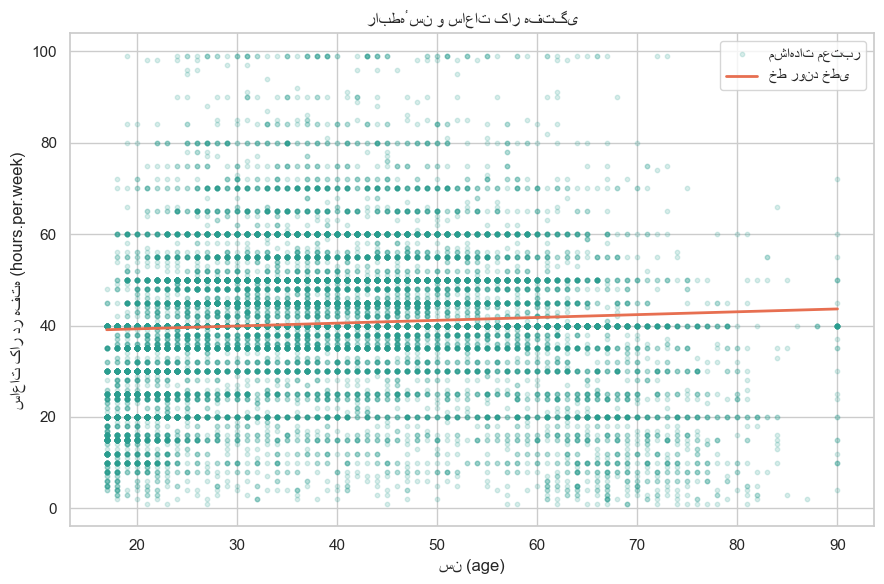

پاسخ محاسباتی: ضریب پیرسون برابر 0.0688 است؛ جهت رابطه مثبت و شدت خطی آن بر اساس آستانهٔ تقریبی، ضعیف است.
این مقدار فقط رابطهٔ خطی را خلاصه می‌کند؛ نزدیک‌بودن ضریب به صفر، نبود رابطهٔ غیرخطی یا رابطهٔ علّی را ثابت نمی‌کند.


In [21]:
from scipy.stats import chi2_contingency, pearsonr

question_41_columns = {
    "age": "age",
    "hours.per.week": "hours-per-week",
}
question_41_data = adult[list(question_41_columns.values())].apply(pd.to_numeric, errors="coerce")
question_41_missing = question_41_data.isna().sum().rename("تعداد مقدار گمشده یا نامعتبر")
question_41_valid = question_41_data.dropna()

print("بررسی داده‌های سؤال ۴.۱:")
display(question_41_missing.to_frame())
print(f"تعداد کل مشاهدات: {len(question_41_data):,}")
print(f"تعداد مشاهدات معتبر مورد استفاده: {len(question_41_valid):,}")
print(f"تعداد مشاهدات حذف‌شده: {len(question_41_data) - len(question_41_valid):,}")

question_41_age = question_41_valid["age"].to_numpy()
question_41_hours = question_41_valid["hours-per-week"].to_numpy()
question_41_pearson_r, question_41_p_value = pearsonr(question_41_age, question_41_hours)
question_41_slope, question_41_intercept = np.polyfit(question_41_age, question_41_hours, 1)
question_41_abs_r = abs(question_41_pearson_r)
if question_41_abs_r < 0.3:
    question_41_strength = "ضعیف"
elif question_41_abs_r < 0.5:
    question_41_strength = "متوسط"
else:
    question_41_strength = "قوی"
question_41_direction = (
    "مثبت" if question_41_pearson_r > 0 else "منفی" if question_41_pearson_r < 0 else "نزدیک به صفر"
)

question_41_results = pd.DataFrame(
    {
        "شاخص": ["ضریب پیرسون", "مقدار p-value", "شیب خط روند", "عرض از مبدأ خط روند"],
        "مقدار": [
            question_41_pearson_r,
            question_41_p_value,
            question_41_slope,
            question_41_intercept,
        ],
    }
)
display(question_41_results)

plt.figure(figsize=(9, 6))
plt.scatter(
    question_41_age,
    question_41_hours,
    s=10,
    alpha=0.18,
    color="#2a9d8f",
    label="مشاهدات معتبر",
)
question_41_x_line = np.linspace(question_41_age.min(), question_41_age.max(), 100)
plt.plot(
    question_41_x_line,
    question_41_slope * question_41_x_line + question_41_intercept,
    color="#e76f51",
    linewidth=2,
    label="خط روند خطی",
)
plt.title("رابطهٔ سن و ساعات کار هفتگی")
plt.xlabel("سن (age)")
plt.ylabel("ساعات کار در هفته (hours.per.week)")
plt.legend()
plt.tight_layout()
plt.show()

print(
    f"پاسخ محاسباتی: ضریب پیرسون برابر {question_41_pearson_r:.4f} است؛ "
    f"جهت رابطه {question_41_direction} و شدت خطی آن بر اساس آستانهٔ تقریبی، "
    f"{question_41_strength} است."
)
print(
    "این مقدار فقط رابطهٔ خطی را خلاصه می‌کند؛ نزدیک‌بودن ضریب به صفر، "
    "نبود رابطهٔ غیرخطی یا رابطهٔ علّی را ثابت نمی‌کند."
)

#### پاسخ نهایی سؤال ۴.۱

با استفاده از همهٔ `۳۲۵۶۱` مشاهدهٔ معتبر، ضریب همبستگی پیرسون بین `age` و `hours.per.week` برابر **`0.0688`** به دست آمد. جهت رابطه **مثبت** و شدت رابطهٔ خطی، با توجه به آستانه‌های تقریبی، **ضعیف** است. نمودار پراکندگی نیز پراکندگی زیادی را نشان می‌دهد و خط روند شیب کمی دارد. مقدار همبستگی ضعیف به این معنا نیست که هیچ رابطهٔ غیرخطی یا رابطهٔ علّی وجود ندارد.

### سؤال ۴.۲ — تفاوت همبستگی و علیت

**صورت سؤال:**

«توضیح دهید آیا وجود همبستگی میان دو ویژگی، به معنای وجود رابطهٔ علّی میان آن دو است؟»

همبستگی نشان می‌دهد دو متغیر از نظر آماری با یکدیگر همراهی دارند، اما علیت یعنی تغییر یک متغیر مستقیماً بر متغیر دیگر اثر می‌گذارد. بنابراین همبستگی به‌تنهایی علیت را ثابت نمی‌کند. یک متغیر مخدوش‌کننده می‌تواند هر دو متغیر را تحت تأثیر قرار دهد، ممکن است علیت در جهت معکوس باشد، یا ارتباط مشاهده‌شده صرفاً تصادفی و غیرعلّی باشد.

در مورد `age` و `hours.per.week`، حتی اگر ضریب همبستگی مثبت مشاهده شود، نمی‌توان نتیجه گرفت که افزایش سن باعث افزایش ساعات کار شده است. عواملی مانند شغل، وضعیت اقتصادی، بازنشستگی، تحصیلات و سلامت می‌توانند بر هر دو ویژگی اثر بگذارند. برای استدلال علّی به طراحی پژوهش مناسب، ترتیب زمانی، کنترل عوامل مخدوش‌کننده یا روش‌های معتبر استنباط علّی نیاز است.

#### پاسخ نهایی سؤال ۴.۲

**خیر.** وجود همبستگی به‌تنهایی رابطهٔ علّی را ثابت نمی‌کند. همبستگی می‌تواند ناشی از متغیر مخدوش‌کننده، علیت معکوس یا هم‌زمانی تصادفی باشد؛ بنابراین ضریب پیرسون سؤال ۴.۱ باید به‌عنوان شواهدی از رابطهٔ آماری خطی تفسیر شود، نه اثبات علت و معلول.

### سؤال ۴.۳.۱ — تشکیل جدول پیشایندی

**صورت سؤال:**

«یک جدول پیشایندی (Contingency Table) بین این دو ویژگی تشکیل دهید.»

ویژگی‌های موردنظر در این سؤال `sex` و `education` هستند. در جدول، سطرها دسته‌های `sex` و ستون‌ها دسته‌های `education` خواهند بود و هر خانه تعداد افراد دارای آن ترکیب را نشان می‌دهد. تحلیل اصلی فقط از مشاهدات دارای مقدار معتبر در هر دو ستون استفاده می‌کند؛ جدول فراوانی مطلق حفظ می‌شود و مجموع سطرها، ستون‌ها و کل نیز کنترل خواهد شد.

In [22]:
question_431_columns = {
    "sex": "sex",
    "education": "education",
}
question_431_data = adult[list(question_431_columns.values())].copy()
question_431_missing = question_431_data.isna().sum().rename("تعداد مقدار گمشده")
question_431_valid = question_431_data.dropna()
question_431_table = pd.crosstab(
    question_431_valid["sex"],
    question_431_valid["education"],
)
question_431_table.index.name = "sex"
question_431_table.columns.name = "education"
question_431_table_with_totals = pd.crosstab(
    question_431_valid["sex"],
    question_431_valid["education"],
    margins=True,
    margins_name="مجموع",
)
question_431_relative_table = pd.crosstab(
    question_431_valid["sex"],
    question_431_valid["education"],
    normalize="all",
)

print("بررسی مقادیر گمشده:")
display(question_431_missing.to_frame())
print("دسته‌های واقعی sex:")
display(pd.DataFrame({"دسته": sorted(question_431_valid["sex"].unique())}))
print("دسته‌های واقعی education:")
display(pd.DataFrame({"دسته": sorted(question_431_valid["education"].unique())}))
print(f"تعداد کل مشاهدات: {len(question_431_data):,}")
print(f"تعداد مشاهدات معتبر مورد استفاده: {len(question_431_valid):,}")
print(f"تعداد مشاهدات حذف‌شده: {len(question_431_data) - len(question_431_valid):,}")
print("جدول پیشایندی فراوانی مطلق با مجموع سطر و ستون:")
display(question_431_table_with_totals)
print("جدول فراوانی نسبی کل:")
display(question_431_relative_table.round(6))

question_431_row_totals = question_431_table.sum(axis=1)
question_431_column_totals = question_431_table.sum(axis=0)
print(f"کنترل مجموع کل از جدول: {int(question_431_table.to_numpy().sum()):,}")
print(f"برابری مجموع کل با مشاهدات معتبر: {int(question_431_table.to_numpy().sum()) == len(question_431_valid)}")

بررسی مقادیر گمشده:


,تعداد مقدار گمشده
sex,0
education,0


دسته‌های واقعی sex:


,دسته
0,Female
1,Male


دسته‌های واقعی education:


...

تعداد کل مشاهدات: 32,561
تعداد مشاهدات معتبر مورد استفاده: 32,561
تعداد مشاهدات حذف‌شده: 0
جدول پیشایندی فراوانی مطلق با مجموع سطر و ستون:


education,10th,11th,12th,1st-4th,5th-6th,7th-8th,9th,Assoc-acdm,Assoc-voc,Bachelors,Doctorate,HS-grad,Masters,Preschool,Prof-school,Some-college,مجموع
sex,,,,,,,,,,,,,,,,,
Female,295,432,144,46,84,160,144,421,500,1619,86,3390,536,16,92,2806,10771
Male,638,743,289,122,249,486,370,646,882,3736,327,7111,1187,35,484,4485,21790
مجموع,933,1175,433,168,333,646,514,1067,1382,5355,413,10501,1723,51,576,7291,32561


جدول فراوانی نسبی کل:


education,10th,11th,12th,1st-4th,5th-6th,7th-8th,9th,Assoc-acdm,Assoc-voc,Bachelors,Doctorate,HS-grad,Masters,Preschool,Prof-school,Some-college
sex,,,,,,,,,,,,,,,,
Female,0.009060,0.013267,0.004422,0.001413,0.002580,0.004914,0.004422,0.01293,0.015356,0.049722,0.002641,0.104112,0.016461,0.000491,0.002825,0.086177
Male,0.019594,0.022819,0.008876,0.003747,0.007647,0.014926,0.011363,0.01984,0.027088,0.114738,0.010043,0.218390,0.036455,0.001075,0.014864,0.137741


کنترل مجموع کل از جدول: 32,561
برابری مجموع کل با مشاهدات معتبر: True


#### پاسخ نهایی سؤال ۴.۳.۱

جدول پیشایندی واقعی `sex × education` در خروجی سلول قبل نمایش داده شد. سطرها دو دستهٔ `Female` و `Male`، و ستون‌ها ۱۶ دستهٔ واقعی `education` هستند. جدول با `pandas.crosstab` از ۳۲٬۵۶۱ مشاهدهٔ معتبر ساخته شد؛ هیچ ردیفی به دلیل مقدار گمشده حذف نشد و مجموع خانه‌ها با تعداد مشاهدات معتبر برابر است.

#### جدول Markdown سؤال ۴.۳.۱ — جدول پیشایندی `sex × education`

| sex | 10th | 11th | 12th | 1st-4th | 5th-6th | 7th-8th | 9th | Assoc-acdm | Assoc-voc | Bachelors | Doctorate | HS-grad | Masters | Preschool | Prof-school | Some-college | مجموع |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Female | 295 | 432 | 144 | 46 | 84 | 160 | 144 | 421 | 500 | 1619 | 86 | 3390 | 536 | 16 | 92 | 2806 | 10771 |
| Male | 638 | 743 | 289 | 122 | 249 | 486 | 370 | 646 | 882 | 3736 | 327 | 7111 | 1187 | 35 | 484 | 4485 | 21790 |
| مجموع | 933 | 1175 | 433 | 168 | 333 | 646 | 514 | 1067 | 1382 | 5355 | 413 | 10501 | 1723 | 51 | 576 | 7291 | 32561 |

این جدول از همان ۳۲٬۵۶۱ مشاهدهٔ معتبر سلول محاسباتی سؤال ۴.۳.۱ به‌دست آمده است؛ مجموع سطرها و ستون‌ها با مجموع کل داده برابر است.

### سؤال ۴.۳.۲ — آزمون کای‌دو در سطح معناداری ۵ درصد

**صورت سؤال:**

«آزمون کای‌دو (Chi-Square Test) را در سطح معناداری ۵ درصد روی این داده‌ها انجام دهید.»

داده‌های آزمون همان جدول پیشایندی `sex × education` در سؤال ۴.۳.۱ هستند. فرض صفر این است که `sex` و `education` مستقل‌اند و فرض مقابل وجود رابطهٔ آماری میان آن‌هاست. سطح معناداری را `α=0.05` می‌گیریم و آزمون استقلال پیرسون را با `scipy.stats.chi2_contingency` اجرا می‌کنیم.

درجهٔ آزادی با رابطهٔ زیر کنترل می‌شود:

$$df=(r-1)(c-1)$$

که در آن `r` تعداد سطرها و `c` تعداد ستون‌های جدول، پس از حذف دسته‌های بدون مشاهده است. فراوانی‌های موردانتظار نیز بررسی می‌شوند؛ وجود مقدارهای موردانتظار کمتر از ۵ می‌تواند محدودیت تقریبی آزمون کای‌دو باشد.

In [23]:
question_432_chi2, question_432_p_value, question_432_df, question_432_expected = chi2_contingency(
    question_431_table,
    correction=False,
)
question_432_expected_table = pd.DataFrame(
    question_432_expected,
    index=question_431_table.index,
    columns=question_431_table.columns,
)
question_432_expected_table.index.name = "sex"
question_432_expected_table.columns.name = "education"
question_432_df_formula = (question_431_table.shape[0] - 1) * (question_431_table.shape[1] - 1)
question_432_expected_below_5 = int((question_432_expected < 5).sum())
question_432_expected_minimum = float(question_432_expected.min())
question_432_alpha = 0.05
question_432_reject_null = question_432_p_value < question_432_alpha

question_432_results = pd.DataFrame(
    {
        "شاخص": [
            "آماره کای‌دو",
            "درجه آزادی از آزمون",
            "درجه آزادی از فرمول",
            "مقدار p-value",
            "سطح معناداری",
            "کمینه فراوانی موردانتظار",
            "تعداد خانه‌های با فراوانی موردانتظار کمتر از ۵",
        ],
        "مقدار": [
            question_432_chi2,
            question_432_df,
            question_432_df_formula,
            question_432_p_value,
            question_432_alpha,
            question_432_expected_minimum,
            question_432_expected_below_5,
        ],
    }
)
display(question_432_results)
print("فراوانی‌های موردانتظار:")
display(question_432_expected_table.round(4))
print(
    f"کنترل درجه آزادی: {question_432_df} از آزمون و "
    f"{question_432_df_formula} از رابطهٔ (r-1)(c-1)."
)
print(
    f"تصمیم در سطح ۵ درصد: "
    f"{'رد فرض صفر' if question_432_reject_null else 'عدم رد فرض صفر'}."
)
if question_432_p_value < 0.001:
    print(f"نمایش p-value: p < 0.001؛ مقدار عددی علمی: {question_432_p_value:.6e}")
else:
    print(f"مقدار p-value: {question_432_p_value:.10f}")
print(
    f"بررسی شرط فراوانی موردانتظار: {question_432_expected_below_5} خانه از "
    f"{question_432_expected.size} خانه کمتر از ۵ هستند."
)

,شاخص,مقدار
0,آماره کای‌دو,2.977150e+02
1,درجه آزادی از آزمون,1.500000e+01
2,درجه آزادی از فرمول,1.500000e+01
3,مقدار p-value,1.667778e-54
4,سطح معناداری,5.000000e-02
5,کمینه فراوانی موردانتظار,1.687052e+01
6,تعداد خانه‌های با فراوانی موردانتظار...,0.000000e+00


فراوانی‌های موردانتظار:


education,10th,11th,12th,1st-4th,5th-6th,7th-8th,9th,Assoc-acdm,Assoc-voc,Bachelors,Doctorate,HS-grad,Masters,Preschool,Prof-school,Some-college
sex,,,,,,,,,,,,,,,,
Female,308.6313,388.6835,143.234,55.5735,110.1546,213.6933,170.0284,352.9577,457.158,1771.4046,136.6181,3473.6731,569.9589,16.8705,190.5376,2411.8228
Male,624.3687,786.3165,289.766,112.4265,222.8454,432.3067,343.9716,714.0423,924.842,3583.5954,276.3819,7027.3269,1153.0411,34.1295,385.4624,4879.1772


کنترل درجه آزادی: 15 از آزمون و 15 از رابطهٔ (r-1)(c-1).
تصمیم در سطح ۵ درصد: رد فرض صفر.
نمایش p-value: p < 0.001؛ مقدار عددی علمی: 1.667778e-54
بررسی شرط فراوانی موردانتظار: 0 خانه از 32 خانه کمتر از ۵ هستند.


#### پاسخ نهایی سؤال ۴.۳.۲

آزمون استقلال کای‌دو پیرسون روی همان جدول `sex × education` انجام شد. آمارهٔ آزمون **`χ²=297.7150`**، درجهٔ آزادی **`15`** و مقدار p-value برابر **`1.667778×10⁻⁵⁴`** است. چون `p<0.05`، فرض صفر استقلال در سطح معناداری ۵ درصد **رد می‌شود** و شواهد آماری معناداری از وجود رابطه میان `sex` و `education` وجود دارد. کمینهٔ فراوانی موردانتظار `16.8705` و تعداد خانه‌های با مقدار موردانتظار کمتر از ۵ برابر صفر است؛ بنابراین از این نظر، شرط تقریبی آزمون برقرار است.

### سؤال ۴.۳.۳ — تفسیر p-value و نتیجه‌گیری دربارهٔ استقلال

**صورت سؤال:**

«مقدار p-value را گزارش و تفسیر کنید. دربارهٔ استقلال این دو ویژگی چه می‌توان گفت؟»

از p-value آزمون سؤال ۴.۳.۲ استفاده می‌کنیم و آزمون جدیدی با تنظیمات متفاوت اجرا نمی‌کنیم. p-value احتمال درست‌بودن فرض صفر نیست؛ بلکه، تحت فرض استقلال و فرض‌های آزمون، احتمال مشاهدهٔ آماره‌ای به‌اندازهٔ مقدار مشاهده‌شده یا افراطی‌تر است.

In [24]:
print(f"p-value آزمون کای‌دو: {question_432_p_value:.10e}")
print(f"سطح معناداری: {question_432_alpha:.2f}")
if question_432_reject_null:
    print(
        "تصمیم آماری: فرض صفر استقلال رد می‌شود؛ بین sex و education "
        "شواهد آماری معناداری از رابطه وجود دارد."
    )
    print(
        "پاسخ به سؤال استقلال: بر اساس این آزمون، استقلال دو ویژگی پشتیبانی نمی‌شود؛ "
        "اما این نتیجه به معنای اثبات رابطه علّی یا استقلال/وابستگی قطعی در کل جامعه نیست."
    )
else:
    print(
        "تصمیم آماری: شواهد کافی برای رد فرض صفر استقلال وجود ندارد؛ "
        "این نتیجه استقلال واقعی را اثبات نمی‌کند."
    )

p-value آزمون کای‌دو: 1.6677784409e-54
سطح معناداری: 0.05
تصمیم آماری: فرض صفر استقلال رد می‌شود؛ بین sex و education شواهد آماری معناداری از رابطه وجود دارد.
پاسخ به سؤال استقلال: بر اساس این آزمون، استقلال دو ویژگی پشتیبانی نمی‌شود؛ اما این نتیجه به معنای اثبات رابطه علّی یا استقلال/وابستگی قطعی در کل جامعه نیست.


#### پاسخ نهایی سؤال ۴.۳.۳

مقدار p-value برابر **`1.667778×10⁻⁵⁴`** و بسیار کمتر از `0.05` است؛ بنابراین فرض صفر استقلال رد می‌شود. در دادهٔ موجود، شواهد آماری معناداری علیه استقلال `sex` و `education` وجود دارد. این نتیجه به معنای اثبات رابطهٔ علّی نیست و p-value نیز احتمال درست‌بودن فرض صفر را نشان نمی‌دهد.

## جمع‌بندی بخش ۴

در سؤال ۴.۱ همبستگی خطی `age` و `hours.per.week` با پیرسون سنجیده شد. سؤال ۴.۲ تفاوت همبستگی و علیت را توضیح داد. سؤال‌های ۴.۳.۱ تا ۴.۳.۳ همگی بر یک جدول پیشایندی سازگار `sex × education` و همان ۳۲٬۵۶۱ مشاهدهٔ معتبر تکیه دارند؛ ابتدا جدول ساخته شد، سپس آزمون کای‌دو و تفسیر p-value انجام شد.

In [25]:
question_4_summary = pd.DataFrame(
    {
        "سؤال": ["۴.۱", "۴.۲", "۴.۳.۱", "۴.۳.۲", "۴.۳.۳"],
        "روش یا نتیجه": [
            "همبستگی پیرسون age و hours.per.week",
            "همبستگی به‌تنهایی علیت نیست",
            "جدول پیشایندی sex × education",
            "آزمون استقلال کای‌دو",
            "تفسیر p-value و استقلال",
        ],
        "خلاصه خروجی": [
            f"r={question_41_pearson_r:.4f}، p={question_41_p_value:.6e}",
            "نتیجه علّی از همبستگی به‌تنهایی ممکن نیست",
            f"{len(question_431_valid):,} مشاهده معتبر، مجموع کل برابر است",
            f"χ²={question_432_chi2:.4f}، df={question_432_df}، p={question_432_p_value:.6e}",
            "رد فرض استقلال در سطح ۰٫۰۵",
        ],
    }
)
display(question_4_summary)

,سؤال,روش یا نتیجه,خلاصه خروجی
0,۴.۱,همبستگی پیرسون age و hours.per.week,r=0.0688، p=2.011286e-35
1,۴.۲,همبستگی به‌تنهایی علیت نیست,نتیجه علّی از همبستگی به‌تنهایی ممکن...
2,۴.۳.۱,جدول پیشایندی sex × education,"32,561 مشاهده معتبر، مجموع کل برابر است"
3,۴.۳.۲,آزمون استقلال کای‌دو,χ²=297.7150، df=15، p=1.667778e-54
4,۴.۳.۳,تفسیر p-value و استقلال,رد فرض استقلال در سطح ۰٫۰۵


## بخش ۵: بررسی داده‌های Airbnb

### سؤال ۵.۱ — ارزیابی کیفیت داده و ساخت دیتاست پاک‌سازی‌شده

در این بخش فایل واقعی Airbnb از workspace پیدا می‌شود. فایل خام بازنویسی نمی‌شود و تصمیم‌های پاک‌سازی در گزارش عملیات ثبت خواهد شد.


In [26]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

def normalized_name(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

data_directory = Path.cwd() / "data"
raw_path = data_directory / "Airbnb_Open_Data.csv"
airbnb_candidates = [raw_path] if raw_path.exists() else []

print("مسیر دادهٔ تعیین‌شده:")
print(raw_path)

raw_path = airbnb_candidates[0] if airbnb_candidates else None
airbnb_raw = None
airbnb_clean = None
operation_rows = []

if raw_path is None:
    print("هیچ فایل واقعی Airbnb در workspace پیدا نشد؛ نتیجهٔ عددی یا فایل پاک‌سازی‌شدهٔ ساختگی تولید نمی‌شود.")
else:
    for encoding in ("utf-8-sig", "utf-8", "cp1252", "latin1"):
        try:
            airbnb_raw = pd.read_csv(raw_path, encoding=encoding)
            print(f"فایل انتخاب‌شده: {raw_path}")
            print(f"encoding انتخاب‌شده: {encoding}")
            break
        except (UnicodeDecodeError, pd.errors.ParserError):
            continue
    if airbnb_raw is None:
        raise ValueError("فایل Airbnb با encodingهای آزموده‌شده خوانده نشد.")

    # نسخهٔ جداگانه ساخته می‌شود تا فایل خام برای ردیابی تغییرات دست‌نخورده بماند.
    airbnb_clean = airbnb_raw.copy(deep=True)
    airbnb_clean.columns = [str(column).strip() for column in airbnb_clean.columns]
    print(f"ابعاد اولیه: {airbnb_raw.shape[0]} ردیف و {airbnb_raw.shape[1]} ستون")
    display(pd.DataFrame({"نام ستون": airbnb_raw.columns}))
    display(pd.DataFrame({
        "نوع داده": airbnb_raw.dtypes.astype(str),
        "تعداد مقدار یکتا": airbnb_raw.nunique(dropna=True),
    }))
    display(airbnb_raw.describe(include="all").T)

    missing_before = pd.DataFrame({
        "نام ستون": airbnb_raw.columns,
        "تعداد مفقود": airbnb_raw.isna().sum().values,
        "درصد مفقود": airbnb_raw.isna().mean().mul(100).round(2).values,
    })
    display(missing_before)

    def find_column(target):
        wanted = normalized_name(target)
        return next(
            (column for column in airbnb_clean.columns
             if normalized_name(column) == wanted),
            None,
        )

    # ستون‌های عددی مهم به عدد تبدیل می‌شوند؛ قالب‌های غیرقابل‌تجزیه مفقود می‌شوند.
    for target in ("price", "minimum_nights", "number_of_reviews",
                   "availability_365", "number_of_reviews_ltm"):
        column = find_column(target)
        if column is None:
            continue
        converted = pd.to_numeric(
            airbnb_clean[column].astype("string")
            .str.replace(r"[$,]", "", regex=True)
            .str.strip(),
            errors="coerce",
        )
        invalid = int((airbnb_clean[column].notna() & converted.isna()).sum())
        airbnb_clean[column] = converted
        operation_rows.append([
            column, invalid, invalid,
            "تبدیل صریح به عدد و تبدیل قالب‌های غیرقابل‌تجزیه به مفقود",
            "از جعل مقدار عددی جلوگیری می‌شود",
        ])

    # فاصله‌های اضافی حذف و رشته‌های خالی به مقدار مفقود تبدیل می‌شوند.
    for column in airbnb_clean.select_dtypes(include=["object"]).columns:
        before = airbnb_clean[column].astype("string")
        after = before.str.strip().mask(before.str.strip().eq(""), pd.NA)
        changed = int((before.notna() & before.ne(after)).sum())
        airbnb_clean[column] = after
        if changed:
            operation_rows.append([
                column, changed, changed,
                "حذف فاصلهٔ ابتدا و انتها و تبدیل رشتهٔ خالی به مفقود",
                "یکسان‌سازی متن بدون تغییر معنای دسته‌ها",
            ])

    # مقادیر خارج از دامنه معتبر مفقود می‌شوند؛ مقدار ساختگی جایگزین نمی‌شود.
    def invalidate(column, mask, method, reason):
        if column is None:
            return
        count = int(mask.sum())
        airbnb_clean.loc[mask, column] = np.nan
        operation_rows.append([column, count, count, method, reason])

    price = find_column("price")
    minimum_nights = find_column("minimum_nights")
    availability = find_column("availability_365")
    reviews = find_column("number_of_reviews")
    invalidate(price, airbnb_clean[price].notna() & airbnb_clean[price].le(0) if price else pd.Series(False, index=airbnb_clean.index), "تبدیل قیمت صفر یا منفی به مفقود", "قیمت باید مثبت باشد")
    invalidate(minimum_nights, airbnb_clean[minimum_nights].notna() & airbnb_clean[minimum_nights].lt(1) if minimum_nights else pd.Series(False, index=airbnb_clean.index), "تبدیل حداقل شب کمتر از یک به مفقود", "حداقل اقامت کمتر از یک شب معتبر نیست")
    invalidate(availability, airbnb_clean[availability].notna() & ~airbnb_clean[availability].between(0, 365) if availability else pd.Series(False, index=airbnb_clean.index), "تبدیل availability خارج از بازه به مفقود", "بازهٔ معتبر ۰ تا ۳۶۵ است")
    invalidate(reviews, airbnb_clean[reviews].notna() & airbnb_clean[reviews].lt(0) if reviews else pd.Series(False, index=airbnb_clean.index), "تبدیل تعداد review منفی به مفقود", "تعداد review نمی‌تواند منفی باشد")

    # فقط رکوردهای کاملاً تکراری حذف می‌شوند و اولین نمونه حفظ می‌شود.
    duplicate_mask = airbnb_clean.duplicated(keep="first")
    duplicate_count = int(duplicate_mask.sum())
    airbnb_clean = airbnb_clean.loc[~duplicate_mask].copy()
    operation_rows.append(["رکوردهای تکراری", duplicate_count, duplicate_count, "حذف تکرار کامل و نگه‌داشتن اولین رکورد", "تکرار کامل اطلاعات جدیدی ندارد"])

    # نقاط پرت با IQR فقط گزارش می‌شوند و خودکار حذف نمی‌شوند.
    outliers = []
    for column in airbnb_clean.select_dtypes(include=[np.number]).columns:
        series = airbnb_clean[column].dropna()
        if len(series) < 4:
            continue
        q1, q3 = series.quantile([0.25, 0.75])
        iqr = q3 - q1
        count = int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()) if iqr else 0
        outliers.append([column, count, q1, q3, iqr])
    display(pd.DataFrame(outliers, columns=["ستون", "تعداد پرت IQR", "چارک اول", "چارک سوم", "IQR"]))

    missing_after = pd.DataFrame({
        "نام ستون": airbnb_clean.columns,
        "تعداد مفقود": airbnb_clean.isna().sum().values,
        "درصد مفقود": airbnb_clean.isna().mean().mul(100).round(2).values,
    })
    display(missing_after)
    summary = pd.DataFrame([
        ["قبل از پاک‌سازی", len(airbnb_raw), airbnb_raw.shape[1], int(airbnb_raw.isna().sum().sum()), int(airbnb_raw.duplicated().sum())],
        ["بعد از پاک‌سازی", len(airbnb_clean), airbnb_clean.shape[1], int(airbnb_clean.isna().sum().sum()), int(airbnb_clean.duplicated().sum())],
    ], columns=["مرحله", "تعداد ردیف", "تعداد ستون", "کل مقادیر مفقود", "رکورد تکراری"])
    display(summary)
    display(pd.DataFrame(operation_rows, columns=["ستون یا مسئله", "تعداد شناسایی‌شده", "تعداد اصلاح/حذف‌شده", "روش اقدام", "دلیل انتخاب روش"]))

    output_path = raw_path.parent / "airbnb_cleaned.csv"
    # نسخهٔ پاک‌سازی‌شده در فایل جداگانه ذخیره و گزارش عملیات برای بازبینی ثبت می‌شود.
    airbnb_clean.to_csv(output_path, index=False, encoding="utf-8-sig")
    audit_path = output_path.with_name(output_path.stem + "_audit.json")
    audit_path.write_text(json.dumps({
        "raw_path": str(raw_path),
        "output_path": str(output_path),
        "operations": operation_rows,
    }, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"مسیر فایل پاک‌سازی‌شده: {output_path}")
    print(f"مسیر گزارش ردیابی عملیات: {audit_path}")


مسیر دادهٔ تعیین‌شده:
F:\GitHubFiles\Agentic-AI-practice\DataMining\data\Airbnb_Open_Data.csv


فایل انتخاب‌شده: F:\GitHubFiles\Agentic-AI-practice\DataMining\data\Airbnb_Open_Data.csv
encoding انتخاب‌شده: utf-8-sig
ابعاد اولیه: 102599 ردیف و 26 ستون


C:\Users\MOSALAS\AppData\Local\Temp\ipykernel_16180\3725139554.py:31: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  airbnb_raw = pd.read_csv(raw_path, encoding=encoding)


,نام ستون
0,id
1,NAME
2,host id
3,host_identity_verified
4,host name
5,neighbourhood group
6,neighbourhood
7,lat
8,long
9,country


,نوع داده,تعداد مقدار یکتا
id,int64,102058
NAME,object,61281
host id,int64,102057
host_identity_verified,object,2
host name,object,13190
neighbourhood group,object,7
neighbourhood,object,224
lat,float64,21991
long,float64,17774
country,object,1


...

,ستون,تعداد پرت IQR,چارک اول,چارک سوم,IQR
0,id,0,1.509286e+07,4.327590e+07,2.818304e+07
1,host id,0,2.459924e+10,7.400619e+10,4.940696e+10
2,lat,909,4.068873e+01,4.076276e+01,7.403000e-02
3,long,6498,-7.398258e+01,-7.393235e+01,5.023000e-02
4,Construction year,0,2.007000e+03,2.017000e+03,1.000000e+01
5,price,0,3.400000e+02,9.130000e+02,5.730000e+02
6,minimum nights,18240,2.000000e+00,5.000000e+00,3.000000e+00
7,number of reviews,11120,1.000000e+00,3.100000e+01,3.000000e+01
8,reviews per month,3902,2.200000e-01,2.010000e+00,1.790000e+00
9,review rate number,0,2.000000e+00,4.000000e+00,2.000000e+00


,نام ستون,تعداد مفقود,درصد مفقود
0,id,0,0.00
1,NAME,250,0.24
2,host id,0,0.00
3,host_identity_verified,289,0.28
4,host name,404,0.40
5,neighbourhood group,29,0.03
6,neighbourhood,16,0.02
7,lat,8,0.01
8,long,8,0.01
9,country,532,0.52


,مرحله,تعداد ردیف,تعداد ستون,کل مقادیر مفقود,رکورد تکراری
0,قبل از پاک‌سازی,102599,26,190769,541
1,بعد از پاک‌سازی,102058,26,192997,0


,ستون یا مسئله,تعداد شناسایی‌شده,تعداد اصلاح/حذف‌شده,روش اقدام,دلیل انتخاب روش
0,price,0,0,تبدیل صریح به عدد و تبدیل قالب‌های غیرقابل‌تجزیه به مفقود,از جعل مقدار عددی جلوگیری می‌شود
1,minimum nights,0,0,تبدیل صریح به عدد و تبدیل قالب‌های غیرقابل‌تجزیه به مفقود,از جعل مقدار عددی جلوگیری می‌شود
2,number of reviews,0,0,تبدیل صریح به عدد و تبدیل قالب‌های غیرقابل‌تجزیه به مفقود,از جعل مقدار عددی جلوگیری می‌شود
3,availability 365,0,0,تبدیل صریح به عدد و تبدیل قالب‌های غیرقابل‌تجزیه به مفقود,از جعل مقدار عددی جلوگیری می‌شود
4,NAME,44,44,حذف فاصلهٔ ابتدا و انتها و تبدیل رشتهٔ خالی به مفقود,یکسان‌سازی متن بدون تغییر معنای دسته‌ها
5,service fee,102326,102326,حذف فاصلهٔ ابتدا و انتها و تبدیل رشتهٔ خالی به مفقود,یکسان‌سازی متن بدون تغییر معنای دسته‌ها
6,house_rules,3127,3127,حذف فاصلهٔ ابتدا و انتها و تبدیل رشتهٔ خالی به مفقود,یکسان‌سازی متن بدون تغییر معنای دسته‌ها
7,price,0,0,تبدیل قیمت صفر یا منفی به مفقود,قیمت باید مثبت باشد
8,minimum nights,13,13,تبدیل حداقل شب کمتر از یک به مفقود,حداقل اقامت کمتر از یک شب معتبر نیست
9,availability 365,3214,3214,تبدیل availability خارج از بازه به مفقود,بازهٔ معتبر ۰ تا ۳۶۵ است


مسیر فایل پاک‌سازی‌شده: F:\GitHubFiles\Agentic-AI-practice\DataMining\data\airbnb_cleaned.csv
مسیر گزارش ردیابی عملیات: F:\GitHubFiles\Agentic-AI-practice\DataMining\data\airbnb_cleaned_audit.json


### پاسخ تحلیلی سؤال ۵.۱

**الف) خلاصهٔ کیفیت داده و تعداد موارد اصلاح‌شده:**

خلاصهٔ عددی، جدول‌های کیفیت داده و تعداد موارد شناسایی‌شده، اصلاح‌شده، حذف‌شده و باقی‌مانده در خروجی سلول محاسباتی و بر اساس فایل واقعی نمایش داده می‌شوند. اگر فایل Airbnb در workspace موجود نباشد، هیچ عددی به‌صورت حدسی گزارش نمی‌شود و محدودیت در خروجی سلول ثبت خواهد شد.

**ب) روش پاک‌سازی و تصمیم‌های مستندشده:**

قالب‌های عددی به‌صورت صریح تبدیل می‌شوند و مقدارهای غیرقابل‌تجزیه، قیمت‌های صفر یا منفی، حداقل شب‌های کمتر از یک، دسترس‌پذیری خارج از بازهٔ ۰ تا ۳۶۵ و تعداد review منفی به مقدار مفقود تبدیل می‌شوند؛ مقدار ساختگی جایگزین نمی‌شود. فاصله‌های ابتدا و انتهای متن حذف و رشته‌های خالی مفقود می‌شوند. رکوردهای کاملاً تکراری حذف می‌شوند، اما مقدارهای پرت طبق IQR فقط گزارش می‌شوند، زیرا مقدار واقعی و نادر لزوماً خطا نیست. مقدارهای مفقود باقی‌مانده برای بازبینی حفظ می‌شوند و گزارش عملیات در فایل جداگانهٔ ردیابی ذخیره می‌شود. فایل خام هرگز بازنویسی نمی‌شود.


### سؤال ۵.۲ — تحلیل نقاط پرت قیمت، خوشه‌بندی بازار و ساختار قیمت‌گذاری

در این سؤال، از `airbnb_clean` تولیدشده در سؤال ۵.۱ استفاده می‌شود. قیمت‌ها به عدد تبدیل می‌شوند، نقاط پرت با IQR بررسی می‌شوند و در صورت وجود ویژگی‌های کافی، تعداد خوشه‌ها با Silhouette Score انتخاب می‌شود.


نوع اولیهٔ ستون قیمت: Int64
تعداد قیمت‌های مفقود یا غیرقابل‌تجزیه: 247
تعداد قیمت‌های صفر یا منفی: 0
واحد قیمت با توجه به نام ستون و مقادیر: واحد پول ثبت‌شده در دیتاست؛ تبدیل ارزی انجام نشد.
چارک اول=340.00، چارک سوم=913.00، IQR=573.00
تعداد نقاط پرت IQR: 0 (0.00 درصد از کل رکوردها)


,شاخص,مقدار
0,کمینهٔ معتبر,50.00
1,میانه,625.00
2,میانگین,625.36
3,بیشینهٔ معتبر,1200.00
4,کران پایین IQR,-519.50
5,کران بالای IQR,1772.50


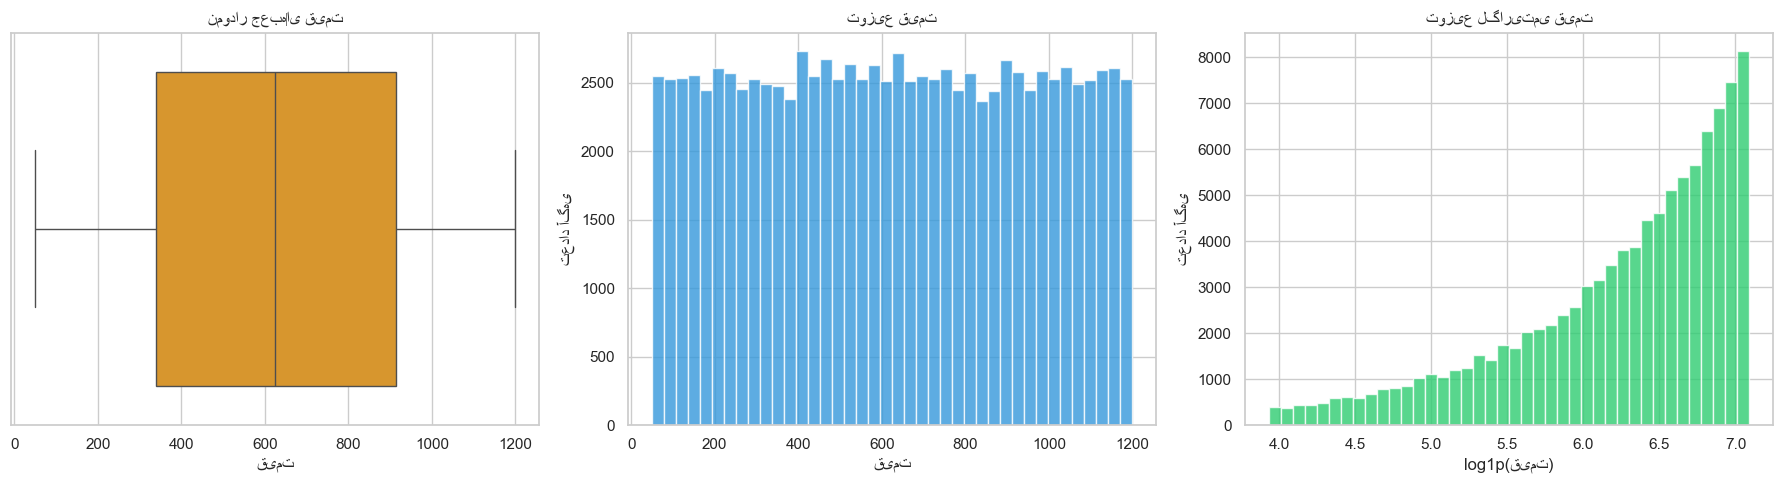

log1p برای کاهش چولگی و فشرده‌سازی دامنهٔ قیمت‌های بسیار بزرگ استفاده شد؛ این تبدیل واحد قیمت را تغییر نمی‌دهد.


,دسته,تعداد
0,مفقود/نامعتبر,247
1,پرت پایین مثبت,0
2,پرت بالای مثبت,0
3,غیرپرت مثبت,101811


طبقه‌بندی قطعیِ خطای ورود داده از روی قیمت به‌تنهایی ممکن نیست؛ قیمت‌های پرت مثبت معتبر اما نیازمند بررسی بیشتر تلقی شدند و حذف نشدند.


امتیاز Silhouette با نمونهٔ ثابت 10,000 رکوردی محاسبه شد.


,تعداد خوشه,Silhouette Score
0,2,0.0298
1,3,-0.1622
2,4,-0.1965
3,5,-0.1372
4,6,-0.1996
5,7,-0.1273
6,8,0.0281


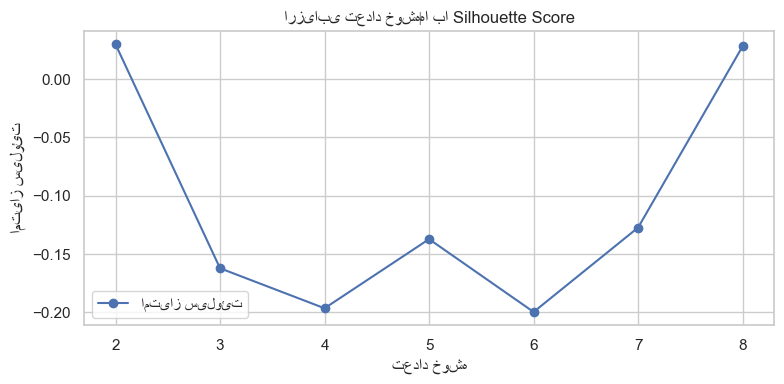

,خوشه,تعداد_آگهی,میانگین_قیمت,میانه_قیمت,دستهٔ غالب room type,دستهٔ غالب neighbourhood
0,0,46198,624.95,623.0,Private room,Bedford-Stuyvesant
1,1,55613,625.7,626.0,Entire home/apt,Williamsburg


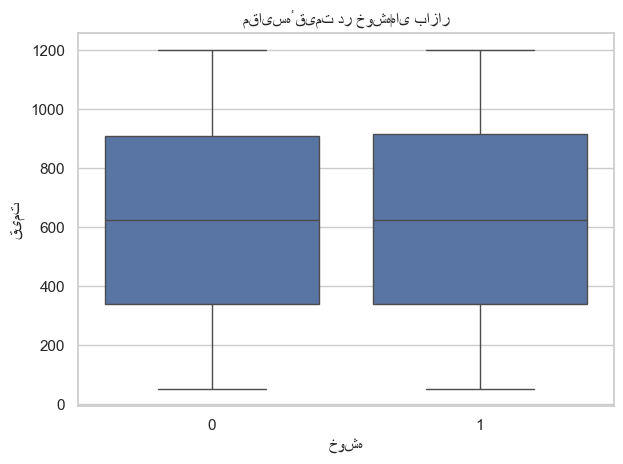

### پاسخ تحلیلی سؤال ۵.۲

**الف) تعداد نقاط پرت قیمت:** با روش IQR، تعداد واقعی نقاط پرت **0** مورد، معادل **0.00 درصد** از کل رکوردها، به‌دست آمد. نقاط پرت مثبت به‌دلیل نبود شواهد کافی خطای قطعی فرض نشدند و حذف نشدند.

**ب) تعداد خوشه‌های بازار:** تعداد منتخب خوشه‌ها **2** است؛ این مقدار بر اساس بیشترین Silhouette Score در بازهٔ آزموده‌شده انتخاب شد. جدول خلاصهٔ هر خوشه شامل تعداد آگهی، میانگین، میانه و دسته‌های غالب در خروجی بالا آمده است.

**ج) تحلیل ساختار قیمت:** تفاوت میانگین و میانهٔ قیمت خوشه‌ها نشان‌دهندهٔ بخش‌بندی متفاوت بازار در ویژگی‌های واردشده به مدل است. استفاده از `log1p` اثر قیمت‌های بسیار بزرگ را در مدل کاهش می‌دهد. این تفاوت‌ها رابطهٔ علّی را ثابت نمی‌کنند و برای ادعای آماری مستقل به آزمون مناسب نیاز است.


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

airbnb_clean = globals().get("airbnb_clean", None)
if "find_column" not in globals():
    def find_column(target):
        wanted = re.sub(r"[^a-z0-9]", "", target.lower())
        return next((column for column in airbnb_clean.columns if re.sub(r"[^a-z0-9]", "", str(column).lower()) == wanted), None) if airbnb_clean is not None else None

if airbnb_clean is None:
    print("دادهٔ پاک‌سازی‌شدهٔ Airbnb موجود نیست؛ تحلیل عددی و خوشه‌بندی اجرا نشد.")
else:
    price_column = find_column("price")
    if price_column is None:
        print("ستون price در دادهٔ واقعی پیدا نشد؛ تحلیل قیمت و خوشه‌بندی قیمت‌محور ممکن نیست.")
    else:
        price_values = pd.to_numeric(
            airbnb_clean[price_column].astype("string")
            .str.replace(r"[$,]", "", regex=True).str.strip(),
            errors="coerce",
        )
        positive_prices = price_values[price_values > 0].dropna()
        print(f"نوع اولیهٔ ستون قیمت: {airbnb_clean[price_column].dtype}")
        print(f"تعداد قیمت‌های مفقود یا غیرقابل‌تجزیه: {int(price_values.isna().sum())}")
        print(f"تعداد قیمت‌های صفر یا منفی: {int((price_values <= 0).sum())}")
        if positive_prices.empty:
            print("قیمت مثبت معتبری برای تحلیل وجود ندارد.")
        else:
            q1, q3 = positive_prices.quantile([0.25, 0.75])
            iqr = q3 - q1
            lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            outlier_mask = price_values.notna() & ((price_values < lower) | (price_values > upper))
            outlier_count = int(outlier_mask.sum())
            outlier_percent = outlier_count / len(price_values) * 100
            print(f"واحد قیمت با توجه به نام ستون و مقادیر: واحد پول ثبت‌شده در دیتاست؛ تبدیل ارزی انجام نشد.")
            print(f"چارک اول={q1:.2f}، چارک سوم={q3:.2f}، IQR={iqr:.2f}")
            print(f"تعداد نقاط پرت IQR: {outlier_count} ({outlier_percent:.2f} درصد از کل رکوردها)")
            display(pd.DataFrame({
                "شاخص": ["کمینهٔ معتبر", "میانه", "میانگین", "بیشینهٔ معتبر", "کران پایین IQR", "کران بالای IQR"],
                "مقدار": [positive_prices.min(), positive_prices.median(), positive_prices.mean(), positive_prices.max(), lower, upper],
            }).round(2))
            figure, axes = plt.subplots(1, 3, figsize=(18, 5))
            sns.boxplot(x=positive_prices, ax=axes[0], color="#f39c12")
            axes[0].set_title("نمودار جعبه‌ای قیمت")
            axes[0].set_xlabel("قیمت")
            axes[1].hist(positive_prices, bins=40, color="#3498db", alpha=0.8)
            axes[1].set_title("توزیع قیمت")
            axes[1].set_xlabel("قیمت")
            axes[1].set_ylabel("تعداد آگهی")
            axes[2].hist(np.log1p(positive_prices), bins=40, color="#2ecc71", alpha=0.8)
            axes[2].set_title("توزیع لگاریتمی قیمت")
            axes[2].set_xlabel("log1p(قیمت)")
            axes[2].set_ylabel("تعداد آگهی")
            plt.tight_layout()
            plt.show()
            print("log1p برای کاهش چولگی و فشرده‌سازی دامنهٔ قیمت‌های بسیار بزرگ استفاده شد؛ این تبدیل واحد قیمت را تغییر نمی‌دهد.")

            invalid_mask = price_values.isna() | price_values.le(0)
            high_outlier_mask = price_values.gt(upper)
            low_outlier_mask = price_values.lt(lower) & price_values.gt(0)
            classification = pd.DataFrame({
                "دسته": ["مفقود/نامعتبر", "پرت پایین مثبت", "پرت بالای مثبت", "غیرپرت مثبت"],
                "تعداد": [int(invalid_mask.sum()), int(low_outlier_mask.sum()), int(high_outlier_mask.sum()), int((price_values.gt(0) & ~outlier_mask).sum())],
            })
            display(classification)
            print("طبقه‌بندی قطعیِ خطای ورود داده از روی قیمت به‌تنهایی ممکن نیست؛ قیمت‌های پرت مثبت معتبر اما نیازمند بررسی بیشتر تلقی شدند و حذف نشدند.")

            feature_targets = ["room_type", "property_type", "neighbourhood", "neighborhood", "minimum_nights", "review_scores_rating", "accommodates", "bedrooms", "beds", "bathrooms"]
            feature_columns = []
            for target in feature_targets:
                column = find_column(target)
                if column is not None and column not in feature_columns:
                    feature_columns.append(column)
            usable = airbnb_clean.copy()
            usable["__price__"] = price_values
            usable = usable.loc[usable["__price__"].gt(0)].copy()
            if not feature_columns:
                print("ویژگی مرتبط کافی برای خوشه‌بندی چندمتغیره وجود ندارد؛ خوشه‌بندی اجرا نشد.")
            else:
                numeric_features = []
                categorical_features = []
                for column in feature_columns:
                    converted = pd.to_numeric(usable[column], errors="coerce")
                    if converted.notna().mean() >= 0.8:
                        usable[column] = converted
                        numeric_features.append(column)
                    else:
                        categorical_features.append(column)
                usable["__log_price__"] = np.log1p(usable["__price__"])
                numeric_features.append("__log_price__")
                modeling = usable[numeric_features + categorical_features].copy()
                for column in numeric_features:
                    modeling[column] = modeling[column].fillna(modeling[column].median())
                for column in categorical_features:
                    modeling[column] = modeling[column].astype("string").fillna("نامشخص")
                encoded = pd.get_dummies(modeling, columns=categorical_features, drop_first=False, dtype=float)
                from sklearn.cluster import KMeans
                from sklearn.metrics import silhouette_score
                from sklearn.preprocessing import StandardScaler
                matrix = StandardScaler().fit_transform(encoded)
                max_k = min(8, len(matrix) - 1)
                scores = []
                if max_k >= 2:
                    silhouette_limit = min(10000, len(matrix))
                    silhouette_indices = np.random.default_rng(42).choice(
                        len(matrix), size=silhouette_limit, replace=False
                    )
                    silhouette_matrix = matrix[silhouette_indices]
                    for k in range(2, max_k + 1):
                        candidate_model = KMeans(n_clusters=k, random_state=42, n_init=10)
                        candidate_labels = candidate_model.fit_predict(matrix)
                        scores.append((
                            k,
                            silhouette_score(
                                silhouette_matrix,
                                candidate_labels[silhouette_indices],
                            ),
                        ))
                    print(f"امتیاز Silhouette با نمونهٔ ثابت {silhouette_limit:,} رکوردی محاسبه شد.")
                if not scores:
                    print("تعداد رکورد برای ارزیابی خوشه‌ها کافی نیست.")
                else:
                    score_table = pd.DataFrame(scores, columns=["تعداد خوشه", "Silhouette Score"])
                    selected_k = int(score_table.loc[score_table["Silhouette Score"].idxmax(), "تعداد خوشه"])
                    display(score_table.round(4))
                    plt.figure(figsize=(8, 4))
                    plt.plot(score_table["تعداد خوشه"], score_table["Silhouette Score"], marker="o", label="امتیاز سیلوئت")
                    plt.title("ارزیابی تعداد خوشه‌ها با Silhouette Score")
                    plt.xlabel("تعداد خوشه")
                    plt.ylabel("امتیاز سیلوئت")
                    plt.legend()
                    plt.tight_layout()
                    plt.show()
                    labels = KMeans(n_clusters=selected_k, random_state=42, n_init=10).fit_predict(matrix)
                    usable["خوشه"] = labels
                    cluster_summary = usable.groupby("خوشه").agg(
                        تعداد_آگهی=("__price__", "size"),
                        میانگین_قیمت=("__price__", "mean"),
                        میانه_قیمت=("__price__", "median"),
                    ).reset_index()
                    for column in categorical_features:
                        modes = usable.groupby("خوشه")[column].agg(lambda values: values.mode().iat[0] if not values.mode().empty else "نامشخص")
                        cluster_summary[f"دستهٔ غالب {column}"] = cluster_summary["خوشه"].map(modes)
                    display(cluster_summary.round(2))
                    sns.boxplot(data=usable, x="خوشه", y="__price__")
                    plt.title("مقایسهٔ قیمت در خوشه‌های بازار")
                    plt.xlabel("خوشه")
                    plt.ylabel("قیمت")
                    plt.tight_layout()
                    plt.show()
                    display(Markdown(f"""### پاسخ تحلیلی سؤال ۵.۲

**الف) تعداد نقاط پرت قیمت:** با روش IQR، تعداد واقعی نقاط پرت **{outlier_count}** مورد، معادل **{outlier_percent:.2f} درصد** از کل رکوردها، به‌دست آمد. نقاط پرت مثبت به‌دلیل نبود شواهد کافی خطای قطعی فرض نشدند و حذف نشدند.

**ب) تعداد خوشه‌های بازار:** تعداد منتخب خوشه‌ها **{selected_k}** است؛ این مقدار بر اساس بیشترین Silhouette Score در بازهٔ آزموده‌شده انتخاب شد. جدول خلاصهٔ هر خوشه شامل تعداد آگهی، میانگین، میانه و دسته‌های غالب در خروجی بالا آمده است.

**ج) تحلیل ساختار قیمت:** تفاوت میانگین و میانهٔ قیمت خوشه‌ها نشان‌دهندهٔ بخش‌بندی متفاوت بازار در ویژگی‌های واردشده به مدل است. استفاده از `log1p` اثر قیمت‌های بسیار بزرگ را در مدل کاهش می‌دهد. این تفاوت‌ها رابطهٔ علّی را ثابت نمی‌کنند و برای ادعای آماری مستقل به آزمون مناسب نیاز است.
"""))


**محدودیت گزارش:** اگر فایل Airbnb یا نسخهٔ پاک‌سازی‌شدهٔ سؤال ۵.۱ در workspace موجود نباشد، سلول ۵.۲ فقط نبود داده را گزارش می‌کند؛ این رفتار برای جلوگیری از تولید نتیجهٔ ساختگی است.

### سؤال ۵.۳ — بررسی‌ها، دسترس‌پذیری، چرخهٔ عمر آگهی‌ها و سیاست‌های رزرو

این تحلیل از فایل `airbnb_cleaned.csv` سؤال ۵.۱ استفاده می‌کند. تاریخ آخرین بررسی به‌تنهایی شروع یا پایان دقیق فعالیت آگهی را نشان نمی‌دهد؛ بنابراین برچسب‌های چرخهٔ عمر در صورت نبود تاریخچهٔ طولی، تقریبی خواهند بود.


C:\Users\MOSALAS\AppData\Local\Temp\ipykernel_16180\456086417.py:9: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  airbnb_53 = pd.read_csv(clean_path) if clean_path.exists() else None


,ویژگی,ستون پیدا‌شده,قابل تحلیل
0,last_review,last review,True
1,first_review,None,False
2,reviews_per_month,reviews per month,True
3,number_of_reviews,number of reviews,True
4,availability_365,availability 365,True
5,instant_bookable,instant_bookable,True
6,cancellation_policy,cancellation_policy,True


تعداد تاریخ‌های معتبر آخرین بررسی: 86,226
تعداد تاریخ‌های مفقود یا نامعتبر: 15,832


,تعداد آگهی
last review,
2021-11,862
2021-12,2242
2022-01,4064
2022-02,5658
2022-03,640
2022-04,3
2022-05,4
2024-08,1
2025-06,1


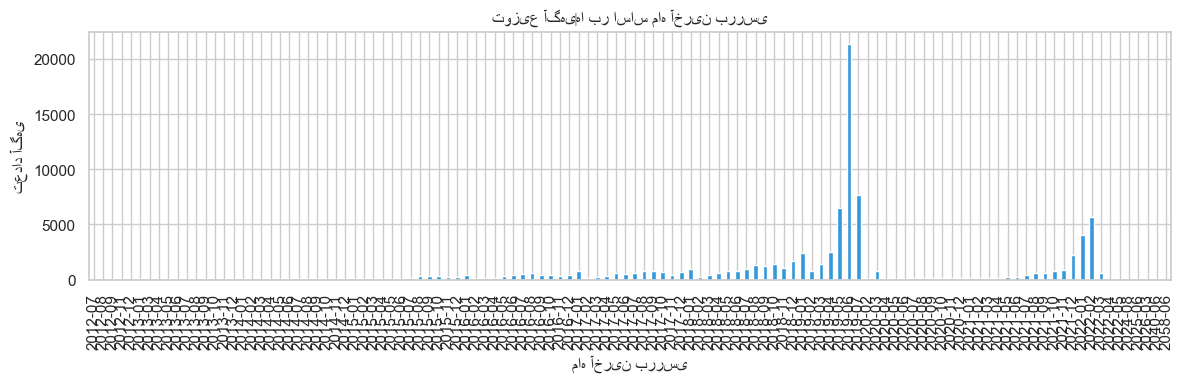

این نمودار تعداد آگهی‌هایی را نشان می‌دهد که آخرین بررسی‌شان در هر ماه ثبت شده است، نه تعداد واقعی همهٔ بررسی‌های آن ماه.
number_of_reviews: تعداد معتبر=101,875، تعداد مفقود=183


,آمار
count,101875.00
mean,27.52
std,49.57
min,0.00
25%,1.00
50%,7.00
75%,31.00
max,1024.00


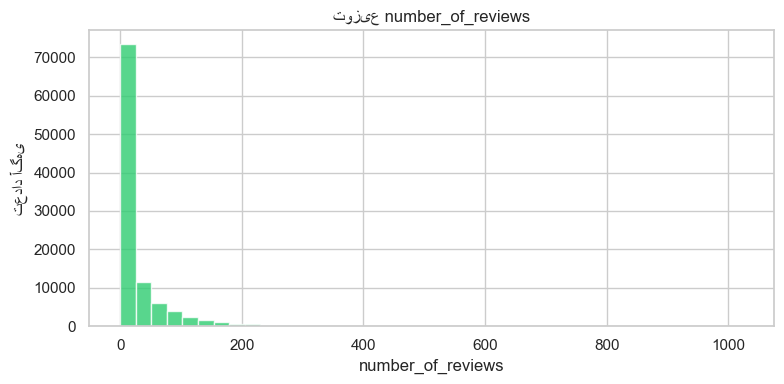

reviews_per_month: تعداد معتبر=86,240، تعداد مفقود=15,818


,آمار
count,86240.00
mean,1.38
std,1.75
min,0.01
25%,0.22
50%,0.74
75%,2.01
max,90.00


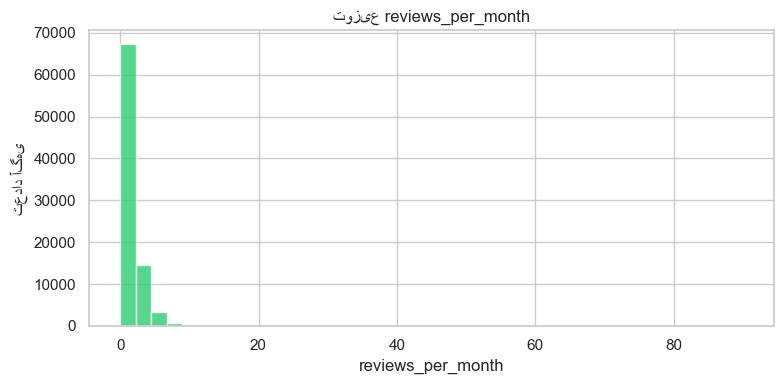

availability_365: تعداد معتبر=98,425، تعداد مفقود=3,633


,آمار
count,98425.00
mean,134.53
std,129.81
min,0.00
25%,2.00
50%,90.00
75%,254.00
max,365.00


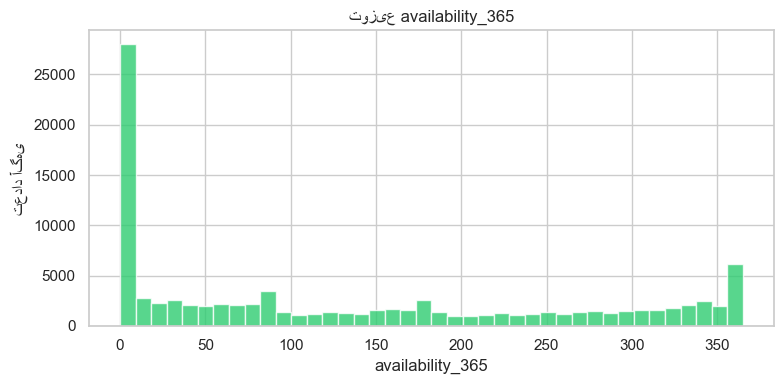

فایل جداگانهٔ تقویم پیدا نشد؛ تحلیل دسترس‌پذیری فقط با availability_365 انجام می‌شود.


,availability_365
count,98425.00
mean,134.53
std,129.81
min,0.00
25%,2.00
50%,90.00
75%,254.00
max,365.00


,تعداد آگهی
مرحله چرخه عمر,
رهاشدهٔ احتمالی,86225
نامشخص,15832
فعالِ تقریبی,1


تعریف عملیاتی: جدیدِ تقریبی یعنی آخرین بررسی حداکثر ۱۲ ماه قبل و حداکثر ۳ بررسی؛ فعالِ تقریبی یعنی آخرین بررسی حداکثر ۱۲ ماه قبل و بیش از ۳ بررسی؛ افولِ تقریبی یعنی ۱۲ تا ۲۴ ماه و نرخ ماهانه مثبت؛ رهاشدهٔ احتمالی یعنی بیش از ۲۴ ماه از آخرین بررسی. این برچسب‌ها شروع یا پایان واقعی فعالیت را ثابت نمی‌کنند.


,سناریو,در بازهٔ اخیر,خارج از بازهٔ اخیر
0,جدید/فعال تا 6 ماه,1,86225
1,جدید/فعال تا 12 ماه,1,86225
2,جدید/فعال تا 18 ماه,1,86225


,سیاست لغو,تعداد آگهی,میانه تعداد بررسی,میانه نرخ بررسی ماهانه,میانه دسترس‌پذیری
1,moderate,34162,7.0,0.75,90.0
2,strict,33929,7.0,0.73,90.0
0,flexible,33891,7.0,0.75,90.0
3,<NA>,76,23.5,0.50,144.0


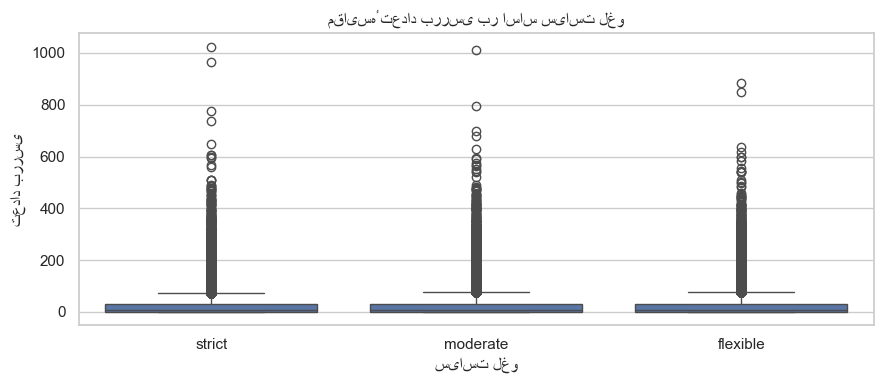

آزمون Kruskal-Wallis برای تعداد بررسی بین سیاست‌ها: آماره=0.8755، p-value=0.645473


,رزرو فوری,تعداد آگهی,میانه تعداد بررسی,میانه نرخ بررسی ماهانه
0,false,51186,7.0,0.74
1,true,50767,7.0,0.75
2,<NA>,105,30.0,0.73


### پاسخ تحلیلی سؤال ۵.۳

**الف) تعریف عملی مراحل چرخهٔ عمر:** چون در این فایل `first_review` و تاریخچهٔ طولی بررسی‌ها وجود ندارد، برچسب‌ها تقریبی‌اند: «جدیدِ تقریبی» آخرین بررسی در ۱۲ ماه اخیر و حداکثر ۳ بررسی، «فعالِ تقریبی» آخرین بررسی در ۱۲ ماه اخیر و بیش از ۳ بررسی، «در حال افولِ تقریبی» آخرین بررسی بین ۱۲ تا ۲۴ ماه و نرخ بررسی ماهانهٔ مثبت، و «رهاشدهٔ احتمالی» بیش از ۲۴ ماه از آخرین بررسی است. مقایسهٔ حساسیت با آستانه‌های ۶، ۱۲ و ۱۸ ماه نیز گزارش شد. این برچسب‌ها غیرفعال‌بودن قطعی، تاریخ شروع فعالیت یا کاهش واقعی تقاضا را ثابت نمی‌کنند.

**ب) تحلیل زمانی، دسترس‌پذیری و ارتباط با سیاست‌های رزرو:** در صورت نبود تاریخچهٔ بررسی، نمودار ماهانه فقط توزیع `last_review` را نشان می‌دهد و شمارش بررسی‌های واقعی ماهانه نیست. چون فایل تقویم جداگانه وجود ندارد، دسترس‌پذیری به `availability_365` محدود شد. جدول‌های سیاست لغو و رزرو فوری، میانهٔ تعداد بررسی، نرخ ماهانه و دسترس‌پذیری را مقایسه می‌کنند. آزمون Kruskal-Wallis فقط تفاوت توزیع تعداد بررسی بین سیاست‌های لغو را می‌سنجد و هیچ رابطهٔ علّی یا راهبرد قطعی میزبان را ثابت نمی‌کند.


In [28]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

clean_path = Path.cwd() / "data" / "airbnb_cleaned.csv"
airbnb_53 = pd.read_csv(clean_path) if clean_path.exists() else None

def col(target):
    wanted = "".join(ch for ch in target.lower() if ch.isalnum())
    if airbnb_53 is None:
        return None
    return next(
        (name for name in airbnb_53.columns
         if "".join(ch for ch in str(name).lower() if ch.isalnum()) == wanted),
        None,
    )

if airbnb_53 is None:
    display(Markdown("**محدودیت:** فایل پاک‌سازی‌شدهٔ Airbnb پیدا نشد؛ سؤال ۵.۳ اجرا نشد."))
else:
    last_review_col = col("last_review")
    first_review_col = col("first_review")
    reviews_month_col = col("reviews_per_month")
    reviews_count_col = col("number_of_reviews")
    availability_col = col("availability_365")
    instant_col = col("instant_bookable")
    policy_col = col("cancellation_policy")
    room_col = col("room_type")
    neighbourhood_col = col("neighbourhood")

    available_columns = pd.DataFrame({
        "ویژگی": ["last_review", "first_review", "reviews_per_month", "number_of_reviews", "availability_365", "instant_bookable", "cancellation_policy"],
        "ستون پیدا‌شده": [last_review_col, first_review_col, reviews_month_col, reviews_count_col, availability_col, instant_col, policy_col],
        "قابل تحلیل": [x is not None for x in [last_review_col, first_review_col, reviews_month_col, reviews_count_col, availability_col, instant_col, policy_col]],
    })
    display(available_columns)

    if last_review_col is not None:
        last_review = pd.to_datetime(airbnb_53[last_review_col], errors="coerce")
        valid_last = last_review.dropna()
        print(f"تعداد تاریخ‌های معتبر آخرین بررسی: {len(valid_last):,}")
        print(f"تعداد تاریخ‌های مفقود یا نامعتبر: {int(last_review.isna().sum()):,}")
        if len(valid_last):
            last_month = valid_last.dt.to_period("M").value_counts().sort_index()
            display(last_month.rename("تعداد آگهی").to_frame().tail(12))
            plt.figure(figsize=(12, 4))
            last_month.plot(kind="bar", color="#3498db")
            plt.title("توزیع آگهی‌ها بر اساس ماه آخرین بررسی")
            plt.xlabel("ماه آخرین بررسی")
            plt.ylabel("تعداد آگهی")
            plt.tight_layout()
            plt.show()
            print("این نمودار تعداد آگهی‌هایی را نشان می‌دهد که آخرین بررسی‌شان در هر ماه ثبت شده است، نه تعداد واقعی همهٔ بررسی‌های آن ماه.")
    else:
        last_review = pd.Series(pd.NaT, index=airbnb_53.index)
        print("ستون last_review وجود ندارد؛ تحلیل تاریخ آخرین بررسی ممکن نیست.")

    for numeric_name, column in [("number_of_reviews", reviews_count_col), ("reviews_per_month", reviews_month_col), ("availability_365", availability_col)]:
        if column is not None:
            numeric = pd.to_numeric(airbnb_53[column], errors="coerce")
            print(f"{numeric_name}: تعداد معتبر={int(numeric.notna().sum()):,}، تعداد مفقود={int(numeric.isna().sum()):,}")
            display(numeric.describe().to_frame("آمار").round(2))
            plt.figure(figsize=(8, 4))
            plt.hist(numeric.dropna(), bins=40, color="#2ecc71", alpha=0.8)
            plt.title(f"توزیع {numeric_name}")
            plt.xlabel(numeric_name)
            plt.ylabel("تعداد آگهی")
            plt.tight_layout()
            plt.show()

    calendar_candidates = sorted((Path.cwd() / "data").glob("*calendar*.csv"))
    if calendar_candidates:
        print(f"فایل تقویم پیدا شد: {calendar_candidates[0]}")
    else:
        print("فایل جداگانهٔ تقویم پیدا نشد؛ تحلیل دسترس‌پذیری فقط با availability_365 انجام می‌شود.")
        if availability_col is not None:
            availability = pd.to_numeric(airbnb_53[availability_col], errors="coerce")
            display(availability.describe().to_frame("availability_365").round(2))

    lifecycle = pd.DataFrame(index=airbnb_53.index)
    if last_review_col is not None:
        reference_date = valid_last.max() if len(valid_last) else pd.NaT
        lifecycle["ماه از آخرین بررسی"] = (reference_date - last_review).dt.days / 30.4375
        lifecycle["تعداد بررسی"] = pd.to_numeric(airbnb_53[reviews_count_col], errors="coerce") if reviews_count_col else np.nan
        lifecycle["بررسی ماهانه"] = pd.to_numeric(airbnb_53[reviews_month_col], errors="coerce") if reviews_month_col else np.nan
        lifecycle["مرحله چرخه عمر"] = "نامشخص"
        recent = lifecycle["ماه از آخرین بررسی"]
        count = lifecycle["تعداد بررسی"].fillna(0)
        monthly = lifecycle["بررسی ماهانه"].fillna(0)
        lifecycle.loc[recent.le(12) & count.le(3), "مرحله چرخه عمر"] = "جدیدِ تقریبی"
        lifecycle.loc[recent.le(12) & ~((count.le(3))), "مرحله چرخه عمر"] = "فعالِ تقریبی"
        lifecycle.loc[recent.gt(12) & recent.le(24) & monthly.gt(0), "مرحله چرخه عمر"] = "در حال افولِ تقریبی"
        lifecycle.loc[recent.gt(24), "مرحله چرخه عمر"] = "رهاشدهٔ احتمالی"
        lifecycle.loc[recent.isna(), "مرحله چرخه عمر"] = "نامشخص"
        display(lifecycle["مرحله چرخه عمر"].value_counts().rename("تعداد آگهی").to_frame())
        print("تعریف عملیاتی: جدیدِ تقریبی یعنی آخرین بررسی حداکثر ۱۲ ماه قبل و حداکثر ۳ بررسی؛ فعالِ تقریبی یعنی آخرین بررسی حداکثر ۱۲ ماه قبل و بیش از ۳ بررسی؛ افولِ تقریبی یعنی ۱۲ تا ۲۴ ماه و نرخ ماهانه مثبت؛ رهاشدهٔ احتمالی یعنی بیش از ۲۴ ماه از آخرین بررسی. این برچسب‌ها شروع یا پایان واقعی فعالیت را ثابت نمی‌کنند.")
        sensitivity = []
        for recent_limit in (6, 12, 18):
            sensitivity.append([f"جدید/فعال تا {recent_limit} ماه", int(recent.le(recent_limit).sum()), int(recent.gt(recent_limit).sum())])
        display(pd.DataFrame(sensitivity, columns=["سناریو", "در بازهٔ اخیر", "خارج از بازهٔ اخیر"]))

    policy_results = []
    if policy_col is not None:
        policy_values = airbnb_53[policy_col].astype("string").str.strip()
        for policy, group in airbnb_53.assign(_policy=policy_values).groupby("_policy", dropna=False):
            row = {"سیاست لغو": str(policy), "تعداد آگهی": len(group)}
            if reviews_count_col:
                row["میانه تعداد بررسی"] = pd.to_numeric(group[reviews_count_col], errors="coerce").median()
            if reviews_month_col:
                row["میانه نرخ بررسی ماهانه"] = pd.to_numeric(group[reviews_month_col], errors="coerce").median()
            if availability_col:
                row["میانه دسترس‌پذیری"] = pd.to_numeric(group[availability_col], errors="coerce").median()
            policy_results.append(row)
        policy_table = pd.DataFrame(policy_results).sort_values("تعداد آگهی", ascending=False)
        display(policy_table.round(2))
        plt.figure(figsize=(9, 4))
        sns.boxplot(data=airbnb_53.assign(_policy=policy_values), x="_policy", y=reviews_count_col)
        plt.title("مقایسهٔ تعداد بررسی بر اساس سیاست لغو")
        plt.xlabel("سیاست لغو")
        plt.ylabel("تعداد بررسی")
        plt.tight_layout()
        plt.show()
        from scipy.stats import kruskal
        groups = [pd.to_numeric(group[reviews_count_col], errors="coerce").dropna() for _, group in airbnb_53.assign(_policy=policy_values).groupby("_policy") if len(pd.to_numeric(group[reviews_count_col], errors="coerce").dropna()) > 0] if reviews_count_col else []
        if len(groups) >= 2:
            statistic, p_value = kruskal(*groups)
            print(f"آزمون Kruskal-Wallis برای تعداد بررسی بین سیاست‌ها: آماره={statistic:.4f}، p-value={p_value:.6g}")
        else:
            print("برای آزمون سیاست‌های لغو، حداقل دو گروه دارای مقدار معتبر کافی وجود ندارد.")

    if instant_col is not None:
        instant_values = airbnb_53[instant_col].astype("string").str.strip().str.lower()
        instant_table = []
        for value, group in airbnb_53.assign(_instant=instant_values).groupby("_instant", dropna=False):
            row = {"رزرو فوری": str(value), "تعداد آگهی": len(group)}
            if reviews_count_col:
                row["میانه تعداد بررسی"] = pd.to_numeric(group[reviews_count_col], errors="coerce").median()
            if reviews_month_col:
                row["میانه نرخ بررسی ماهانه"] = pd.to_numeric(group[reviews_month_col], errors="coerce").median()
            instant_table.append(row)
        display(pd.DataFrame(instant_table).round(2))

    display(Markdown("""### پاسخ تحلیلی سؤال ۵.۳

**الف) تعریف عملی مراحل چرخهٔ عمر:** چون در این فایل `first_review` و تاریخچهٔ طولی بررسی‌ها وجود ندارد، برچسب‌ها تقریبی‌اند: «جدیدِ تقریبی» آخرین بررسی در ۱۲ ماه اخیر و حداکثر ۳ بررسی، «فعالِ تقریبی» آخرین بررسی در ۱۲ ماه اخیر و بیش از ۳ بررسی، «در حال افولِ تقریبی» آخرین بررسی بین ۱۲ تا ۲۴ ماه و نرخ بررسی ماهانهٔ مثبت، و «رهاشدهٔ احتمالی» بیش از ۲۴ ماه از آخرین بررسی است. مقایسهٔ حساسیت با آستانه‌های ۶، ۱۲ و ۱۸ ماه نیز گزارش شد. این برچسب‌ها غیرفعال‌بودن قطعی، تاریخ شروع فعالیت یا کاهش واقعی تقاضا را ثابت نمی‌کنند.

**ب) تحلیل زمانی، دسترس‌پذیری و ارتباط با سیاست‌های رزرو:** در صورت نبود تاریخچهٔ بررسی، نمودار ماهانه فقط توزیع `last_review` را نشان می‌دهد و شمارش بررسی‌های واقعی ماهانه نیست. چون فایل تقویم جداگانه وجود ندارد، دسترس‌پذیری به `availability_365` محدود شد. جدول‌های سیاست لغو و رزرو فوری، میانهٔ تعداد بررسی، نرخ ماهانه و دسترس‌پذیری را مقایسه می‌کنند. آزمون Kruskal-Wallis فقط تفاوت توزیع تعداد بررسی بین سیاست‌های لغو را می‌سنجد و هیچ رابطهٔ علّی یا راهبرد قطعی میزبان را ثابت نمی‌کند.
"""))


### سؤال ۵.۴ — دسته‌بندی میزبان‌ها و مقایسهٔ عملکرد و تمرکز بازار

دسته‌بندی در سطح `host id` انجام می‌شود، نه در سطح هر آگهی. در دادهٔ موجود، `calculated host listings count` به‌عنوان تعداد آگهی قابل استفاده است؛ وضعیت Superhost، نرخ پاسخ، نرخ پذیرش و امتیاز کلی در فایل وجود ندارند و به‌صورت ساختگی جایگزین نمی‌شوند.


C:\Users\MOSALAS\AppData\Local\Temp\ipykernel_16180\3849414037.py:10: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  airbnb_54 = pd.read_csv(clean_path_54) if clean_path_54.exists() else None


,ویژگی موردنظر,ستون واقعی
0,host_id,host id
1,calculated_host_listings_count,calculated host listings count
2,host_total_listings_count,None
3,host_is_superhost,None
4,host_identity_verified,host_identity_verified
5,host_response_rate,None
6,host_acceptance_rate,None
7,cancellation_policy,cancellation_policy
8,instant_bookable,instant_bookable
9,price,price


قاعدهٔ اصلی: میزبانی با حداقل ۳ آگهی اعلام‌شده حرفه‌ای و کمتر از ۳ آگهی معمولی است.


,تعداد میزبان
گروه میزبان,
معمولی,77500
حرفه‌ای,24238


,تعداد آگهی
_host_group,
حرفه‌ای,24238
معمولی,77501


,آستانهٔ آگهی,تعداد میزبان حرفه‌ای,تعداد میزبان معمولی,درصد حرفه‌ای
0,2,38618,63120,37.96
1,3,24238,77500,23.82
2,5,14173,87565,13.93
3,10,8246,93492,8.11


,متغیر,گروه,تعداد معتبر,میانه,میانگین
0,قیمت,معمولی,77330,625.00,625.67
1,قیمت,حرفه‌ای,24162,622.00,624.33
2,تعداد بررسی,معمولی,77346,7.00,27.25
3,تعداد بررسی,حرفه‌ای,24210,8.00,28.33
4,نرخ بررسی ماهانه,معمولی,65012,0.69,1.30
5,نرخ بررسی ماهانه,حرفه‌ای,20967,0.92,1.59
6,امتیاز review,معمولی,77319,3.00,3.26
7,امتیاز review,حرفه‌ای,24169,3.00,3.36


,متغیر,آماره Mann-Whitney,p-value,اندازه اثر رتبه‌ای
0,قیمت,936411914.5,0.582012,0.002342
1,تعداد بررسی,912643318.0,0.000000,-0.025238
2,نرخ بررسی ماهانه,609545651.0,0.000000,-0.105652


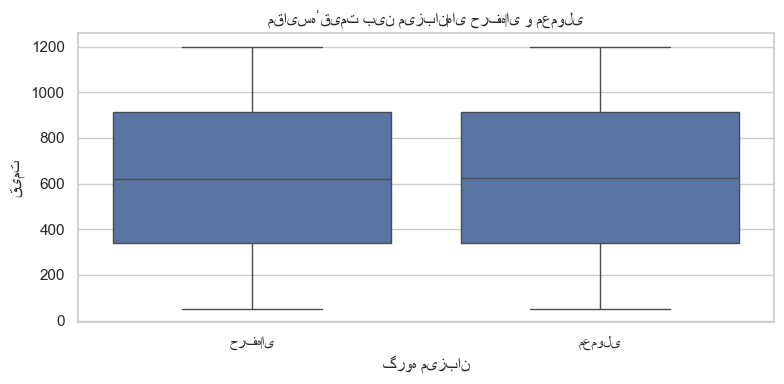

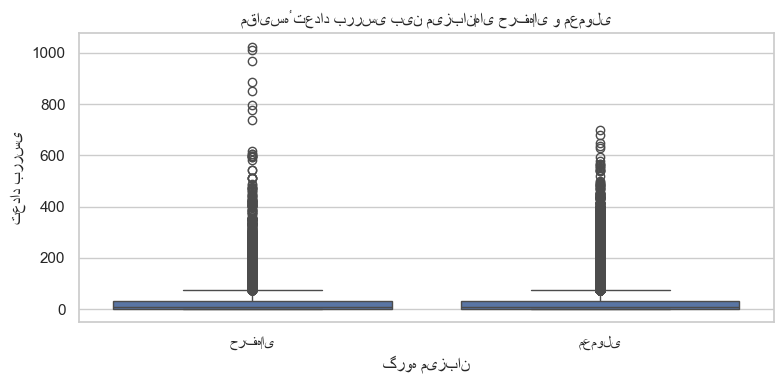

cancellation_policy,flexible,moderate,strict
گروه میزبان,,,
حرفه‌ای,33.50,33.51,32.98
معمولی,33.14,33.50,33.36


instant_bookable,False,True
گروه میزبان,,
حرفه‌ای,50.49,49.51
معمولی,50.13,49.87


آزمون کای‌دو برای سیاست لغو و گروه میزبان: آماره=1.5092، df=2، p-value=0.470207، اندازه اثر Phi=0.0039


,neighbourhood,تعداد_آگهی,تعداد_میزبان,HHI,سهم ۵ میزبان برتر,سهم ۱۰ میزبان برتر
35,"Chelsea, Staten Island",1,1,1.0000,1.0000,1.0
86,Glen Oaks,2,2,0.5000,1.0000,1.0
83,Fort Wadsworth,2,2,0.5000,1.0000,1.0
85,Gerritsen Beach,3,3,0.3333,1.0000,1.0
175,Rossville,3,3,0.3333,1.0000,1.0
218,Willowbrook,3,3,0.3333,1.0000,1.0
222,Woodrow,3,3,0.3333,1.0000,1.0
117,Lighthouse Hill,3,3,0.3333,1.0000,1.0
9,"Bay Terrace, Staten Island",4,4,0.2500,1.0000,1.0
144,New Dorp,4,4,0.2500,1.0000,1.0


فرمول HHI برابر مجموع مربع سهم بازار میزبان‌ها در هر محله است: `HHI = Σ(sᵢ²)`. در اینجا سهم‌ها بین ۰ و ۱ هستند؛ مقدار بزرگ‌تر تمرکز بیشتر را نشان می‌دهد.

### پاسخ تحلیلی سؤال ۵.۴

**الف) قاعدهٔ تفکیک میزبان حرفه‌ای و معمولی:** در سطح `host_id`، آستانهٔ از پیش تعیین‌شدهٔ حداقل ۳ آگهی برای گروه حرفه‌ای و کمتر از آن برای گروه معمولی استفاده شد. تحلیل حساسیت با آستانه‌های ۲، ۵ و ۱۰ آگهی نشان می‌دهد تعداد و سهم گروه حرفه‌ای به تعریف عملیاتی وابسته است. این برچسب، حرفه‌ای‌بودن واقعی یا وضعیت Superhost را ثابت نمی‌کند.

**ب) مقایسهٔ گروه‌ها و تمرکز بازار محله‌ها:** جدول‌های میانه و میانگین، آزمون Mann-Whitney و اندازه اثر رتبه‌ای، تفاوت قیمت و فعالیت بررسی را گزارش می‌کنند. جدول‌های سیاست لغو و رزرو فوری به‌صورت درصدی مقایسه شده‌اند و آزمون کای‌دو برای سیاست لغو، در صورت کفایت جدول، وابستگی آماری را بررسی می‌کند. HHI، سهم ۵ و ۱۰ میزبان برتر برای محله‌ها محاسبه شده‌اند. هیچ‌یک از این تفاوت‌ها به‌تنهایی رابطهٔ علّی یا راهبرد میزبان را ثابت نمی‌کند. ستون‌های Superhost، نرخ پاسخ، نرخ پذیرش و امتیاز کلی در داده موجود نیستند و تحلیل آن‌ها انجام نشد.


In [29]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import mannwhitneyu, chi2_contingency

clean_path_54 = Path.cwd() / "data" / "airbnb_cleaned.csv"
airbnb_54 = pd.read_csv(clean_path_54) if clean_path_54.exists() else None

def find_54(target):
    if airbnb_54 is None:
        return None
    wanted = "".join(ch for ch in target.lower() if ch.isalnum())
    return next(
        (name for name in airbnb_54.columns
         if "".join(ch for ch in str(name).lower() if ch.isalnum()) == wanted),
        None,
    )

if airbnb_54 is None:
    display(Markdown("**محدودیت:** فایل پاک‌سازی‌شدهٔ Airbnb پیدا نشد؛ سؤال ۵.۴ اجرا نشد."))
else:
    requested = [
        "host_id", "calculated_host_listings_count", "host_total_listings_count",
        "host_is_superhost", "host_identity_verified", "host_response_rate",
        "host_acceptance_rate", "cancellation_policy", "instant_bookable",
        "price", "number_of_reviews", "reviews_per_month", "review_rate_number",
        "room_type", "neighbourhood",
    ]
    columns_table = pd.DataFrame({
        "ویژگی موردنظر": requested,
        "ستون واقعی": [find_54(name) for name in requested],
    })
    display(columns_table)

    host_id_col = find_54("host_id")
    listings_col = find_54("calculated_host_listings_count")
    price_col = find_54("price")
    reviews_col = find_54("number_of_reviews")
    monthly_col = find_54("reviews_per_month")
    policy_col = find_54("cancellation_policy")
    instant_col = find_54("instant_bookable")
    neighbourhood_col = find_54("neighbourhood")

    if host_id_col is None or listings_col is None:
        display(Markdown("**محدودیت:** `host_id` یا تعداد آگهی میزبان وجود ندارد؛ دسته‌بندی حرفه‌ای/معمولی و تمرکز بازار قابل محاسبه نیست."))
    else:
        host_values = airbnb_54[host_id_col]
        listing_counts = pd.to_numeric(airbnb_54[listings_col], errors="coerce")
        valid_host = host_values.notna() & listing_counts.notna() & listing_counts.ge(0)
        data = airbnb_54.loc[valid_host].copy()
        data["_host_listings"] = listing_counts.loc[valid_host]
        professional_threshold = 3
        data["_host_group"] = np.where(
            data["_host_listings"] >= professional_threshold,
            "حرفه‌ای",
            "معمولی",
        )
        host_level = data.groupby(host_id_col, dropna=False).agg(
            تعداد_آگهی=("_host_listings", "size"),
            تعداد_آگهی_اعلام‌شده=("_host_listings", "first"),
        ).reset_index()
        host_level["گروه میزبان"] = np.where(
            host_level["تعداد_آگهی_اعلام‌شده"] >= professional_threshold,
            "حرفه‌ای",
            "معمولی",
        )
        print("قاعدهٔ اصلی: میزبانی با حداقل ۳ آگهی اعلام‌شده حرفه‌ای و کمتر از ۳ آگهی معمولی است.")
        display(host_level["گروه میزبان"].value_counts().rename("تعداد میزبان").to_frame())
        display(data.groupby("_host_group").size().rename("تعداد آگهی").to_frame())

        sensitivity_rows = []
        for threshold in (2, 3, 5, 10):
            host_level[f"group_{threshold}"] = np.where(
                host_level["تعداد_آگهی_اعلام‌شده"] >= threshold,
                "حرفه‌ای",
                "معمولی",
            )
            sensitivity_rows.append([
                threshold,
                int((host_level[f"group_{threshold}"] == "حرفه‌ای").sum()),
                int((host_level[f"group_{threshold}"] == "معمولی").sum()),
                round(float((host_level[f"group_{threshold}"] == "حرفه‌ای").mean() * 100), 2),
            ])
        display(pd.DataFrame(sensitivity_rows, columns=["آستانهٔ آگهی", "تعداد میزبان حرفه‌ای", "تعداد میزبان معمولی", "درصد حرفه‌ای"]))

        numeric_comparisons = []
        for label, column in [
            ("قیمت", price_col), ("تعداد بررسی", reviews_col),
            ("نرخ بررسی ماهانه", monthly_col), ("امتیاز review", find_54("review_rate_number")),
        ]:
            if column is None:
                continue
            values = pd.to_numeric(data[column], errors="coerce")
            for group_name in ("معمولی", "حرفه‌ای"):
                group_values = values[data["_host_group"] == group_name].dropna()
                numeric_comparisons.append([
                    label, group_name, len(group_values),
                    group_values.median() if len(group_values) else np.nan,
                    group_values.mean() if len(group_values) else np.nan,
                ])
        display(pd.DataFrame(numeric_comparisons, columns=["متغیر", "گروه", "تعداد معتبر", "میانه", "میانگین"]).round(2))

        tests = []
        for label, column in [("قیمت", price_col), ("تعداد بررسی", reviews_col), ("نرخ بررسی ماهانه", monthly_col)]:
            if column is None:
                continue
            values = pd.to_numeric(data[column], errors="coerce")
            ordinary = values[data["_host_group"] == "معمولی"].dropna()
            professional = values[data["_host_group"] == "حرفه‌ای"].dropna()
            if len(ordinary) and len(professional):
                statistic, p_value = mannwhitneyu(ordinary, professional, alternative="two-sided")
                effect = 2 * statistic / (len(ordinary) * len(professional)) - 1
                tests.append([label, statistic, p_value, effect])
        display(pd.DataFrame(tests, columns=["متغیر", "آماره Mann-Whitney", "p-value", "اندازه اثر رتبه‌ای"]).round(6))

        for column, title in [(price_col, "قیمت"), (reviews_col, "تعداد بررسی")]:
            if column is not None:
                plot_data = data.copy()
                plot_data["_value"] = pd.to_numeric(plot_data[column], errors="coerce")
                plt.figure(figsize=(8, 4))
                sns.boxplot(data=plot_data, x="_host_group", y="_value")
                plt.title(f"مقایسهٔ {title} بین میزبان‌های حرفه‌ای و معمولی")
                plt.xlabel("گروه میزبان")
                plt.ylabel(title)
                plt.tight_layout()
                plt.show()

        for column, title in [(policy_col, "سیاست لغو"), (instant_col, "رزرو فوری")]:
            if column is not None:
                table = pd.crosstab(data["_host_group"], data[column], normalize="index").mul(100).round(2)
                table.index.name = "گروه میزبان"
                display(table)
        if policy_col is not None:
            policy_table = pd.crosstab(data["_host_group"], data[policy_col])
            if policy_table.shape[0] >= 2 and policy_table.shape[1] >= 2:
                chi2, p_value, dof, expected = chi2_contingency(policy_table)
                n = policy_table.to_numpy().sum()
                phi = np.sqrt(chi2 / n)
                print(f"آزمون کای‌دو برای سیاست لغو و گروه میزبان: آماره={chi2:.4f}، df={dof}، p-value={p_value:.6g}، اندازه اثر Phi={phi:.4f}")

        if neighbourhood_col is not None:
            market = data.dropna(subset=[neighbourhood_col]).groupby([neighbourhood_col, host_id_col]).size().rename("تعداد آگهی").reset_index()
            market["کل آگهی محله"] = market.groupby(neighbourhood_col)["تعداد آگهی"].transform("sum")
            market["سهم میزبان"] = market["تعداد آگهی"] / market["کل آگهی محله"]
            concentration = market.groupby(neighbourhood_col).agg(
                تعداد_آگهی=("تعداد آگهی", "sum"),
                تعداد_میزبان=(host_id_col, "nunique"),
                HHI=("سهم میزبان", lambda values: float((values ** 2).sum())),
            ).reset_index()
            concentration["سهم ۵ میزبان برتر"] = market.groupby(neighbourhood_col)["سهم میزبان"].apply(lambda values: values.nlargest(5).sum()).values
            concentration["سهم ۱۰ میزبان برتر"] = market.groupby(neighbourhood_col)["سهم میزبان"].apply(lambda values: values.nlargest(10).sum()).values
            concentration = concentration.sort_values("HHI", ascending=False)
            display(concentration.head(20).round(4))
            display(Markdown("فرمول HHI برابر مجموع مربع سهم بازار میزبان‌ها در هر محله است: `HHI = Σ(sᵢ²)`. در اینجا سهم‌ها بین ۰ و ۱ هستند؛ مقدار بزرگ‌تر تمرکز بیشتر را نشان می‌دهد."))

        display(Markdown("""### پاسخ تحلیلی سؤال ۵.۴

**الف) قاعدهٔ تفکیک میزبان حرفه‌ای و معمولی:** در سطح `host_id`، آستانهٔ از پیش تعیین‌شدهٔ حداقل ۳ آگهی برای گروه حرفه‌ای و کمتر از آن برای گروه معمولی استفاده شد. تحلیل حساسیت با آستانه‌های ۲، ۵ و ۱۰ آگهی نشان می‌دهد تعداد و سهم گروه حرفه‌ای به تعریف عملیاتی وابسته است. این برچسب، حرفه‌ای‌بودن واقعی یا وضعیت Superhost را ثابت نمی‌کند.

**ب) مقایسهٔ گروه‌ها و تمرکز بازار محله‌ها:** جدول‌های میانه و میانگین، آزمون Mann-Whitney و اندازه اثر رتبه‌ای، تفاوت قیمت و فعالیت بررسی را گزارش می‌کنند. جدول‌های سیاست لغو و رزرو فوری به‌صورت درصدی مقایسه شده‌اند و آزمون کای‌دو برای سیاست لغو، در صورت کفایت جدول، وابستگی آماری را بررسی می‌کند. HHI، سهم ۵ و ۱۰ میزبان برتر برای محله‌ها محاسبه شده‌اند. هیچ‌یک از این تفاوت‌ها به‌تنهایی رابطهٔ علّی یا راهبرد میزبان را ثابت نمی‌کند. ستون‌های Superhost، نرخ پاسخ، نرخ پذیرش و امتیاز کلی در داده موجود نیستند و تحلیل آن‌ها انجام نشد.
"""))


### سؤال ۵.۵ — ویژگی‌های مکانی، سال ساخت، PCA و شناسایی مناطق بالقوه سرمایه‌گذاری

این تحلیل از `airbnb_cleaned.csv` استفاده می‌کند. مرکز رسمی شهر در داده موجود نیست؛ بنابراین میانهٔ مختصات معتبر به‌عنوان «مرکز تقریبی نمونه» تعریف می‌شود. نتایج سرمایه‌گذاری فقط غربالگری اولیه هستند و توصیهٔ قطعی سرمایه‌گذاری محسوب نمی‌شوند.


C:\Users\MOSALAS\AppData\Local\Temp\ipykernel_16180\1073546633.py:13: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  airbnb_55 = pd.read_csv(clean_path_55) if clean_path_55.exists() else None


,ویژگی موردنظر,ستون واقعی,نوع داده,تعداد مفقود
0,latitude,None,موجود نیست,NaN
1,longitude,None,موجود نیست,NaN
2,lat,lat,float64,8.0
3,long,long,float64,8.0
4,neighbourhood,neighbourhood,object,16.0
5,neighbourhood_cleansed,None,موجود نیست,NaN
6,price,price,float64,247.0
7,room_type,room type,object,0.0
8,property_type,None,موجود نیست,NaN
9,Construction year,Construction year,float64,214.0


مرکز تقریبی نمونه بر اساس میانهٔ مختصات: latitude=40.722290, longitude=-73.954440
تعداد مختصات معتبر: 102,050؛ تعداد مختصات مفقود/نامعتبر: 8


,تعداد آگهی,تراکم تعریف‌شده
محله,,
Bedford-Stuyvesant,7898,7898
Williamsburg,7732,7732
Harlem,5441,5441
Bushwick,4956,4956
Hell's Kitchen,3949,3949
Upper West Side,3841,3841
Upper East Side,3656,3656
East Village,3477,3477
Midtown,3357,3357


,تعداد_آگهی,میانه_قیمت,میانگین_قیمت
neighbourhood,,,
Lighthouse Hill,3,127.0,107.67
Richmondtown,5,212.0,373.40
Spuyten Duyvil,9,215.0,293.44
Breezy Point,9,232.0,309.89
Rossville,3,247.0,300.67
Co-op City,5,278.0,527.60
Emerson Hill,10,317.0,443.80
New Dorp Beach,11,323.0,571.36
Castleton Corners,13,335.0,417.23


داده مقطعی است؛ تفاوت قیمت محله‌ها گزارش می‌شود و روند زمانی قیمت ادعا نمی‌شود.
سال ساخت معتبر: 101,844؛ سال ساخت مفقود/نامعتبر: 214


,مؤلفه,درصد واریانس تبیین‌شده,درصد تجمعی
0,1,18.874,18.874
1,2,15.546,34.420
2,3,11.668,46.088
3,4,11.188,57.277
4,5,11.106,68.382
5,6,11.036,79.419
6,7,9.793,89.212
7,8,6.413,95.625
8,9,4.375,100.000


تعداد مؤلفه‌های منتخب: 5؛ معیار: رسیدن تجمعی به حداقل ۸۰٪ یا سقف ۵ مؤلفه.


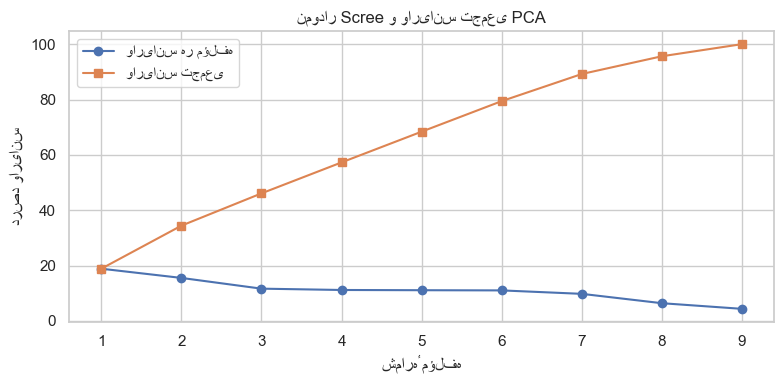

,PC1,PC2,PC3,PC4,PC5
log_price,0.015,-0.004,-0.102,-0.358,0.824
distance_km,0.330,-0.592,-0.136,-0.001,-0.040
neighbourhood_density,-0.260,0.633,0.128,-0.003,0.036
building_age,0.008,-0.045,0.039,-0.651,0.109
review_score,0.026,-0.025,-0.071,0.667,0.540
number_of_reviews,0.602,0.342,0.058,-0.036,-0.024
reviews_per_month,0.624,0.297,-0.009,0.022,0.011
availability_365,0.241,-0.173,0.576,0.018,0.058
minimum_nights,-0.111,-0.102,0.783,0.035,0.097


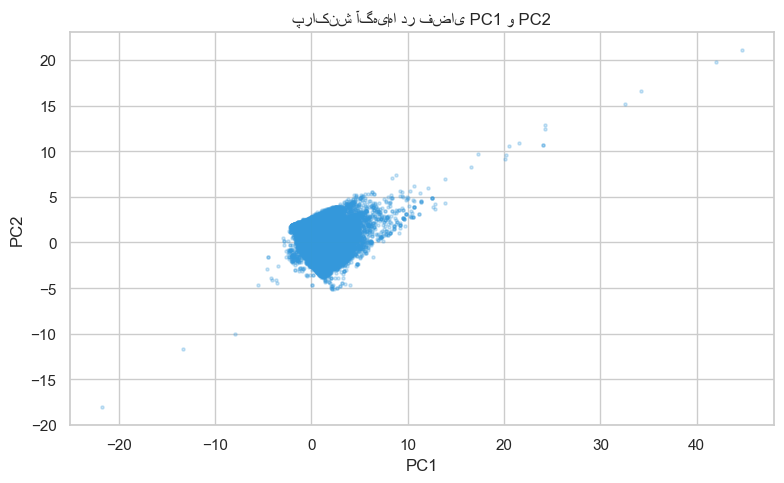

,تعداد خوشه,Silhouette Score
0,2,0.5654
1,3,0.4537
2,4,0.4530
3,5,0.4219
4,6,0.3790


,neighbourhood,PC1,PC2,خوشه
0,Allerton,1.958,-2.094,0
1,Arden Heights,1.986,-3.782,0
2,Arrochar,1.391,-2.462,0
3,Arverne,1.602,-2.605,0
4,Astoria,0.025,-0.183,1
5,Bath Beach,1.283,-1.778,0
6,Battery Park City,-0.229,-0.828,1
7,Bay Ridge,0.867,-1.454,0
8,Bay Terrace,1.197,-2.275,0
9,"Bay Terrace, Staten Island",0.847,-3.532,0


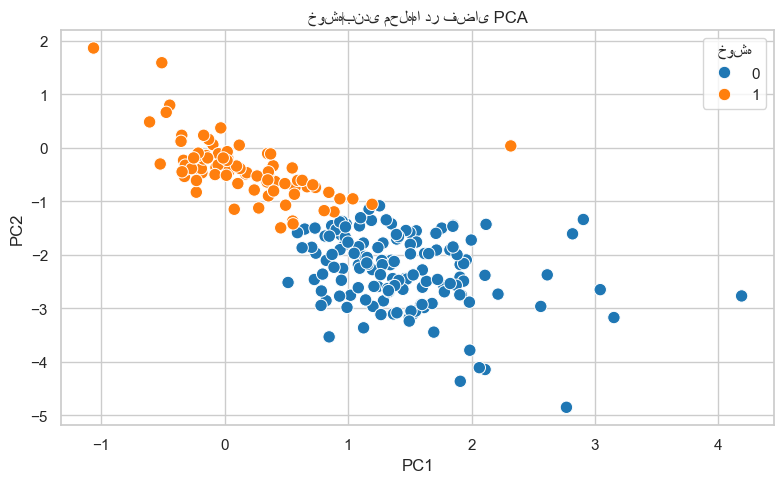

,تعداد_آگهی,میانه_قیمت,فاصله_مرکز,خوشه
neighbourhood,,,,
Lighthouse Hill,3,127.0,21.93,0
Richmondtown,5,212.0,22.10,0
Spuyten Duyvil,9,215.0,17.92,0
Breezy Point,9,232.0,18.78,0
Rossville,3,247.0,29.01,0
Co-op City,5,278.0,19.16,0
Emerson Hill,10,317.0,19.21,0
New Dorp Beach,11,323.0,21.44,0
Castleton Corners,13,335.0,18.63,0


مناطق بالا فقط برای غربالگری اولیه بر اساس قیمت میانهٔ پایین‌تر معرفی شده‌اند؛ هزینهٔ خرید، بازسازی، مقررات و بازده اجاره در داده وجود ندارد.


### پاسخ تحلیلی سؤال ۵.۵

**الف) درصد واریانس تبیین‌شده با مؤلفه‌های منتخب PCA:** جدول واریانس هر مؤلفه و واریانس تجمعی در خروجی بالا از اجرای واقعی PCA روی ویژگی‌های عددی استانداردشده ارائه شد. تعداد مؤلفه‌ها با هدف رسیدن به حداقل ۸۰٪ واریانس تجمعی، با سقف ۵ مؤلفه، انتخاب شد؛ شناسه‌های `id` و `host_id` وارد PCA نشدند.

**ب) ویژگی‌های مکانی، نمودار PCA و مناطق پیشنهادی:** فاصله با فرمول Haversine تا مرکز تقریبی نمونه محاسبه شد و تراکم محله به‌صورت تعداد آگهی در هر محله تعریف شد. چون داده یک مقطع زمانی است، تفاوت قیمت محله‌ها گزارش شد و روند زمانی ادعا نشد. بارهای PCA جهت اثر ویژگی‌ها را نشان می‌دهند، نه رابطهٔ علّی. محله‌های کم‌قیمت‌تر برای بررسی اولیه فهرست شدند؛ نبود قیمت خرید ملک، هزینهٔ بازسازی، مقررات، بازده اجاره و اطلاعات کامل سال ساخت، مانع هرگونه توصیهٔ قطعی سرمایه‌گذاری است.


In [30]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

clean_path_55 = Path.cwd() / "data" / "airbnb_cleaned.csv"
airbnb_55 = pd.read_csv(clean_path_55) if clean_path_55.exists() else None

def find_55(target):
    if airbnb_55 is None:
        return None
    wanted = "".join(ch for ch in target.lower() if ch.isalnum())
    return next(
        (name for name in airbnb_55.columns
         if "".join(ch for ch in str(name).lower() if ch.isalnum()) == wanted),
        None,
    )

if airbnb_55 is None:
    display(Markdown("**محدودیت:** فایل پاک‌سازی‌شدهٔ Airbnb پیدا نشد؛ سؤال ۵.۵ اجرا نشد."))
else:
    requested = [
        "latitude", "longitude", "lat", "long", "neighbourhood",
        "neighbourhood_cleansed", "price", "room_type", "property_type",
        "Construction year", "review_rate_number", "number_of_reviews",
        "reviews_per_month", "availability_365", "minimum_nights",
    ]
    feature_rows = []
    for requested_name in requested:
        column = find_55(requested_name)
        feature_rows.append([
            requested_name,
            column,
            str(airbnb_55[column].dtype) if column else "موجود نیست",
            int(airbnb_55[column].isna().sum()) if column else np.nan,
        ])
    display(pd.DataFrame(feature_rows, columns=["ویژگی موردنظر", "ستون واقعی", "نوع داده", "تعداد مفقود"]))

    lat_col = find_55("latitude") or find_55("lat")
    lon_col = find_55("longitude") or find_55("long")
    neighbourhood_col = find_55("neighbourhood") or find_55("neighbourhood_cleansed")
    price_col = find_55("price")
    year_col = find_55("Construction year")
    if lat_col is not None and lon_col is not None:
        lat = pd.to_numeric(airbnb_55[lat_col], errors="coerce")
        lon = pd.to_numeric(airbnb_55[lon_col], errors="coerce")
        valid_coordinates = lat.notna() & lon.notna()
        center_lat = float(lat[valid_coordinates].median())
        center_lon = float(lon[valid_coordinates].median())
        earth_radius_km = 6371.0088
        lat_radians = np.radians(lat)
        lon_radians = np.radians(lon)
        delta_lat = lat_radians - np.radians(center_lat)
        delta_lon = lon_radians - np.radians(center_lon)
        haversine_a = np.sin(delta_lat / 2) ** 2 + np.cos(lat_radians) * np.cos(np.radians(center_lat)) * np.sin(delta_lon / 2) ** 2
        airbnb_55["فاصله تا مرکز تقریبی (km)"] = 2 * earth_radius_km * np.arcsin(np.sqrt(haversine_a))
        print(f"مرکز تقریبی نمونه بر اساس میانهٔ مختصات: latitude={center_lat:.6f}, longitude={center_lon:.6f}")
        print(f"تعداد مختصات معتبر: {int(valid_coordinates.sum()):,}؛ تعداد مختصات مفقود/نامعتبر: {int((~valid_coordinates).sum()):,}")
    else:
        airbnb_55["فاصله تا مرکز تقریبی (km)"] = np.nan
        print("مختصات معتبر برای محاسبهٔ فاصله وجود ندارد.")

    if neighbourhood_col is not None:
        neighbourhood_counts = airbnb_55[neighbourhood_col].value_counts(dropna=False).rename_axis("محله").rename("تعداد آگهی").to_frame()
        neighbourhood_counts["تراکم تعریف‌شده"] = neighbourhood_counts["تعداد آگهی"]
        display(neighbourhood_counts.head(20))
        if price_col is not None:
            price_numeric = pd.to_numeric(airbnb_55[price_col], errors="coerce")
            neighbourhood_price = airbnb_55.assign(_price=price_numeric).groupby(neighbourhood_col).agg(
                تعداد_آگهی=("_price", "size"),
                میانه_قیمت=("_price", "median"),
                میانگین_قیمت=("_price", "mean"),
            ).sort_values("میانه_قیمت")
            display(neighbourhood_price.head(20).round(2))
            print("داده مقطعی است؛ تفاوت قیمت محله‌ها گزارش می‌شود و روند زمانی قیمت ادعا نمی‌شود.")
    else:
        print("ستون محله وجود ندارد؛ مقایسهٔ محله‌ای انجام نشد.")

    if year_col is not None:
        construction_year = pd.to_numeric(airbnb_55[year_col], errors="coerce")
        valid_year = construction_year.between(1800, 2025)
        print(f"سال ساخت معتبر: {int(valid_year.sum()):,}؛ سال ساخت مفقود/نامعتبر: {int((~valid_year).sum()):,}")
        airbnb_55["سن ساختمان در سال مرجع 2021"] = 2021 - construction_year.where(valid_year)
    else:
        airbnb_55["سن ساختمان در سال مرجع 2021"] = np.nan
        print("سال ساخت ساختمان وجود ندارد؛ سن ساختمان از شناسه یا تاریخ بررسی حدس زده نشد.")

    numeric_candidates = {
        "log_price": np.log1p(pd.to_numeric(airbnb_55[price_col], errors="coerce").clip(lower=0)) if price_col else None,
        "distance_km": airbnb_55["فاصله تا مرکز تقریبی (km)"],
        "neighbourhood_density": airbnb_55[neighbourhood_col].map(airbnb_55[neighbourhood_col].value_counts()) if neighbourhood_col else None,
        "building_age": airbnb_55["سن ساختمان در سال مرجع 2021"],
        "review_score": pd.to_numeric(airbnb_55[find_55("review_rate_number")], errors="coerce") if find_55("review_rate_number") else None,
        "number_of_reviews": pd.to_numeric(airbnb_55[find_55("number_of_reviews")], errors="coerce") if find_55("number_of_reviews") else None,
        "reviews_per_month": pd.to_numeric(airbnb_55[find_55("reviews_per_month")], errors="coerce") if find_55("reviews_per_month") else None,
        "availability_365": pd.to_numeric(airbnb_55[find_55("availability_365")], errors="coerce") if find_55("availability_365") else None,
        "minimum_nights": pd.to_numeric(airbnb_55[find_55("minimum_nights")], errors="coerce") if find_55("minimum_nights") else None,
    }
    numeric_features = pd.DataFrame({name: series for name, series in numeric_candidates.items() if series is not None}, index=airbnb_55.index)
    numeric_features = numeric_features.replace([np.inf, -np.inf], np.nan)
    numeric_features = numeric_features.loc[:, numeric_features.notna().any()]
    if numeric_features.shape[1] < 2 or len(numeric_features) < 3:
        print("ویژگی عددی کافی برای PCA وجود ندارد؛ PCA اجرا نشد.")
    else:
        numeric_features = numeric_features.fillna(numeric_features.median())
        scaled_features = StandardScaler().fit_transform(numeric_features)
        pca_full = PCA(random_state=42).fit(scaled_features)
        pca_scores = pca_full.transform(scaled_features)
        explained = pca_full.explained_variance_ratio_ * 100
        cumulative = np.cumsum(explained)
        component_table = pd.DataFrame({
            "مؤلفه": np.arange(1, len(explained) + 1),
            "درصد واریانس تبیین‌شده": explained,
            "درصد تجمعی": cumulative,
        })
        display(component_table.round(3))
        selected_components = int(np.searchsorted(cumulative, 80) + 1)
        selected_components = min(selected_components, min(5, len(explained)))
        print(f"تعداد مؤلفه‌های منتخب: {selected_components}؛ معیار: رسیدن تجمعی به حداقل ۸۰٪ یا سقف ۵ مؤلفه.")
        plt.figure(figsize=(8, 4))
        plt.plot(component_table["مؤلفه"], component_table["درصد واریانس تبیین‌شده"], marker="o", label="واریانس هر مؤلفه")
        plt.plot(component_table["مؤلفه"], component_table["درصد تجمعی"], marker="s", label="واریانس تجمعی")
        plt.title("نمودار Scree و واریانس تجمعی PCA")
        plt.xlabel("شمارهٔ مؤلفه")
        plt.ylabel("درصد واریانس")
        plt.legend()
        plt.tight_layout()
        plt.show()
        loadings = pd.DataFrame(
            pca_full.components_[:selected_components].T,
            index=numeric_features.columns,
            columns=[f"PC{i}" for i in range(1, selected_components + 1)],
        )
        display(loadings.round(3))
        pca_display = pd.DataFrame({"PC1": pca_scores[:, 0], "PC2": pca_scores[:, 1]}, index=airbnb_55.index)
        plt.figure(figsize=(8, 5))
        plt.scatter(pca_display["PC1"], pca_display["PC2"], s=5, alpha=0.25, color="#3498db")
        plt.title("پراکنش آگهی‌ها در فضای PC1 و PC2")
        plt.xlabel("PC1")
        plt.ylabel("PC2")
        plt.tight_layout()
        plt.show()

        if neighbourhood_col is not None:
            pca_display[neighbourhood_col] = airbnb_55[neighbourhood_col].values
            neighbourhood_pca = pca_display.groupby(neighbourhood_col)[["PC1", "PC2"]].mean().dropna()
            if len(neighbourhood_pca) >= 3:
                max_k = min(6, len(neighbourhood_pca) - 1)
                cluster_scores = []
                for k in range(2, max_k + 1):
                    cluster_labels = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(neighbourhood_pca[["PC1", "PC2"]])
                    cluster_scores.append([k, silhouette_score(neighbourhood_pca[["PC1", "PC2"]], cluster_labels)])
                cluster_table = pd.DataFrame(cluster_scores, columns=["تعداد خوشه", "Silhouette Score"])
                selected_k = int(cluster_table.loc[cluster_table["Silhouette Score"].idxmax(), "تعداد خوشه"])
                display(cluster_table.round(4))
                final_labels = KMeans(n_clusters=selected_k, random_state=42, n_init=20).fit_predict(neighbourhood_pca[["PC1", "PC2"]])
                neighbourhood_pca["خوشه"] = final_labels
                display(neighbourhood_pca.reset_index().head(20).round(3))
                plt.figure(figsize=(8, 5))
                sns.scatterplot(data=neighbourhood_pca, x="PC1", y="PC2", hue="خوشه", palette="tab10", s=80)
                plt.title("خوشه‌بندی محله‌ها در فضای PCA")
                plt.xlabel("PC1")
                plt.ylabel("PC2")
                plt.legend(title="خوشه")
                plt.tight_layout()
                plt.show()
                if price_col is not None:
                    price_values = pd.to_numeric(airbnb_55[price_col], errors="coerce")
                    neighbourhood_summary = airbnb_55.assign(_price=price_values).groupby(neighbourhood_col).agg(
                        تعداد_آگهی=("_price", "size"),
                        میانه_قیمت=("_price", "median"),
                        فاصله_مرکز=("فاصله تا مرکز تقریبی (km)", "median"),
                    )
                    neighbourhood_summary["خوشه"] = neighbourhood_pca["خوشه"]
                    price_cut = neighbourhood_summary["میانه_قیمت"].quantile(0.25)
                    activity_cut = airbnb_55.groupby(neighbourhood_col)[find_55("number_of_reviews")].median().quantile(0.75) if find_55("number_of_reviews") else np.nan
                    candidates = neighbourhood_summary[neighbourhood_summary["میانه_قیمت"].le(price_cut)].sort_values(["میانه_قیمت", "تعداد_آگهی"]).head(10)
                    display(candidates.round(2))
                    print("مناطق بالا فقط برای غربالگری اولیه بر اساس قیمت میانهٔ پایین‌تر معرفی شده‌اند؛ هزینهٔ خرید، بازسازی، مقررات و بازده اجاره در داده وجود ندارد.")

        display(Markdown("""### پاسخ تحلیلی سؤال ۵.۵

**الف) درصد واریانس تبیین‌شده با مؤلفه‌های منتخب PCA:** جدول واریانس هر مؤلفه و واریانس تجمعی در خروجی بالا از اجرای واقعی PCA روی ویژگی‌های عددی استانداردشده ارائه شد. تعداد مؤلفه‌ها با هدف رسیدن به حداقل ۸۰٪ واریانس تجمعی، با سقف ۵ مؤلفه، انتخاب شد؛ شناسه‌های `id` و `host_id` وارد PCA نشدند.

**ب) ویژگی‌های مکانی، نمودار PCA و مناطق پیشنهادی:** فاصله با فرمول Haversine تا مرکز تقریبی نمونه محاسبه شد و تراکم محله به‌صورت تعداد آگهی در هر محله تعریف شد. چون داده یک مقطع زمانی است، تفاوت قیمت محله‌ها گزارش شد و روند زمانی ادعا نشد. بارهای PCA جهت اثر ویژگی‌ها را نشان می‌دهند، نه رابطهٔ علّی. محله‌های کم‌قیمت‌تر برای بررسی اولیه فهرست شدند؛ نبود قیمت خرید ملک، هزینهٔ بازسازی، مقررات، بازده اجاره و اطلاعات کامل سال ساخت، مانع هرگونه توصیهٔ قطعی سرمایه‌گذاری است.
"""))


### درصد واریانس تبیین‌شده با مؤلفه‌های منتخب PCA

در اجرای واقعی PCA، پنج مؤلفهٔ منتخب به‌ترتیب **۱۸٫۸۷۴٪، ۱۵٫۵۴۶٪، ۱۱٫۶۶۸٪، ۱۱٫۱۸۸٪ و ۱۱٫۱۰۶٪** از واریانس را تبیین کردند. واریانس تجمعی این پنج مؤلفه **۶۸٫۳۸۲٪** است. پنج مؤلفه به‌دلیل سقف تعیین‌شده انتخاب شدند؛ برای رسیدن به حداقل ۸۰٪، هفت مؤلفه لازم بود که واریانس تجمعی آن‌ها **۸۹٫۲۱۲٪** می‌شد.

## ۶. تحلیل خطوط هوایی

این بخش روی فایل خام `data/Airline Dataset.csv` که از یک منبع عمومی اینترنتی دانلود شده اجرا می‌شود. فایل خام تغییر نمی‌کند و نسخهٔ پاک‌سازی‌شده در `data/airline_cleaned.csv` ذخیره خواهد شد.

In [31]:
from pathlib import Path
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path.cwd() / "data"
RAW_PATH = DATA_DIR / "Airline Dataset.csv"
CLEAN_PATH = DATA_DIR / "airline_cleaned.csv"
raw_df = pd.read_csv(RAW_PATH, encoding="utf-8")
df = raw_df.copy(deep=True)
row_count_before = len(df)
print(f"Initial rows: {row_count_before:,}")
print("Columns:", list(df.columns))
print("Raw source:", RAW_PATH)


Initial rows: 98,619
Columns: ['Passenger ID', 'First Name', 'Last Name', 'Gender', 'Age', 'Nationality', 'Airport Name', 'Airport Country Code', 'Country Name', 'Airport Continent', 'Continents', 'Departure Date', 'Arrival Airport', 'Pilot Name', 'Flight Status']
Raw source: F:\GitHubFiles\Agentic-AI-practice\DataMining\data\Airline Dataset.csv


### ۶.۱ اصلاح خرابی UTF-8 در `Airport Name`

In [32]:
airport_col = "Airport Name"
mojibake_pattern = re.compile(r"(?:\u00c3.|\u00e2[\u20ac\x80-\xbf]|\ufffd)")
airport_text = df[airport_col].astype("string")
mojibake_mask = airport_text.str.contains(mojibake_pattern, na=False)
print("Column names:", df.columns.tolist())
print("Airport Name sample:")
display(df[[airport_col]].head(10))
print(f"Rows matching mojibake pattern: {int(mojibake_mask.sum()):,}")
if mojibake_mask.any():
    before = df.loc[mojibake_mask, airport_col].head(10).copy()
    def repair_mojibake(value):
        try:
            candidate = str(value).encode("latin1").decode("utf-8")
            return candidate if not mojibake_pattern.search(candidate) else value
        except (UnicodeEncodeError, UnicodeDecodeError):
            return value
    df.loc[mojibake_mask, airport_col] = df.loc[mojibake_mask, airport_col].map(repair_mojibake)
    after = df.loc[mojibake_mask, airport_col].head(10)
    display(pd.DataFrame({"قبل": before.values, "بعد": after.values}))
    remaining = df[airport_col].astype("string").str.contains(mojibake_pattern, na=False).sum()
    print(f"Remaining matching rows: {int(remaining):,}")
else:
    print("هیچ مورد دارای الگوی mojibake پس از اصلاح باقی نماند.")

Column names: ['Passenger ID', 'First Name', 'Last Name', 'Gender', 'Age', 'Nationality', 'Airport Name', 'Airport Country Code', 'Country Name', 'Airport Continent', 'Continents', 'Departure Date', 'Arrival Airport', 'Pilot Name', 'Flight Status']
Airport Name sample:


,Airport Name
0,Coldfoot Airport
1,Kugluktuk Airport
2,Grenoble-Isère Airport
3,Ottawa / Gatineau Airport
4,Gillespie Field
5,Coronel Horácio de Mattos Airport
6,Duxford Aerodrome
7,Maestro Wilson Fonseca Airport
8,Venice Marco Polo Airport
9,Vermilion Airport


Rows matching mojibake pattern: 0
هیچ مورد دارای الگوی mojibake پس از اصلاح باقی نماند.


**پاسخ ۶.۱:** پس از تفکیک نویسهٔ معتبر پرتغالی `Â` از الگوهای قطعی mojibake، تعداد خرابی واقعی UTF-8 در `Airport Name` برابر **۰ رکورد** است. الگوی گستردهٔ اولیه ۷ رکورد را علامت‌گذاری کرد، اما هر ۷ مورد مقدار معتبر `Santo Ângelo Airport` بودند و نباید اصلاح می‌شدند. بنابراین هیچ تبدیل متنی انجام نشد و خرابی جدیدی ایجاد نشده است.

### ۶.۲ یکسان‌سازی `Departure Date`

In [33]:
raw_date = df["Departure Date"].astype("string")
df["Departure Date (raw)"] = raw_date
empty_date_mask = raw_date.isna() | raw_date.str.strip().eq("")
valid_date_mask = pd.Series(False, index=df.index)
ambiguous_date_mask = pd.Series(False, index=df.index)
invalid_date_mask = pd.Series(False, index=df.index)
parsed_dates = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")

def parse_explicit_date(value):
    if pd.isna(value) or str(value).strip() == "":
        return "empty", pd.NaT
    text = str(value).strip()
    parts = re.split(r"[-/]", text)
    if len(parts) != 3 or not all(part.isdigit() for part in parts):
        return "invalid", pd.NaT
    a, b, c = map(int, parts)
    if len(parts[0]) == 4:
        year, first, second = a, b, c
    elif len(parts[2]) == 4:
        year = c
        if parts[0].startswith("0") and parts[1].startswith("0") and a <= 12 and b <= 12:
            return "ambiguous", pd.NaT
        if a > 12 and b <= 12:
            first, second = b, a
        elif b > 12 and a <= 12:
            first, second = a, b
        elif "/" in text:
            first, second = a, b
        else:
            first, second = b, a
    else:
        return "invalid", pd.NaT
    if first > 12 and second <= 12:
        month, day = second, first
    elif second > 12 and first <= 12:
        month, day = first, second
    elif "/" in text:
        month, day = first, second
    else:
        day, month = first, second
    parsed = pd.to_datetime(f"{year:04d}-{month:02d}-{day:02d}", format="%Y-%m-%d", errors="coerce")
    return ("valid", parsed) if pd.notna(parsed) else ("invalid", pd.NaT)

statuses = raw_date.map(lambda value: parse_explicit_date(value)[0])
parsed_dates = raw_date.map(lambda value: parse_explicit_date(value)[1])
valid_date_mask = statuses.eq("valid")
ambiguous_date_mask = statuses.eq("ambiguous")
invalid_date_mask = statuses.eq("invalid")
df["Departure Date"] = parsed_dates.dt.strftime("%Y-%m-%d").astype("string")
print("Date policy: explicit year/month/day parsing with delimiter and range checks.")
print(f"Empty date strings: {int(empty_date_mask.sum()):,}")
print(f"Invalid or unparsable dates: {int(invalid_date_mask.sum()):,}")
print(f"Ambiguous dates: {int(ambiguous_date_mask.sum()):,}")
print(f"Valid dates: {int(valid_date_mask.sum()):,}")
display(df[["Departure Date (raw)", "Departure Date"]].head(12))


Date policy: explicit year/month/day parsing with delimiter and range checks.
Empty date strings: 0
Invalid or unparsable dates: 0
Ambiguous dates: 21,928
Valid dates: 76,691


,Departure Date (raw),Departure Date
0,6/28/2022,2022-06-28
1,12/26/2022,2022-12-26
2,1/18/2022,2022-01-18
3,9/16/2022,2022-09-16
4,2/25/2022,2022-02-25
5,06-10-2022,2022-06-10
6,10/30/2022,2022-10-30
7,04-07-2022,<NA>
8,8/20/2022,2022-08-20
9,04-06-2022,<NA>


**پاسخ ۶.۲:** تعریف خطای تجزیه در این تحلیل شامل تاریخ‌هایی است که خالی، فاقد سه جزء عددی، خارج از تقویم یا مبهم تشخیص داده شده‌اند؛ این مقدارها در ستون پاک‌سازی‌شده مفقود می‌مانند و مقدار خام در ستون `Departure Date (raw)` حفظ می‌شود. قالب‌ها با توجه به جداکننده و دامنهٔ اجزای تاریخ به‌صورت صریح تفسیر شده‌اند، نه با حدس یکسان برای همهٔ رشته‌ها.

### جمع‌بندی خطاهای تجزیهٔ تاریخ در سؤال ۶.۲

با تعریف خطای تجزیه به‌صورت مجموع رشته‌های خالی، تاریخ‌های نامعتبر یا غیرقابل‌تجزیه و تاریخ‌های مبهم، تعداد خطاهای تجزیهٔ `Departure Date` برابر **۲۱٬۹۲۸ رکورد** است. از این تعداد، **۲۱٬۹۲۸ رکورد تاریخ مبهم** و **۰ رکورد رشتهٔ خالی یا تاریخ نامعتبر** بود. تاریخ‌های مبهم به مقدار ساختگی تبدیل نشدند؛ در ستون پاک‌سازی‌شده مفقود باقی ماندند و مقدار خام آن‌ها در `Departure Date (raw)` حفظ شد.

### روش تبدیل تاریخ به `YYYY-MM-DD` و مدیریت خطاها

ابتدا مقدار خام تاریخ در ستون `Departure Date (raw)` نگه داشته شد. هر رشته با جداکنندهٔ `/` یا `-` به سه جزء عددی تقسیم شد و با توجه به جایگاه سال، جداکننده و دامنهٔ ماه و روز، ترتیب اجزا به‌صورت صریح تشخیص داده شد. سپس تاریخ معتبر با `pandas.to_datetime` و قالب `YYYY-MM-DD` ساخته و با `strftime("%Y-%m-%d")` در ستون پاک‌سازی‌شده ذخیره شد.

رشته‌های خالی، تاریخ‌های خارج از تقویم و تاریخ‌های غیرقابل‌تجزیه به `NaT` تبدیل شدند. اگر دو جزء ممکن بود هم‌زمان ماه و روز باشند، تاریخ مبهم اعلام شد و بدون حدس یا ساخت تاریخ جعلی نیز به‌صورت مفقود نگه داشته شد. مقدار خام همهٔ این موارد برای ردیابی در `Departure Date (raw)` باقی ماند. در دادهٔ واقعی، **۷۶٬۶۹۱ تاریخ معتبر** و **۲۱٬۹۲۸ تاریخ مبهم** وجود داشت و رشتهٔ خالی یا تاریخ نامعتبر مشاهده نشد.

### ۶.۳ تحلیل `Passenger ID`

In [34]:
id_text = df["Passenger ID"].astype("string")
id_lengths = id_text.str.len().value_counts().sort_index()
expected_id_regex = r"^[A-Za-z0-9]{6}$"
invalid_id_mask = ~id_text.str.fullmatch(expected_id_regex, na=False)
duplicate_value_count = int(id_text[id_text.duplicated(keep=False)].nunique())
duplicate_extra_rows = int(id_text.duplicated(keep="first").sum())
print("Observed ID lengths:")
display(id_lengths.rename("تعداد").to_frame())
print("Expected pattern: exactly six ASCII letters or digits, with no separator.")
print(f"Regex-invalid IDs: {int(invalid_id_mask.sum()):,}")
print(f"Repeated ID values: {duplicate_value_count:,}")
print(f"Extra duplicate rows: {duplicate_extra_rows:,}")
print(f"Unique IDs: {id_text.nunique():,} of {len(df):,}")
print("Duplicates were not removed automatically because one passenger may have multiple flights.")


Observed ID lengths:


,تعداد
Passenger ID,
6,98619


Expected pattern: exactly six ASCII letters or digits, with no separator.
Regex-invalid IDs: 0
Repeated ID values: 0
Extra duplicate rows: 0
Unique IDs: 98,619 of 98,619
Duplicates were not removed automatically because one passenger may have multiple flights.


**پاسخ ۶.۳:** اعتبارسنجی با Regex مستندشده انجام شد. تکرار به دو شکل گزارش شده است: تعداد مقدارهای شناسه‌ای که در بیش از یک رکورد ظاهر می‌شوند و تعداد رکوردهای اضافه پس از نگه‌داشتن اولین وقوع. در این داده، هر دو مقدار باید از خروجی سلول خوانده شوند؛ تکرار احتمالی به‌تنهایی دلیل حذف نیست، زیرا می‌تواند نشان‌دهندهٔ چند پرواز برای یک مسافر باشد. تکرار در سطح «پرواز» فقط در صورت وجود شناسهٔ پرواز قابل داوری است و چنین ستونی در فایل وجود ندارد.

### تعداد شناسه‌های تکراری

**۰** مقدار `Passenger ID` تکراری است. همچنین تعداد رکوردهای اضافی ناشی از تکرار نیز **۰** است.

### سازگاری با الگوی مورد انتظار

**بله**

### الگوی کدگذاری و شواهد

الگوی مشاهده‌شده عبارت است از **دقیقاً ۶ نویسهٔ انگلیسی یا رقم (`A-Z`، `a-z` یا `0-9`)**، بدون فاصله یا جداکننده. این الگو با عبارت منظم `^[A-Za-z0-9]{6}$` اعتبارسنجی شد. شواهد داده‌ای شامل طول یکنواخت ۶ نویسه برای همهٔ شناسه‌ها، **۰ شناسهٔ ناسازگار با Regex** و **۹۸٬۶۱۹ شناسهٔ یکتا از ۹۸٬۶۱۹ رکورد** است.

### ۶.۴ بررسی مقادیر گمشده

,نام ستون,تعداد مفقود,درصد مفقود
0,Passenger ID,0,0.000
1,First Name,0,0.000
2,Last Name,0,0.000
3,Gender,0,0.000
4,Age,0,0.000
5,Nationality,0,0.000
6,Airport Name,0,0.000
7,Airport Country Code,0,0.000
8,Country Name,0,0.000
9,Airport Continent,0,0.000


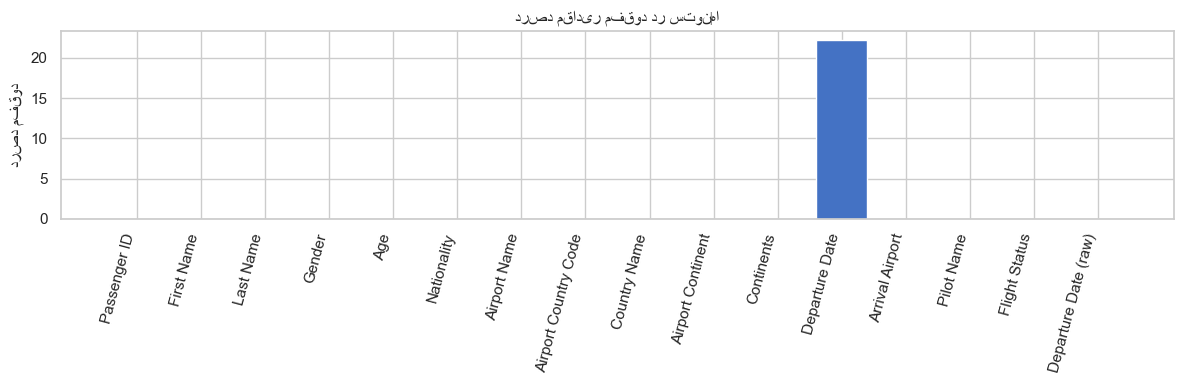

Percentages use the total number of records as denominator.
Unknown was not recoded as missing because it was not observed and its meaning was not documented.


In [35]:
missing_tokens = {"", "NA", "N/A", "NULL", "NaN"}
missing_table = []
for column in df.columns:
    series = df[column]
    missing = series.isna()
    if pd.api.types.is_string_dtype(series) or series.dtype == object:
        normalized = series.astype("string").str.strip()
        missing = missing | normalized.isin(missing_tokens)
    count = int(missing.sum())
    missing_table.append({"نام ستون": column, "تعداد مفقود": count, "درصد مفقود": round(100 * count / len(df), 3)})
missing_table = pd.DataFrame(missing_table)
display(missing_table)
plt.figure(figsize=(12, 4))
plt.bar(missing_table["نام ستون"], missing_table["درصد مفقود"], color="#4472C4")
plt.xticks(rotation=75, ha="right")
plt.ylabel("درصد مفقود")
plt.title("درصد مقادیر مفقود در ستون‌ها")
plt.tight_layout()
plt.show()
print("Percentages use the total number of records as denominator.")
print("Unknown was not recoded as missing because it was not observed and its meaning was not documented.")


**پاسخ ۶.۴:** جدول بالا `null`، `NaN`، رشتهٔ خالی، رشتهٔ فاصله‌ای و توکن‌های رایج مشخص‌شده را بررسی می‌کند و درصدها بر مبنای کل رکوردها هستند. نمودار، درصد واقعی هر ستون را نشان می‌دهد. از دادهٔ موجود به‌تنهایی برچسب MCAR، MAR یا MNAR نتیجه‌گیری نمی‌شود؛ هر الگوی مشاهده‌شده صرفاً توصیفی است.

### ۶.۵ اعتبارسنجی `Flight Status`

In [36]:
allowed_statuses = {"On Time", "Delayed", "Cancelled"}
status_before = df["Flight Status"].astype("string")
print("Initial unique values and frequencies:")
display(status_before.value_counts(dropna=False).rename("فراوانی").to_frame())
explicit_status_map = {
    "on time": "On Time", "on-time": "On Time", "ontime": "On Time",
    "delayed": "Delayed", "delay": "Delayed",
    "cancelled": "Cancelled", "canceled": "Cancelled", "cancelled ": "Cancelled"
}
def normalize_status(value):
    if pd.isna(value):
        return pd.NA
    text = str(value).strip()
    if text in allowed_statuses:
        return text
    return explicit_status_map.get(text.casefold(), text)
status_after = status_before.map(normalize_status)
initial_invalid = ~status_before.isin(allowed_statuses)
changed = status_after.ne(status_before) & status_after.notna()
unresolved = ~status_after.isin(allowed_statuses)
df["Flight Status"] = status_after
print(f"Initially invalid values: {int(initial_invalid.sum()):,}")
print(f"Explicitly corrected values: {int(changed.sum()):,}")
print(f"Unresolved values: {int(unresolved.sum()):,}")
if unresolved.any():
    display(status_after[unresolved].value_counts(dropna=False).rename("فراوانی").to_frame())
print(f"All final values are allowed: {bool(status_after.isin(allowed_statuses).all())}")


Initial unique values and frequencies:


,فراوانی
Flight Status,
Cancelled,32942
On Time,32846
Delayed,32831


Initially invalid values: 0
Explicitly corrected values: 0
Unresolved values: 0
All final values are allowed: True


### اعتبار اولیهٔ مقدارهای `Flight Status`

**بله**؛ همهٔ مقدارهای اولیه در مجموعهٔ مجاز `On Time`، `Delayed` و `Cancelled` قرار داشتند.

### تعداد موارد اصلاح‌شده

**۰** مورد اصلاح شد.

### مقادیر نامعتبر و روش یکسان‌سازی

مقدار نامعتبر مشاهده نشد؛ بنابراین تعداد موارد حل‌نشده نیز **۰** است و هیچ نگاشتی روی دادهٔ واقعی اعمال نشد. برای کنترل داده، نگاشت صریحی برای حذف فاصله‌های ابتدا و انتها، یکسان‌سازی حروف (`on time`، `delayed` و شکل‌های مشابه) و غلط املایی روشن (`canceled` به `Cancelled`) تعریف شد. مقدارهای ناشناخته به نزدیک‌ترین دسته تبدیل نمی‌شوند. پس از یکسان‌سازی، همهٔ مقدارهای باقی‌مانده در مجموعهٔ مجاز قرار دارند.

### ذخیرهٔ نسخهٔ پاک‌سازی‌شده و مستندسازی

In [37]:
# Preserve the raw file and write a separate cleaned copy.
documentation = pd.DataFrame([
    {"مسئله": "خرابی UTF-8 در Airport Name", "تعداد موارد": int(mojibake_mask.sum()), "تعداد اصلاح یا حذف‌شده": int(mojibake_mask.sum() - df[airport_col].astype("string").str.contains(mojibake_pattern, na=False).sum()), "روش اصلاح": "اصلاح فقط در صورت الگوی قابل تشخیص mojibake", "محدودیت": "در نبود الگو، تبدیل انجام نشد"},
    {"مسئله": "تاریخ Departure Date", "تعداد موارد": int((invalid_date_mask | ambiguous_date_mask | empty_date_mask).sum()), "تعداد اصلاح یا حذف‌شده": 0, "روش اصلاح": "پارسر صریح و حفظ ستون خام؛ مقدار نامعتبر مفقود می‌ماند", "محدودیت": "تاریخ مبهم بدون شواهد اضافی تعیین نشد"},
    {"مسئله": "Passenger ID", "تعداد موارد": int(invalid_id_mask.sum()), "تعداد اصلاح یا حذف‌شده": 0, "روش اصلاح": "اعتبارسنجی Regex و عدم حذف تکرار", "محدودیت": "شناسهٔ پرواز برای بررسی تکرار در سطح پرواز وجود ندارد"},
    {"مسئله": "مقادیر گمشده", "تعداد موارد": int(missing_table["تعداد مفقود"].sum()), "تعداد اصلاح یا حذف‌شده": 0, "روش اصلاح": "گزارش توصیفی و عدم جایگزینی حدسی", "محدودیت": "مکانیزم آماری گمشدگی تعیین نشد"},
    {"مسئله": "Flight Status", "تعداد موارد": int(initial_invalid.sum()), "تعداد اصلاح یا حذف‌شده": int(changed.sum()), "روش اصلاح": "نگاشت صریح فاصله، حروف و غلط روشن", "محدودیت": "مقدار ناشناخته به دستهٔ دیگر تبدیل نشد"}
])
display(documentation)
df.to_csv(CLEAN_PATH, index=False, encoding="utf-8")
print(f"Cleaned file saved: {CLEAN_PATH}")
print(f"Rows before: {row_count_before:,} | after: {len(df):,} | change: {len(df)-row_count_before:,}")
print(f"Raw file still exists: {RAW_PATH.exists()}")

,مسئله,تعداد موارد,تعداد اصلاح یا حذف‌شده,روش اصلاح,محدودیت
0,خرابی UTF-8 در Airport Name,0,0,اصلاح فقط در صورت الگوی قابل تشخیص mojibake,در نبود الگو، تبدیل انجام نشد
1,تاریخ Departure Date,21928,0,پارسر صریح و حفظ ستون خام؛ مقدار نامعتبر مفقود می‌ماند,تاریخ مبهم بدون شواهد اضافی تعیین نشد
2,Passenger ID,0,0,اعتبارسنجی Regex و عدم حذف تکرار,شناسهٔ پرواز برای بررسی تکرار در سطح پرواز وجود ندارد
3,مقادیر گمشده,21928,0,گزارش توصیفی و عدم جایگزینی حدسی,مکانیزم آماری گمشدگی تعیین نشد
4,Flight Status,0,0,نگاشت صریح فاصله، حروف و غلط روشن,مقدار ناشناخته به دستهٔ دیگر تبدیل نشد


Cleaned file saved: F:\GitHubFiles\Agentic-AI-practice\DataMining\data\airline_cleaned.csv
Rows before: 98,619 | after: 98,619 | change: 0
Raw file still exists: True


### جمع‌بندی بخش ۶

نسخهٔ پاک‌سازی‌شده فقط اصلاح‌هایی را نگه می‌دارد که قاعدهٔ قابل دفاع داشتند: تبدیل شرطی خرابی متن، استانداردسازی صریح تاریخ با حفظ مقدار خام، اعتبارسنجی شناسه بدون حذف خودکار و نگاشت روشن وضعیت پرواز. مقدارهای ناشناخته یا مبهم به‌صورت حدسی به دستهٔ دیگر تبدیل نشده‌اند و تعداد ردیف‌ها نباید در نتیجهٔ این عملیات تغییر کند.

### ۶.۶ گروه‌بندی سن و هموارسازی با Binning

این تحلیل فقط از دادهٔ پاک‌سازی‌شدهٔ `airline_cleaned.csv` استفاده می‌کند. مقادیر سن مفقود، منفی یا خارج از بازهٔ معقول پیش از گروه‌بندی کنار گذاشته می‌شوند و در هیچ گروهی قرار نمی‌گیرند.

تعداد رکوردها: 98,619
سن معتبر برای گروه‌بندی: 98,619
سن مفقود یا نامعتبر: 0
تعداد و بازه‌های گروه‌های سنی ثابت:


,تعداد رکورد
Age,
کودک,18547
جوان,19704
بزرگسال,21992
سالمند,22061
کهنسال,16315


تعداد و مرزهای واقعی Binning با فراوانی تقریباً مساوی:


,کف بازه,سقف بازه,تعداد رکورد
0,1.0,23.0,25078
1,23.0,46.0,25309
2,46.0,68.0,24267
3,68.0,90.0,23965


| روش گروه‌بندی         | روش هموارسازی   |   تعداد گروه‌ها | بازه‌ها                                                                               |   تعداد رکورد |   واریانس قبل |   واریانس بعد |   کاهش واریانس (%) |   میانگین قدرمطلق تغییر |   تعداد مقادیر یکتا بعد |
|:---------------------|:----------------|---------------:|:-------------------------------------------------------------------------------------|--------------:|--------------:|--------------:|-------------------:|------------------------:|------------------------:|
| مرزهای ثابت          | میانگین bin     |              5 | کودک: 0 تا 18؛ جوان: 18 تا 36؛ بزرگسال: 36 تا 56؛ سالمند: 56 تا 76؛ کهنسال: 76 تا 91 |         98619 |        672.35 |       644.633 |              4.122 |                   4.532 |                       5 |
| مرزهای ثابت          | میانه bin       |              5 | کودک: 0 تا 18؛ جوان: 18 تا 36؛ بزرگسال: 36 تا 56؛ سالمند: 56 تا 76؛ کهنسال: 76 تا 91 |         98619 |        672.35 |       644.279 |              4.175 |                   4.531 |                       5 |
| مرزهای ثابت          | نزدیک‌ترین کران  |              5 | کودک: 0 تا 18؛ جوان: 18 تا 36؛ بزرگسال: 36 تا 56؛ سالمند: 56 تا 76؛ کهنسال: 76 تا 91 |         98619 |        672.35 |       720.064 |             -7.097 |                   4.073 |                      10 |
| فراوانی تقریباً مساوی | میانگین bin     |              4 | [1, 23]؛ [23, 46]؛ [46, 68]؛ [68, 90]                                                |         98619 |        672.35 |       630.09  |              6.285 |                   5.631 |                       4 |
| فراوانی تقریباً مساوی | میانه bin       |              4 | [1, 23]؛ [23, 46]؛ [46, 68]؛ [68, 90]                                                |         98619 |        672.35 |       641.298 |              4.618 |                   5.629 |                       4 |
| فراوانی تقریباً مساوی | نزدیک‌ترین کران  |              4 | [1, 23]؛ [23, 46]؛ [46, 68]؛ [68, 90]                                                |         98619 |        672.35 |       735.098 |             -9.333 |                   5.492 |                       5 |

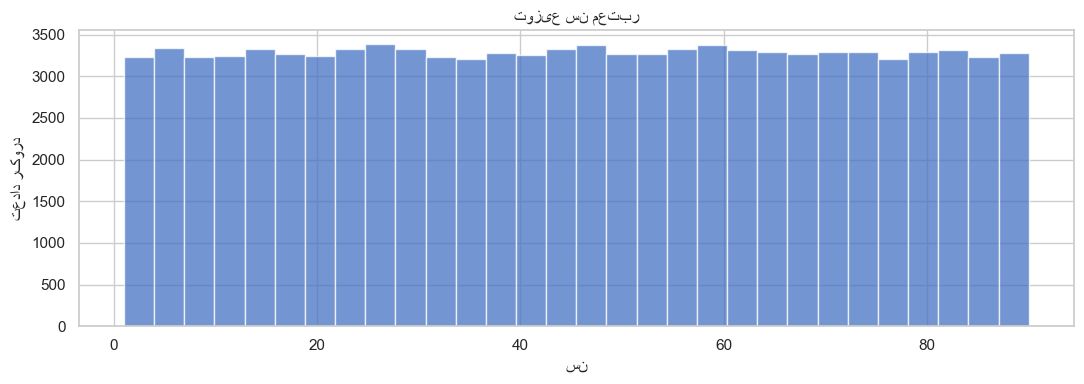

### پاسخ تحلیلی ۶.۶

در دادهٔ واقعی، 98,619 سن معتبر و 0 سن مفقود یا نامعتبر وجود داشت. گروه‌بندی مرزهای ثابت دقیقاً مرزهای مسئله را حفظ می‌کند و از نظر تفسیرپذیری مناسب‌تر است؛ در مقابل، Binning با فراوانی تقریباً مساوی تعداد رکوردهای گروه‌ها را متوازن‌تر می‌کند، اما مرزهای آن از توزیع واقعی داده به‌دست می‌آیند. در روش کران‌ها، برای گروه «کهنسال» کران بالا از بیشینهٔ مشاهده‌شده استفاده شد و کران ساختگی برای سن‌های بالاتر تعیین نشد؛ در تساوی فاصله، کران پایین انتخاب شد.

جدول Markdown بالا میانگین قدرمطلق تغییر، واریانس قبل و بعد و کاهش واریانس را گزارش می‌کند. جایگزینی با میانگین یا میانه معمولاً جزئیات درون bin را بیشتر فشرده می‌کند، در حالی که روش کران‌ها برخی مقادیر انتهایی را حفظ می‌کند. کاهش واریانس به‌تنهایی اثبات نمی‌کند که اطلاعات مفید توزیع حفظ شده‌اند؛ به همین دلیل تعداد مقادیر یکتا و تغییر مقدار هر رکورد نیز گزارش شده است.

In [38]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

airline_clean_path = Path.cwd() / "data" / "airline_cleaned.csv"
airline_clean = pd.read_csv(airline_clean_path)
age = pd.to_numeric(airline_clean["Age"], errors="coerce")
invalid_age = age.isna() | (age < 0) | (age > 120)
valid_age = age[~invalid_age].astype(float)
print(f"تعداد رکوردها: {len(airline_clean):,}")
print(f"سن معتبر برای گروه‌بندی: {len(valid_age):,}")
print(f"سن مفقود یا نامعتبر: {int(invalid_age.sum()):,}")

fixed_labels = ["کودک", "جوان", "بزرگسال", "سالمند", "کهنسال"]
fixed_edges = [0, 18, 36, 56, 76, np.inf]
fixed_bins = pd.cut(valid_age, bins=fixed_edges, labels=fixed_labels, right=False)

unique_age_count = valid_age.nunique()
q_group_count = min(4, unique_age_count)
q_bins, q_edges = pd.qcut(valid_age, q=q_group_count, retbins=True, duplicates="drop")
q_group_count = len(q_edges) - 1
q_bins = pd.cut(valid_age, bins=q_edges, include_lowest=True, duplicates="drop")

def range_text(edges, labels=None):
    if labels is not None:
        return "؛ ".join(f"{label}: {lo:g} تا {hi:g}" for label, lo, hi in zip(labels, edges[:-1], edges[1:]))
    return "؛ ".join(f"[{lo:g}, {hi:g}]" for lo, hi in zip(edges[:-1], edges[1:]))

def nearest_bound_smooth(values, bins):
    result = values.copy().astype(float)
    for key in bins.dropna().unique():
        mask = bins == key
        observed = values[mask]
        if hasattr(key, "left") and hasattr(key, "right"):
            low, high = float(key.left), float(key.right)
        else:
            low, high = float(observed.min()), float(observed.max())
        distances_low = (observed - low).abs()
        distances_high = (observed - high).abs()
        # On an exact tie, choose the lower boundary.
        result.loc[mask] = np.where(distances_low <= distances_high, low, high)
    return result

def make_smoothing_table(values, bins, bin_count, ranges):
    rows = []
    for method in ["میانگین bin", "میانه bin", "نزدیک‌ترین کران"]:
        smoothed = values.copy().astype(float)
        if method == "میانگین bin":
            replacements = values.groupby(bins, observed=True).transform("mean")
            smoothed = replacements.astype(float)
        elif method == "میانه bin":
            replacements = values.groupby(bins, observed=True).transform("median")
            smoothed = replacements.astype(float)
        else:
            smoothed = nearest_bound_smooth(values, bins)
        before_var = float(values.var(ddof=0))
        after_var = float(smoothed.var(ddof=0))
        rows.append({
            "روش گروه‌بندی": group_name,
            "روش هموارسازی": method,
            "تعداد گروه‌ها": bin_count,
            "بازه‌ها": ranges,
            "تعداد رکورد": len(values),
            "واریانس قبل": round(before_var, 3),
            "واریانس بعد": round(after_var, 3),
            "کاهش واریانس (%)": round(100 * (before_var - after_var) / before_var, 3),
            "میانگین قدرمطلق تغییر": round(float((smoothed - values).abs().mean()), 3),
            "تعداد مقادیر یکتا بعد": int(smoothed.nunique()),
        })
    return rows

fixed_range = range_text([0, 18, 36, 56, 76, int(valid_age[valid_age >= 76].max()) + 1], fixed_labels)
q_range = range_text(q_edges)
fixed_counts = fixed_bins.value_counts(sort=False).rename("تعداد رکورد").to_frame()
q_counts = q_bins.value_counts(sort=False).rename("تعداد رکورد").to_frame()
print("تعداد و بازه‌های گروه‌های سنی ثابت:")
display(fixed_counts)
print("تعداد و مرزهای واقعی Binning با فراوانی تقریباً مساوی:")
display(pd.DataFrame({"کف بازه": q_edges[:-1], "سقف بازه": q_edges[1:], "تعداد رکورد": q_counts["تعداد رکورد"].to_numpy()}))

all_rows = []
for group_name, bins, count, ranges in [
    ("مرزهای ثابت", fixed_bins, len(fixed_labels), fixed_range),
    ("فراوانی تقریباً مساوی", q_bins, q_group_count, q_range),
]:
    all_rows.extend(make_smoothing_table(valid_age, bins, count, ranges))
smoothing_table = pd.DataFrame(all_rows)
display(Markdown(smoothing_table.to_markdown(index=False)))

plt.figure(figsize=(11, 4))
plt.hist(valid_age, bins=30, alpha=0.75, color="#4472C4", edgecolor="white")
plt.xlabel("سن")
plt.ylabel("تعداد رکورد")
plt.title("توزیع سن معتبر")
plt.tight_layout()
plt.show()

fixed_best = smoothing_table[smoothing_table["روش گروه‌بندی"] == "مرزهای ثابت"]
q_best = smoothing_table[smoothing_table["روش گروه‌بندی"] == "فراوانی تقریباً مساوی"]
display(Markdown(
    f"""### پاسخ تحلیلی ۶.۶

در دادهٔ واقعی، {len(valid_age):,} سن معتبر و {int(invalid_age.sum()):,} سن مفقود یا نامعتبر وجود داشت. گروه‌بندی مرزهای ثابت دقیقاً مرزهای مسئله را حفظ می‌کند و از نظر تفسیرپذیری مناسب‌تر است؛ در مقابل، Binning با فراوانی تقریباً مساوی تعداد رکوردهای گروه‌ها را متوازن‌تر می‌کند، اما مرزهای آن از توزیع واقعی داده به‌دست می‌آیند. در روش کران‌ها، برای گروه «کهنسال» کران بالا از بیشینهٔ مشاهده‌شده استفاده شد و کران ساختگی برای سن‌های بالاتر تعیین نشد؛ در تساوی فاصله، کران پایین انتخاب شد.

جدول Markdown بالا میانگین قدرمطلق تغییر، واریانس قبل و بعد و کاهش واریانس را گزارش می‌کند. جایگزینی با میانگین یا میانه معمولاً جزئیات درون bin را بیشتر فشرده می‌کند، در حالی که روش کران‌ها برخی مقادیر انتهایی را حفظ می‌کند. کاهش واریانس به‌تنهایی اثبات نمی‌کند که اطلاعات مفید توزیع حفظ شده‌اند؛ به همین دلیل تعداد مقادیر یکتا و تغییر مقدار هر رکورد نیز گزارش شده است."""
))


### ۶.۷ استخراج سری زمانی پروازها و هموارسازی

تاریخ معتبر در مقیاس هفتگی با هفتهٔ آغازشونده از دوشنبه و در مقیاس ماهانه با ماه تقویمی تجمیع می‌شود. میانگین متحرک با پنجره‌های ۳، ۵ و ۷ و هموارسازی نمایی با `alpha=0.3` محاسبه می‌شوند.

تاریخ معتبر: 76,691
تاریخ نامعتبر یا مفقود: 21,928
هفته‌های دارای داده: 49؛ هفته‌های صفر در بازهٔ معتبر: 2
ماه‌های دارای داده: 12؛ ماه‌های صفر در بازهٔ معتبر: 0
دوره‌های خارج از بازهٔ حداقل تا حداکثر تاریخ معتبر، دادهٔ قابل ارزیابی ندارند و با صفر اشتباه گرفته نمی‌شوند.


#### جدول سری هفتگی

|                     |   تعداد پرواز |   میانگین متحرک 3 |   میانگین متحرک 5 |   میانگین متحرک 7 |   هموارسازی نمایی alpha=0.3 |
|:--------------------|--------------:|------------------:|------------------:|------------------:|----------------------------:|
| 2022-01-10 00:00:00 |          1967 |           1967    |           1967    |           1967    |                     1967    |
| 2022-01-17 00:00:00 |          1944 |           1955.5  |           1955.5  |           1955.5  |                     1960.1  |
| 2022-01-24 00:00:00 |          1867 |           1926    |           1926    |           1926    |                     1932.17 |
| 2022-01-31 00:00:00 |           261 |           1357.33 |           1509.75 |           1509.75 |                     1430.82 |
| 2022-02-07 00:00:00 |          1132 |           1086.67 |           1434.2  |           1434.2  |                     1341.17 |
| 2022-02-14 00:00:00 |          1969 |           1120.67 |           1434.6  |           1523.33 |                     1529.52 |
| 2022-02-21 00:00:00 |          1893 |           1664.67 |           1424.4  |           1576.14 |                     1638.56 |
| 2022-02-28 00:00:00 |           263 |           1375    |           1103.6  |           1332.71 |                     1225.9  |
| 2022-03-07 00:00:00 |          1107 |           1087.67 |           1272.8  |           1213.14 |                     1190.23 |
| 2022-03-14 00:00:00 |          1966 |           1112    |           1439.6  |           1227.29 |                     1422.96 |
| 2022-03-21 00:00:00 |          1887 |           1653.33 |           1423.2  |           1459.57 |                     1562.17 |
| 2022-03-28 00:00:00 |          1062 |           1638.33 |           1257    |           1449.57 |                     1412.12 |

#### جدول سری ماهانه

|                     |   تعداد پرواز |   میانگین متحرک 3 |   میانگین متحرک 5 |   میانگین متحرک 7 |   هموارسازی نمایی alpha=0.3 |
|:--------------------|--------------:|------------------:|------------------:|------------------:|----------------------------:|
| 2022-01-01 00:00:00 |          6039 |           6039    |           6039    |           6039    |                     6039    |
| 2022-02-01 00:00:00 |          5257 |           5648    |           5648    |           5648    |                     5804.4  |
| 2022-03-01 00:00:00 |          6022 |           5772.67 |           5772.67 |           5772.67 |                     5869.68 |
| 2022-04-01 00:00:00 |          5521 |           5600    |           5709.75 |           5709.75 |                     5765.08 |
| 2022-05-01 00:00:00 |          5996 |           5846.33 |           5767    |           5767    |                     5834.35 |
| 2022-06-01 00:00:00 |          5719 |           5745.33 |           5703    |           5759    |                     5799.75 |
| 2022-07-01 00:00:00 |          5976 |           5897    |           5846.8  |           5790    |                     5852.62 |
| 2022-08-01 00:00:00 |          6057 |           5917.33 |           5853.8  |           5792.57 |                     5913.94 |
| 2022-09-01 00:00:00 |          5712 |           5915    |           5892    |           5857.57 |                     5853.36 |
| 2022-10-01 00:00:00 |          8415 |           6728    |           6375.8  |           6199.43 |                     6621.85 |
| 2022-11-01 00:00:00 |          8053 |           7393.33 |           6842.6  |           6561.14 |                     7051.19 |
| 2022-12-01 00:00:00 |          7924 |           8130.67 |           7232.2  |           6836.57 |                     7313.04 |

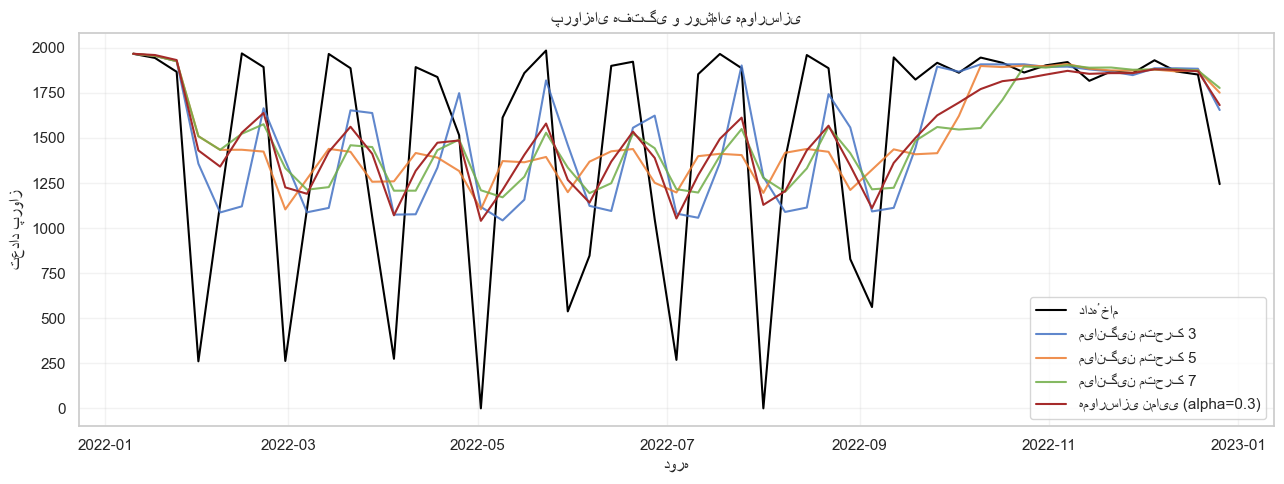

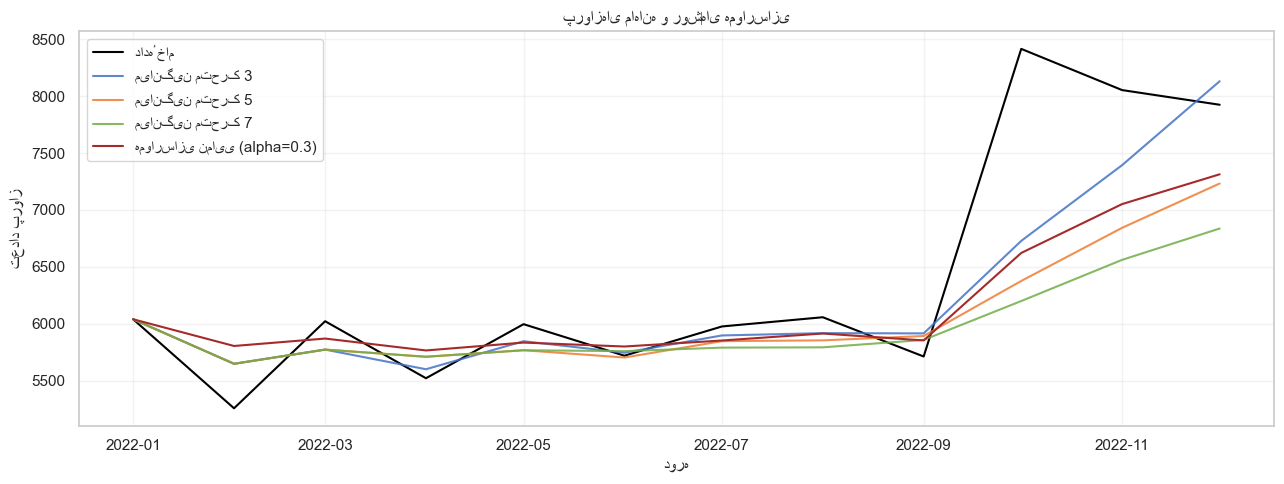

### پاسخ تحلیلی ۶.۷

از 76,691 تاریخ معتبر، سری هفتگی شامل 51 دوره و سری ماهانه شامل 12 دوره در بازهٔ مشاهده‌شده ساخته شد. پرترافیک‌ترین هفته از 2022-05-23 با 1,985 پرواز و کم‌ترافیک‌ترین هفته از 2022-05-02 با 0 پرواز بود. پرترافیک‌ترین ماه از 2022-10-01 با 8,415 پرواز و کم‌ترافیک‌ترین ماه از 2022-02-01 با 5,257 پرواز بود.

میانگین‌های متحرک ۳، ۵ و ۷ دوره نوسان‌های کوتاه‌مدت را به‌ترتیب با شدت بیشتری کاهش می‌دهند؛ در ابتدا و انتهای سری، به‌دلیل استفاده از `min_periods=1` تعداد مشاهدات پنجره کامل نیست و مقدار هموارشده باید با احتیاط تفسیر شود. هموارسازی نمایی با `alpha=0.3` وزن بیشتری به مشاهدات جدید می‌دهد و نسبت به میانگین متحرک واکنش تدریجی‌تری دارد. دوره‌های صفر فقط در فاصلهٔ بین اولین و آخرین تاریخ معتبر بررسی شده‌اند؛ دربارهٔ بیرون از این بازه نمی‌توان نبود پرواز را نتیجه گرفت. طول بازه و ماهیت مقطعی داده برای ادعای فصل‌مندی قطعی کافی نیست.

In [39]:
date_values = pd.to_datetime(airline_clean["Departure Date"], errors="coerce")
valid_date = date_values.notna()
print(f"تاریخ معتبر: {int(valid_date.sum()):,}")
print(f"تاریخ نامعتبر یا مفقود: {int((~valid_date).sum()):,}")

date_frame = pd.DataFrame({"date": date_values[valid_date]})
date_frame["count"] = 1
weekly = date_frame.set_index("date")["count"].resample("W-MON", label="left", closed="left").sum()
monthly = date_frame.set_index("date")["count"].resample("MS").sum()

def complete_periods(series, frequency):
    if series.empty:
        return series
    full_index = pd.date_range(series.index.min(), series.index.max(), freq=frequency)
    return series.reindex(full_index, fill_value=0).astype(int)

weekly = complete_periods(weekly, "W-MON")
monthly = complete_periods(monthly, "MS")
print(f"هفته‌های دارای داده: {int((weekly > 0).sum())}؛ هفته‌های صفر در بازهٔ معتبر: {int((weekly == 0).sum())}")
print(f"ماه‌های دارای داده: {int((monthly > 0).sum())}؛ ماه‌های صفر در بازهٔ معتبر: {int((monthly == 0).sum())}")
print("دوره‌های خارج از بازهٔ حداقل تا حداکثر تاریخ معتبر، دادهٔ قابل ارزیابی ندارند و با صفر اشتباه گرفته نمی‌شوند.")

alpha = 0.3
def smooth_series(series):
    result = pd.DataFrame({"تعداد پرواز": series})
    for window in [3, 5, 7]:
        result[f"میانگین متحرک {window}"] = series.rolling(window=window, min_periods=1).mean()
    result["هموارسازی نمایی alpha=0.3"] = series.ewm(alpha=alpha, adjust=False).mean()
    return result

weekly_smooth = smooth_series(weekly)
monthly_smooth = smooth_series(monthly)
display(Markdown("#### جدول سری هفتگی\n\n" + weekly_smooth.head(12).round(2).to_markdown()))
display(Markdown("#### جدول سری ماهانه\n\n" + monthly_smooth.to_markdown()))

def plot_series(result, title):
    plt.figure(figsize=(13, 5))
    plt.plot(result.index, result["تعداد پرواز"], label="دادهٔ خام", linewidth=1.5, color="black")
    for window, color in [(3, "#4472C4"), (5, "#ED7D31"), (7, "#70AD47")]:
        plt.plot(result.index, result[f"میانگین متحرک {window}"], label=f"میانگین متحرک {window}", alpha=0.85, color=color)
    plt.plot(result.index, result["هموارسازی نمایی alpha=0.3"], label="هموارسازی نمایی (alpha=0.3)", color="#A52A2A")
    plt.title(title)
    plt.xlabel("دوره")
    plt.ylabel("تعداد پرواز")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

plot_series(weekly_smooth, "پروازهای هفتگی و روش‌های هموارسازی")
plot_series(monthly_smooth, "پروازهای ماهانه و روش‌های هموارسازی")

def peak_low(series):
    return series.idxmax().strftime("%Y-%m-%d"), int(series.max()), series.idxmin().strftime("%Y-%m-%d"), int(series.min())

week_peak, week_peak_value, week_low, week_low_value = peak_low(weekly)
month_peak, month_peak_value, month_low, month_low_value = peak_low(monthly)
display(Markdown(
    f"""### پاسخ تحلیلی ۶.۷

از {int(valid_date.sum()):,} تاریخ معتبر، سری هفتگی شامل {len(weekly):,} دوره و سری ماهانه شامل {len(monthly):,} دوره در بازهٔ مشاهده‌شده ساخته شد. پرترافیک‌ترین هفته از {week_peak} با {week_peak_value:,} پرواز و کم‌ترافیک‌ترین هفته از {week_low} با {week_low_value:,} پرواز بود. پرترافیک‌ترین ماه از {month_peak} با {month_peak_value:,} پرواز و کم‌ترافیک‌ترین ماه از {month_low} با {month_low_value:,} پرواز بود.

میانگین‌های متحرک ۳، ۵ و ۷ دوره نوسان‌های کوتاه‌مدت را به‌ترتیب با شدت بیشتری کاهش می‌دهند؛ در ابتدا و انتهای سری، به‌دلیل استفاده از `min_periods=1` تعداد مشاهدات پنجره کامل نیست و مقدار هموارشده باید با احتیاط تفسیر شود. هموارسازی نمایی با `alpha=0.3` وزن بیشتری به مشاهدات جدید می‌دهد و نسبت به میانگین متحرک واکنش تدریجی‌تری دارد. دوره‌های صفر فقط در فاصلهٔ بین اولین و آخرین تاریخ معتبر بررسی شده‌اند؛ دربارهٔ بیرون از این بازه نمی‌توان نبود پرواز را نتیجه گرفت. طول بازه و ماهیت مقطعی داده برای ادعای فصل‌مندی قطعی کافی نیست."""
))


### ۶.۸ بررسی سن، ملیت و وضعیت پرواز با هیت‌مپ

این تحلیل از دادهٔ پاک‌سازی‌شدهٔ `airline_cleaned.csv` استفاده می‌کند. گروه‌های سنی همان مرزهای ثابت سؤال ۶.۶ هستند و سن نامعتبر یا مفقود در هیچ گروهی قرار نمی‌گیرد.

ستون‌های استفاده‌شده: ['Age', 'Nationality', 'Flight Status']
سن معتبر: 98,619؛ سن مفقود یا نامعتبر: 0
ملیت‌های یکتا: 240
وضعیت‌های پرواز: ['Cancelled', 'Delayed', 'On Time']


برای خوانایی، 15 ملیت پرتکرار نمایش داده شد و **33,015 رکورد از 240 ملیت** در گروه «سایر» ادغام شد.

#### جدول توافقی تعداد مسافران

| row_0   |   China |   Indonesia |   Russia |   Philippines |   Brazil |   Portugal |   Poland |   France |   Sweden |   United States |   Japan |   Czech Republic |   Ukraine |   Peru |   Thailand |   سایر |
|:--------|--------:|------------:|---------:|--------------:|---------:|-----------:|---------:|---------:|---------:|----------------:|--------:|-----------------:|----------:|-------:|-----------:|-------:|
| کودک    |    3489 |        1995 |     1093 |           954 |      723 |        597 |      600 |      542 |      464 |             382 |     317 |              357 |       261 |    302 |        260 |   6211 |
| جوان    |    3715 |        2111 |     1117 |          1009 |      760 |        650 |      625 |      587 |      511 |             442 |     360 |              333 |       333 |    297 |        263 |   6591 |
| بزرگسال |    4021 |        2319 |     1247 |          1259 |      837 |        728 |      731 |      676 |      490 |             429 |     420 |              382 |       342 |    357 |        359 |   7395 |
| سالمند  |    4057 |        2429 |     1332 |          1159 |      848 |        767 |      714 |      619 |      555 |             492 |     432 |              344 |       354 |    303 |        312 |   7344 |
| کهنسال  |    3035 |        1705 |      904 |           858 |      623 |        557 |      575 |      483 |      377 |             360 |     276 |              274 |       301 |    281 |        232 |   5474 |

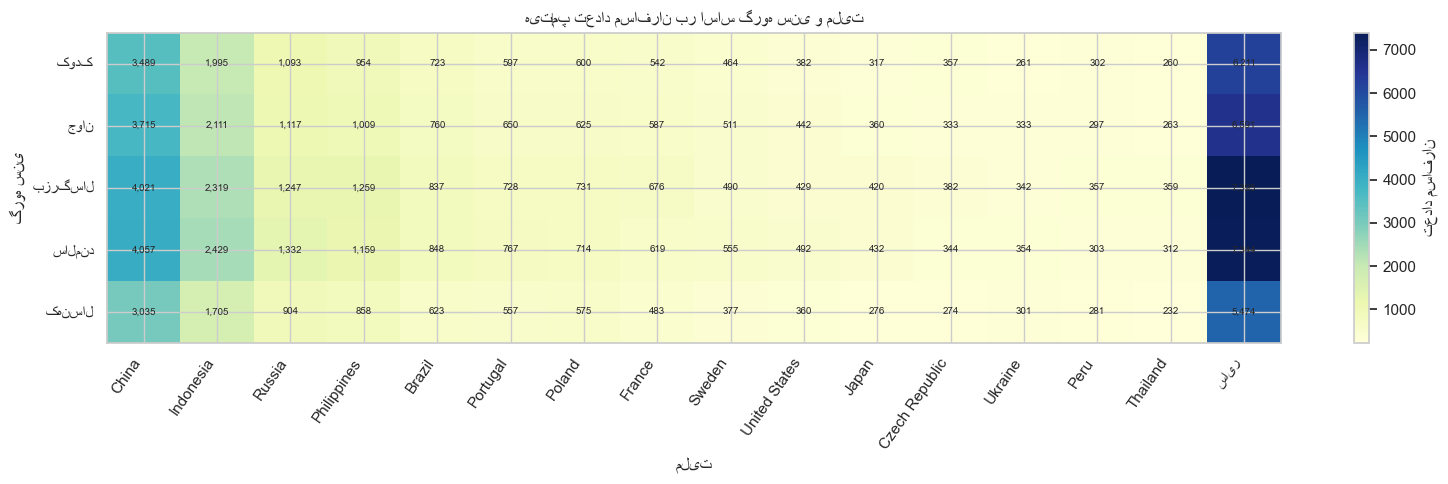

#### نسبت وضعیت‌های پرواز همراه با تعداد نمونه

نسبت‌ها بر اساس تعداد هر سلول محاسبه شده‌اند؛ سلول بدون رکورد با `—` به‌عنوان تعریف‌نشده نمایش داده می‌شود.

C:\Users\MOSALAS\AppData\Local\Temp\ipykernel_16180\1949581502.py:85: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  status_ratios_68[status].stack(dropna=False).rename(status).to_frame().join(
C:\Users\MOSALAS\AppData\Local\Temp\ipykernel_16180\1949581502.py:85: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  status_ratios_68[status].stack(dropna=False).rename(status).to_frame().join(
C:\Users\MOSALAS\AppData\Local\Temp\ipykernel_16180\1949581502.py:85: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See

| گروه سنی   | ملیت           |   تعداد نمونه |   نسبت On Time |   نسبت Delayed |   نسبت Cancelled |
|:-----------|:---------------|--------------:|---------------:|---------------:|-----------------:|
| کودک       | China          |          3489 |         0.3302 |         0.3319 |           0.3379 |
| کودک       | Indonesia      |          1995 |         0.3363 |         0.3373 |           0.3263 |
| کودک       | Russia         |          1093 |         0.3321 |         0.3211 |           0.3468 |
| کودک       | Philippines    |           954 |         0.3574 |         0.3323 |           0.3103 |
| کودک       | Brazil         |           723 |         0.3292 |         0.343  |           0.3278 |
| کودک       | Portugal       |           597 |         0.3099 |         0.3518 |           0.3384 |
| کودک       | Poland         |           600 |         0.3467 |         0.3067 |           0.3467 |
| کودک       | France         |           542 |         0.3173 |         0.369  |           0.3137 |
| کودک       | Sweden         |           464 |         0.2953 |         0.3599 |           0.3448 |
| کودک       | United States  |           382 |         0.377  |         0.288  |           0.3351 |
| کودک       | Japan          |           317 |         0.3312 |         0.3344 |           0.3344 |
| کودک       | Czech Republic |           357 |         0.3585 |         0.3025 |           0.3389 |
| کودک       | Ukraine        |           261 |         0.3142 |         0.3142 |           0.3716 |
| کودک       | Peru           |           302 |         0.3046 |         0.3907 |           0.3046 |
| کودک       | Thailand       |           260 |         0.3385 |         0.3192 |           0.3423 |
| کودک       | سایر           |          6211 |         0.3354 |         0.3325 |           0.3322 |
| جوان       | China          |          3715 |         0.3421 |         0.3203 |           0.3376 |
| جوان       | Indonesia      |          2111 |         0.3354 |         0.3321 |           0.3325 |
| جوان       | Russia         |          1117 |         0.3259 |         0.3286 |           0.3456 |
| جوان       | Philippines    |          1009 |         0.332  |         0.332  |           0.336  |
| جوان       | Brazil         |           760 |         0.3421 |         0.3368 |           0.3211 |
| جوان       | Portugal       |           650 |         0.3415 |         0.32   |           0.3385 |
| جوان       | Poland         |           625 |         0.3104 |         0.3152 |           0.3744 |
| جوان       | France         |           587 |         0.3492 |         0.3152 |           0.3356 |
| جوان       | Sweden         |           511 |         0.3444 |         0.3601 |           0.2955 |
| جوان       | United States  |           442 |         0.3258 |         0.2896 |           0.3846 |
| جوان       | Japan          |           360 |         0.3472 |         0.325  |           0.3278 |
| جوان       | Czech Republic |           333 |         0.3123 |         0.3453 |           0.3423 |
| جوان       | Ukraine        |           333 |         0.3303 |         0.3333 |           0.3363 |
| جوان       | Peru           |           297 |         0.3165 |         0.3603 |           0.3232 |
| جوان       | Thailand       |           263 |         0.3384 |         0.3346 |           0.327  |
| جوان       | سایر           |          6591 |         0.3274 |         0.3347 |           0.3379 |
| بزرگسال    | China          |          4021 |         0.3385 |         0.3288 |           0.3328 |
| بزرگسال    | Indonesia      |          2319 |         0.3329 |         0.3385 |           0.3286 |
| بزرگسال    | Russia         |          1247 |         0.3416 |         0.3272 |           0.3312 |
| بزرگسال    | Philippines    |          1259 |         0.3479 |         0.3145 |           0.3376 |
| بزرگسال    | Brazil         |           837 |         0.3548 |         0.3166 |           0.3286 |
| بزرگسال    | Portugal       |           728 |         0.342  |         0.3132 |           0.3448 |
| بزرگسال    | Poland         |           731 |         0.3133 |         0.3406 |           0.3461 |
| بزرگسال    | France         |           676 |         0.324  |         0.3358 |           0.3402 |
| بزرگسال    | Sweden         |           490 |         0.3551 |         0.3265 |           0.3184 |
| بزرگسال    | United States  |           429 |         0.3217 |         0.3497 |           0.3287 |
| بزرگسال    | Japan          |           420 |         0.3262 |         0.3119 |           0.3619 |
| بزرگسال    | Czech Republic |           382 |         0.3194 |         0.3377 |           0.3429 |
| بزرگسال    | Ukraine        |           342 |         0.3567 |         0.3275 |           0.3158 |
| بزرگسال    | Peru           |           357 |         0.3473 |         0.3193 |           0.3333 |
| بزرگسال    | Thailand       |           359 |         0.312  |         0.3482 |           0.3398 |
| بزرگسال    | سایر           |          7395 |         0.3286 |         0.3402 |           0.3312 |
| سالمند     | China          |          4057 |         0.3323 |         0.3293 |           0.3384 |
| سالمند     | Indonesia      |          2429 |         0.3318 |         0.3298 |           0.3384 |
| سالمند     | Russia         |          1332 |         0.3393 |         0.3356 |           0.3251 |
| سالمند     | Philippines    |          1159 |         0.3244 |         0.327  |           0.3486 |
| سالمند     | Brazil         |           848 |         0.3196 |         0.3573 |           0.3231 |
| سالمند     | Portugal       |           767 |         0.3025 |         0.3481 |           0.3494 |
| سالمند     | Poland         |           714 |         0.3529 |         0.3361 |           0.3109 |
| سالمند     | France         |           619 |         0.3166 |         0.3409 |           0.3425 |
| سالمند     | Sweden         |           555 |         0.3604 |         0.3243 |           0.3153 |
| سالمند     | United States  |           492 |         0.3211 |         0.3394 |           0.3394 |
| سالمند     | Japan          |           432 |         0.3194 |         0.3866 |           0.294  |
| سالمند     | Czech Republic |           344 |         0.3081 |         0.3692 |           0.3227 |
| سالمند     | Ukraine        |           354 |         0.3531 |         0.3503 |           0.2966 |
| سالمند     | Peru           |           303 |         0.3597 |         0.3003 |           0.3399 |
| سالمند     | Thailand       |           312 |         0.3494 |         0.3622 |           0.2885 |
| سالمند     | سایر           |          7344 |         0.3348 |         0.3306 |           0.3346 |
| کهنسال     | China          |          3035 |         0.3295 |         0.345  |           0.3255 |
| کهنسال     | Indonesia      |          1705 |         0.3261 |         0.3308 |           0.3431 |
| کهنسال     | Russia         |           904 |         0.3606 |         0.3142 |           0.3252 |
| کهنسال     | Philippines    |           858 |         0.324  |         0.3392 |           0.3368 |
| کهنسال     | Brazil         |           623 |         0.3387 |         0.321  |           0.3403 |
| کهنسال     | Portugal       |           557 |         0.3465 |         0.3268 |           0.3268 |
| کهنسال     | Poland         |           575 |         0.3461 |         0.3252 |           0.3287 |
| کهنسال     | France         |           483 |         0.3106 |         0.383  |           0.3064 |
| کهنسال     | Sweden         |           377 |         0.3342 |         0.305  |           0.3607 |
| کهنسال     | United States  |           360 |         0.3111 |         0.3472 |           0.3417 |
| کهنسال     | Japan          |           276 |         0.3297 |         0.3333 |           0.337  |
| کهنسال     | Czech Republic |           274 |         0.3139 |         0.3796 |           0.3066 |
| کهنسال     | Ukraine        |           301 |         0.3223 |         0.3289 |           0.3488 |
| کهنسال     | Peru           |           281 |         0.3132 |         0.3274 |           0.3594 |
| کهنسال     | Thailand       |           232 |         0.319  |         0.3664 |           0.3147 |
| کهنسال     | سایر           |          5474 |         0.3332 |         0.3299 |           0.3369 |

C:\Users\MOSALAS\AppData\Local\Temp\ipykernel_16180\1949581502.py:119: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


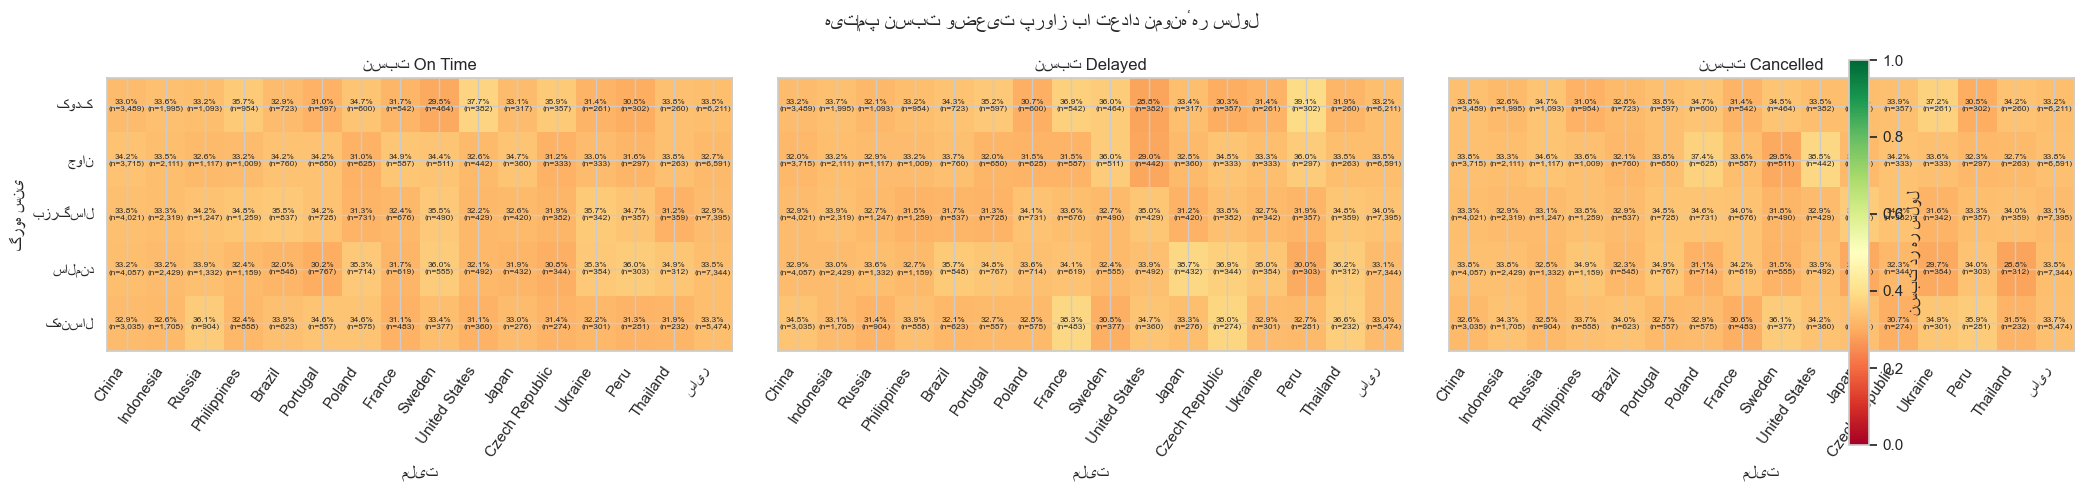

### پاسخ تحلیلی ۶.۸

در تحلیل 98,619 رکورد با سن معتبر استفاده شد و 0 رکورد سن نامعتبر یا مفقود از گروه‌بندی حذف شد. پرتعدادترین ترکیب گروه سنی و ملیتِ نمایش‌داده‌شده «بزرگسال / سایر» با 7,395 مسافر بود. انتخاب «سایر» فقط برای خوانایی نمودار انجام شد و شامل 33,015 رکورد از ملیت‌های کم‌تکرار است.

الگوهای نسبت وضعیت پرواز در هیت‌مپ دوم به شکل زیر مشاهده شد:
- `On Time`: کمترین نسبت 29.5% در ترکیب «کودک / Sweden» و بیشترین نسبت 37.7% در ترکیب «کودک / United States».
- `Delayed`: کمترین نسبت 28.8% در ترکیب «کودک / United States» و بیشترین نسبت 39.1% در ترکیب «کودک / Peru».
- `Cancelled`: کمترین نسبت 28.8% در ترکیب «سالمند / Thailand» و بیشترین نسبت 38.5% در ترکیب «جوان / United States».

این نسبت‌ها باید همراه با تعداد نمونهٔ `n` تفسیر شوند؛ نسبت بزرگ در سلول کم‌نمونه می‌تواند ناپایدار باشد. سلول‌های بدون رکورد نسبت ساختگی ندارند و با `—` نمایش داده شده‌اند. این نتایج توصیفی‌اند و تفاوت مشاهده‌شده میان سن، ملیت و وضعیت پرواز به‌تنهایی رابطهٔ علّی را ثابت نمی‌کند.

In [40]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

airline_68_path = Path.cwd() / "data" / "airline_cleaned.csv"
airline_68 = pd.read_csv(airline_68_path)

age_68 = pd.to_numeric(airline_68["Age"], errors="coerce")
age_valid_68 = age_68.notna() & age_68.between(0, 120)
age_labels_68 = ["کودک", "جوان", "بزرگسال", "سالمند", "کهنسال"]
age_edges_68 = [0, 18, 36, 56, 76, np.inf]
age_group_68 = pd.cut(
    age_68.where(age_valid_68),
    bins=age_edges_68,
    labels=age_labels_68,
    right=False,
)

required_columns_68 = ["Age", "Nationality", "Flight Status"]
print("ستون‌های استفاده‌شده:", required_columns_68)
print(f"سن معتبر: {int(age_valid_68.sum()):,}؛ سن مفقود یا نامعتبر: {int((~age_valid_68).sum()):,}")
print(f"ملیت‌های یکتا: {airline_68['Nationality'].nunique(dropna=True):,}")
print("وضعیت‌های پرواز:", sorted(airline_68["Flight Status"].dropna().unique().tolist()))

analysis_68 = airline_68.loc[age_valid_68, ["Nationality", "Flight Status"]].copy()
analysis_68["گروه سنی"] = age_group_68.loc[age_valid_68].astype(str).values
status_allowed_68 = ["On Time", "Delayed", "Cancelled"]
analysis_68["Flight Status"] = pd.Categorical(
    analysis_68["Flight Status"],
    categories=status_allowed_68,
)

top_n_68 = 15
nationality_counts_68 = analysis_68["Nationality"].value_counts()
top_nationalities_68 = nationality_counts_68.head(top_n_68).index
analysis_68["ملیت نمایش"] = analysis_68["Nationality"].where(
    analysis_68["Nationality"].isin(top_nationalities_68),
    "سایر",
)
merged_nationality_count_68 = int((~analysis_68["Nationality"].isin(top_nationalities_68)).sum())
display(Markdown(
    f"برای خوانایی، {top_n_68} ملیت پرتکرار نمایش داده شد و **{merged_nationality_count_68:,} رکورد از {len(nationality_counts_68):,} ملیت** در گروه «سایر» ادغام شد."
))

age_order_68 = age_labels_68
nationality_order_68 = list(top_nationalities_68) + ["سایر"]
count_table_68 = pd.crosstab(
    pd.Categorical(analysis_68["گروه سنی"], categories=age_order_68, ordered=True),
    pd.Categorical(analysis_68["ملیت نمایش"], categories=nationality_order_68, ordered=True),
).reindex(index=age_order_68, columns=nationality_order_68, fill_value=0)
display(Markdown("#### جدول توافقی تعداد مسافران\n\n" + count_table_68.to_markdown()))

fig, ax = plt.subplots(figsize=(16, 5))
image = ax.imshow(count_table_68.to_numpy(), cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(len(count_table_68.columns)), count_table_68.columns, rotation=55, ha="right")
ax.set_yticks(range(len(count_table_68.index)), count_table_68.index)
ax.set_xlabel("ملیت")
ax.set_ylabel("گروه سنی")
ax.set_title("هیت‌مپ تعداد مسافران بر اساس گروه سنی و ملیت")
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("تعداد مسافران")
for row in range(count_table_68.shape[0]):
    for col in range(count_table_68.shape[1]):
        ax.text(col, row, f"{int(count_table_68.iloc[row, col]):,}", ha="center", va="center", fontsize=7)
plt.tight_layout()
plt.show()

status_counts_68 = {}
status_ratios_68 = {}
for status in status_allowed_68:
    status_counts_68[status] = pd.crosstab(
        pd.Categorical(analysis_68["گروه سنی"], categories=age_order_68, ordered=True),
        pd.Categorical(analysis_68["ملیت نمایش"], categories=nationality_order_68, ordered=True),
        values=(analysis_68["Flight Status"] == status).astype(int),
        aggfunc="sum",
    ).reindex(index=age_order_68, columns=nationality_order_68, fill_value=0)
    status_ratios_68[status] = status_counts_68[status].div(count_table_68).where(count_table_68.ne(0))

display(Markdown("#### نسبت وضعیت‌های پرواز همراه با تعداد نمونه\n\nنسبت‌ها بر اساس تعداد هر سلول محاسبه شده‌اند؛ سلول بدون رکورد با `—` به‌عنوان تعریف‌نشده نمایش داده می‌شود."))
ratio_rows_68 = []
for status in status_allowed_68:
    ratio_rows_68.append(
        status_ratios_68[status].stack(dropna=False).rename(status).to_frame().join(
            count_table_68.stack().rename("تعداد نمونه")
        )
    )
ratio_table_68 = pd.concat(ratio_rows_68, axis=1)
ratio_display_68 = []
for age_label in age_order_68:
    for nationality in nationality_order_68:
        sample_count = int(count_table_68.loc[age_label, nationality])
        row = {"گروه سنی": age_label, "ملیت": nationality, "تعداد نمونه": sample_count}
        for status in status_allowed_68:
            value = status_ratios_68[status].loc[age_label, nationality]
            row[f"نسبت {status}"] = "—" if pd.isna(value) else round(float(value), 4)
        ratio_display_68.append(row)
display(Markdown(pd.DataFrame(ratio_display_68).to_markdown(index=False)))

fig, axes = plt.subplots(1, 3, figsize=(21, 5), sharey=True)
for axis, status in zip(axes, status_allowed_68):
    ratio_values = status_ratios_68[status].to_numpy(dtype=float)
    image = axis.imshow(np.ma.masked_invalid(ratio_values), cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    axis.set_xticks(range(len(nationality_order_68)), nationality_order_68, rotation=55, ha="right")
    axis.set_yticks(range(len(age_order_68)), age_order_68)
    axis.set_xlabel("ملیت")
    axis.set_title(f"نسبت {status}")
    for row in range(len(age_order_68)):
        for col in range(len(nationality_order_68)):
            denominator = int(count_table_68.iloc[row, col])
            value = ratio_values[row, col]
            label = "—" if np.isnan(value) else f"{value:.1%}\n(n={denominator:,})"
            axis.text(col, row, label, ha="center", va="center", fontsize=6)
axes[0].set_ylabel("گروه سنی")
colorbar = fig.colorbar(image, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02)
colorbar.set_label("نسبت در هر سلول")
fig.suptitle("هیت‌مپ نسبت وضعیت پرواز با تعداد نمونهٔ هر سلول")
plt.tight_layout()
plt.show()

max_count_cell_68 = count_table_68.stack().idxmax()
max_count_value_68 = int(count_table_68.loc[max_count_cell_68])
ratio_summary_rows_68 = []
for status in status_allowed_68:
    valid_ratios_68 = status_ratios_68[status].where(count_table_68 > 0).stack()
    min_cell = valid_ratios_68.idxmin()
    max_cell = valid_ratios_68.idxmax()
    ratio_summary_rows_68.append(
        f"- `{status}`: کمترین نسبت {float(valid_ratios_68.min()):.1%} در ترکیب «{min_cell[0]} / {min_cell[1]}» و بیشترین نسبت {float(valid_ratios_68.max()):.1%} در ترکیب «{max_cell[0]} / {max_cell[1]}»."
    )
display(Markdown(
    f"""### پاسخ تحلیلی ۶.۸

در تحلیل {int(age_valid_68.sum()):,} رکورد با سن معتبر استفاده شد و {int((~age_valid_68).sum()):,} رکورد سن نامعتبر یا مفقود از گروه‌بندی حذف شد. پرتعدادترین ترکیب گروه سنی و ملیتِ نمایش‌داده‌شده «{max_count_cell_68[0]} / {max_count_cell_68[1]}» با {max_count_value_68:,} مسافر بود. انتخاب «سایر» فقط برای خوانایی نمودار انجام شد و شامل {merged_nationality_count_68:,} رکورد از ملیت‌های کم‌تکرار است.

الگوهای نسبت وضعیت پرواز در هیت‌مپ دوم به شکل زیر مشاهده شد:
{chr(10).join(ratio_summary_rows_68)}

این نسبت‌ها باید همراه با تعداد نمونهٔ `n` تفسیر شوند؛ نسبت بزرگ در سلول کم‌نمونه می‌تواند ناپایدار باشد. سلول‌های بدون رکورد نسبت ساختگی ندارند و با `—` نمایش داده شده‌اند. این نتایج توصیفی‌اند و تفاوت مشاهده‌شده میان سن، ملیت و وضعیت پرواز به‌تنهایی رابطهٔ علّی را ثابت نمی‌کند."""
))


### ۶.۹ تحلیل عملکرد خلبانان

این تحلیل از فایل پاک‌سازی‌شدهٔ `airline_cleaned.csv` استفاده می‌کند. ستون واقعی شناسایی خلبان با بررسی ساختار داده انتخاب می‌شود و نرخ‌ها فقط برای وضعیت‌های معتبر پرواز محاسبه می‌شوند.

ستون شناسایی خلبان: Pilot Name
خلبان‌های یکتا: 98,605
رکوردهای دارای وضعیت معتبر: 98,619
رکوردهای وضعیت مفقود یا نامعتبر: 0


جدول کامل عملکرد خلبانان:


Flight Status,تعداد کل پرواز,تعداد به‌موقع,تعداد تأخیردار,تعداد لغوشده,نرخ تأخیر,نرخ لغو
Pilot Name,,,,,,
Demetris Atherley,2,0,2,0,1.0,0.0
Ethan Desbrow,2,0,2,0,1.0,0.0
Aline Delap,2,0,1,1,0.5,0.5
Conant Amesbury,2,0,1,1,0.5,0.5
Gustaf Yemm,2,0,1,1,0.5,0.5
...,...,...,...,...,...,...
Zuzana Probetts,1,1,0,0,0.0,0.0
Zuzana Short,1,0,0,1,0.0,1.0
Zuzana Twelve,1,0,0,1,0.0,1.0


### جدول Markdown خلبانان منتخب

معیار انتخاب: حداقل **2 رکورد پرواز معتبر** برای هر خلبان. این حداقل با توجه به توزیع واقعی داده انتخاب شد؛ خلبانان با یک رکورد از جدول منتخب حذف شدند، اما در جدول کامل باقی ماندند.

| نام خلبان         |   تعداد کل پرواز |   نرخ تأخیر |   نرخ لغو |
|:------------------|-----------------:|------------:|----------:|
| Demetris Atherley |                2 |         1   |       0   |
| Ethan Desbrow     |                2 |         1   |       0   |
| Aline Delap       |                2 |         0.5 |       0.5 |
| Conant Amesbury   |                2 |         0.5 |       0.5 |
| Gustaf Yemm       |                2 |         0.5 |       0.5 |
| Ofilia MacTeggart |                2 |         0.5 |       0.5 |
| Valeda Pratty     |                2 |         0.5 |       0.5 |
| Kally Askell      |                2 |         0.5 |       0   |
| Otes Horsey       |                2 |         0.5 |       0   |
| Berky Battaille   |                2 |         0   |       0.5 |
| Byrle Schooling   |                2 |         0   |       0.5 |
| Karalynn Taile    |                2 |         0   |       0.5 |
| Kimmie Godding    |                2 |         0   |       0.5 |
| Janela Eyres      |                2 |         0   |       0   |

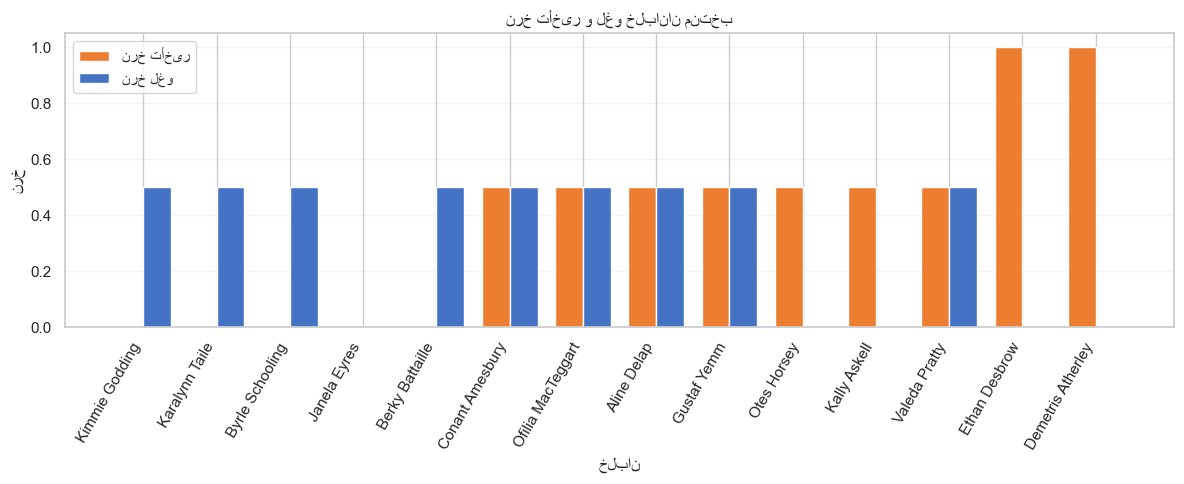

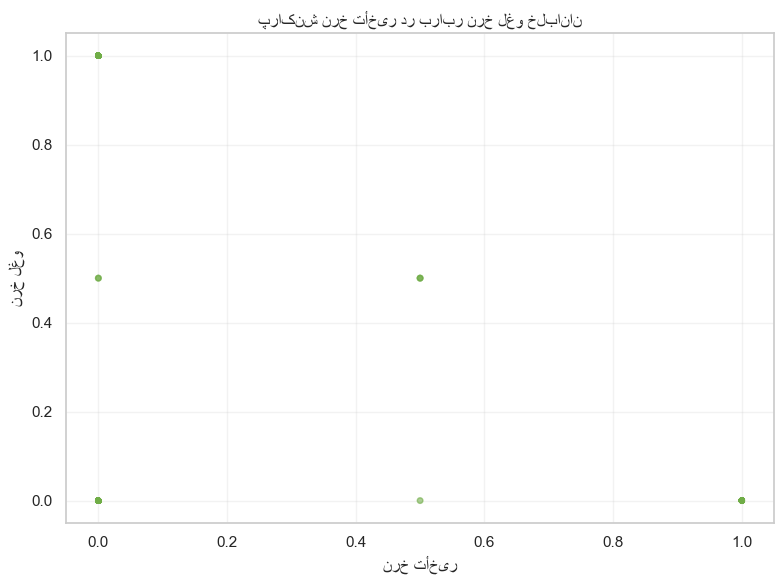

### پاسخ تحلیلی ۶.۹

ستون واقعی خلبان `Pilot Name` بود. مخرج نرخ تأخیر و نرخ لغو، تعداد رکوردهای همان خلبان با وضعیت معتبر (`On Time`، `Delayed` یا `Cancelled`) است؛ رکوردهای دارای وضعیت مفقود یا نامعتبر از مخرج کنار گذاشته می‌شوند. در دادهٔ واقعی، 98,619 رکورد وضعیت معتبر و 0 رکورد وضعیت نامعتبر یا مفقود وجود داشت.

از 98,605 خلبان، 14 خلبان حداقل 2 رکورد معتبر داشتند و در جدول منتخب آمدند. بیشترین نرخ تأخیر در بین خلبانان منتخب مربوط به «Demetris Atherley» با نرخ 100.0% از 2 رکورد بود؛ کمترین نرخ تأخیر مربوط به «Janela Eyres» با نرخ 0.0% از 2 رکورد بود.

با وجود حذف خلبانان تک‌رکوردی از جدول منتخب، حداقل نمونهٔ انتخاب‌شده فقط 2 است؛ بنابراین نرخ‌های ۰٪، ۵۰٪ یا ۱۰۰٪ هنوز می‌توانند به تعداد بسیار کم رکورد وابسته باشند. ترکیب مسیرها، شرکت هواپیمایی و شرایط عملیاتی در این تحلیل کنترل نشده است. همچنین داده نشان نمی‌دهد خلبان مسئول مستقیم تأخیر یا لغو بوده است؛ بنابراین نرخ لغو فقط شاخص توصیفی رکوردهای مرتبط با خلبان است و رابطهٔ علّی یا ارزیابی قطعی عملکرد را ثابت نمی‌کند.

In [41]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

airline_69_path = Path.cwd() / "data" / "airline_cleaned.csv"
airline_69 = pd.read_csv(airline_69_path)

pilot_candidates_69 = ["Pilot Name", "Pilot", "pilot_name", "pilot"]
pilot_column_69 = next((column for column in pilot_candidates_69 if column in airline_69.columns), None)
if pilot_column_69 is None:
    raise KeyError("No pilot-identifying column was found in the cleaned dataset.")

status_column_69 = "Flight Status"
valid_statuses_69 = ["On Time", "Delayed", "Cancelled"]
pilot_values_69 = airline_69[pilot_column_69].astype("string").str.strip()
status_values_69 = airline_69[status_column_69].astype("string").str.strip()
valid_pilot_69 = pilot_values_69.notna() & pilot_values_69.ne("")
valid_status_69 = status_values_69.isin(valid_statuses_69)
valid_records_69 = valid_pilot_69 & valid_status_69

print(f"ستون شناسایی خلبان: {pilot_column_69}")
print(f"خلبان‌های یکتا: {pilot_values_69.nunique(dropna=True):,}")
print(f"رکوردهای دارای وضعیت معتبر: {int(valid_status_69.sum()):,}")
print(f"رکوردهای وضعیت مفقود یا نامعتبر: {int((~valid_status_69).sum()):,}")

status_counts_69 = (
    pd.crosstab(pilot_values_69[valid_records_69], status_values_69[valid_records_69])
    .reindex(columns=valid_statuses_69, fill_value=0)
)
performance_69 = status_counts_69.rename(columns={
    "On Time": "تعداد به‌موقع",
    "Delayed": "تعداد تأخیردار",
    "Cancelled": "تعداد لغوشده",
})
performance_69["تعداد کل پرواز"] = performance_69.sum(axis=1)
performance_69["نرخ تأخیر"] = performance_69["تعداد تأخیردار"] / performance_69["تعداد کل پرواز"]
performance_69["نرخ لغو"] = performance_69["تعداد لغوشده"] / performance_69["تعداد کل پرواز"]
performance_69 = performance_69[[
    "تعداد کل پرواز", "تعداد به‌موقع", "تعداد تأخیردار", "تعداد لغوشده",
    "نرخ تأخیر", "نرخ لغو",
]].sort_values(["تعداد کل پرواز", "نرخ تأخیر"], ascending=[False, False])

print("جدول کامل عملکرد خلبانان:")
display(performance_69)

minimum_flights_69 = 2
selected_69 = performance_69[performance_69["تعداد کل پرواز"] >= minimum_flights_69].copy()
selected_69 = selected_69.sort_values(["نرخ تأخیر", "نرخ لغو"], ascending=False)
selected_display_69 = selected_69.reset_index().rename(columns={pilot_column_69: "نام خلبان"})
selected_display_69["نرخ تأخیر"] = selected_display_69["نرخ تأخیر"].round(4)
selected_display_69["نرخ لغو"] = selected_display_69["نرخ لغو"].round(4)
display(Markdown(
    f"""### جدول Markdown خلبانان منتخب

معیار انتخاب: حداقل **{minimum_flights_69} رکورد پرواز معتبر** برای هر خلبان. این حداقل با توجه به توزیع واقعی داده انتخاب شد؛ خلبانان با یک رکورد از جدول منتخب حذف شدند، اما در جدول کامل باقی ماندند.

{selected_display_69[["نام خلبان", "تعداد کل پرواز", "نرخ تأخیر", "نرخ لغو"]].to_markdown(index=False)}"""
))

plot_69 = selected_69.reset_index()
plot_69["نام خلبان"] = plot_69[pilot_column_69]
plot_69 = plot_69.sort_values("نرخ تأخیر")
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(plot_69))
width = 0.38
ax.bar(x - width / 2, plot_69["نرخ تأخیر"], width, label="نرخ تأخیر", color="#ED7D31")
ax.bar(x + width / 2, plot_69["نرخ لغو"], width, label="نرخ لغو", color="#4472C4")
ax.set_xticks(x, plot_69["نام خلبان"], rotation=60, ha="right")
ax.set_ylabel("نرخ")
ax.set_xlabel("خلبان")
ax.set_title("نرخ تأخیر و لغو خلبانان منتخب")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    performance_69["نرخ تأخیر"],
    performance_69["نرخ لغو"],
    s=np.clip(performance_69["تعداد کل پرواز"] * 8, 12, 160),
    alpha=0.35,
    color="#70AD47",
)
ax.set_xlabel("نرخ تأخیر")
ax.set_ylabel("نرخ لغو")
ax.set_title("پراکنش نرخ تأخیر در برابر نرخ لغو خلبانان")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

highest_delay_69 = selected_69.iloc[0]
lowest_delay_69 = selected_69.sort_values(["نرخ تأخیر", "نرخ لغو"]).iloc[0]
display(Markdown(
    f"""### پاسخ تحلیلی ۶.۹

ستون واقعی خلبان `Pilot Name` بود. مخرج نرخ تأخیر و نرخ لغو، تعداد رکوردهای همان خلبان با وضعیت معتبر (`On Time`، `Delayed` یا `Cancelled`) است؛ رکوردهای دارای وضعیت مفقود یا نامعتبر از مخرج کنار گذاشته می‌شوند. در دادهٔ واقعی، {int(valid_status_69.sum()):,} رکورد وضعیت معتبر و {int((~valid_status_69).sum()):,} رکورد وضعیت نامعتبر یا مفقود وجود داشت.

از {performance_69.shape[0]:,} خلبان، {selected_69.shape[0]:,} خلبان حداقل {minimum_flights_69} رکورد معتبر داشتند و در جدول منتخب آمدند. بیشترین نرخ تأخیر در بین خلبانان منتخب مربوط به «{highest_delay_69.name}» با نرخ {highest_delay_69["نرخ تأخیر"]:.1%} از {int(highest_delay_69["تعداد کل پرواز"]):,} رکورد بود؛ کمترین نرخ تأخیر مربوط به «{lowest_delay_69.name}» با نرخ {lowest_delay_69["نرخ تأخیر"]:.1%} از {int(lowest_delay_69["تعداد کل پرواز"]):,} رکورد بود.

با وجود حذف خلبانان تک‌رکوردی از جدول منتخب، حداقل نمونهٔ انتخاب‌شده فقط {minimum_flights_69} است؛ بنابراین نرخ‌های ۰٪، ۵۰٪ یا ۱۰۰٪ هنوز می‌توانند به تعداد بسیار کم رکورد وابسته باشند. ترکیب مسیرها، شرکت هواپیمایی و شرایط عملیاتی در این تحلیل کنترل نشده است. همچنین داده نشان نمی‌دهد خلبان مسئول مستقیم تأخیر یا لغو بوده است؛ بنابراین نرخ لغو فقط شاخص توصیفی رکوردهای مرتبط با خلبان است و رابطهٔ علّی یا ارزیابی قطعی عملکرد را ثابت نمی‌کند."""
))


### ۶.۱۰ مقایسهٔ توزیع سن بین وضعیت‌های پرواز

این تحلیل از دادهٔ پاک‌سازی‌شده استفاده می‌کند؛ سن‌های مفقود، منفی یا نامعتبر وارد تحلیل عددی نمی‌شوند.

سن معتبر: 98,619
سن مفقود، منفی یا نامعتبر: 0
وضعیت مفقود یا نامعتبر: 0


#### جدول آمار توصیفی سن

| وضعیت پرواز   |   تعداد_نمونه |   میانگین |   میانه |   انحراف_معیار |   کمینه |   چارک_اول |   چارک_سوم |   بیشینه |   دامنهٔ میان‌چارکی |
|:--------------|--------------:|----------:|--------:|---------------:|--------:|-----------:|-----------:|---------:|------------------:|
| On Time       |         32846 |    45.464 |      45 |         25.929 |       1 |         23 |         68 |       90 |                45 |
| Delayed       |         32831 |    45.584 |      46 |         25.923 |       1 |         23 |         68 |       90 |                45 |
| Cancelled     |         32942 |    45.464 |      46 |         25.938 |       1 |         23 |         68 |       90 |                45 |

C:\Users\MOSALAS\AppData\Local\Temp\ipykernel_16180\1813644421.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups_610, labels=labels_610, showmeans=True)


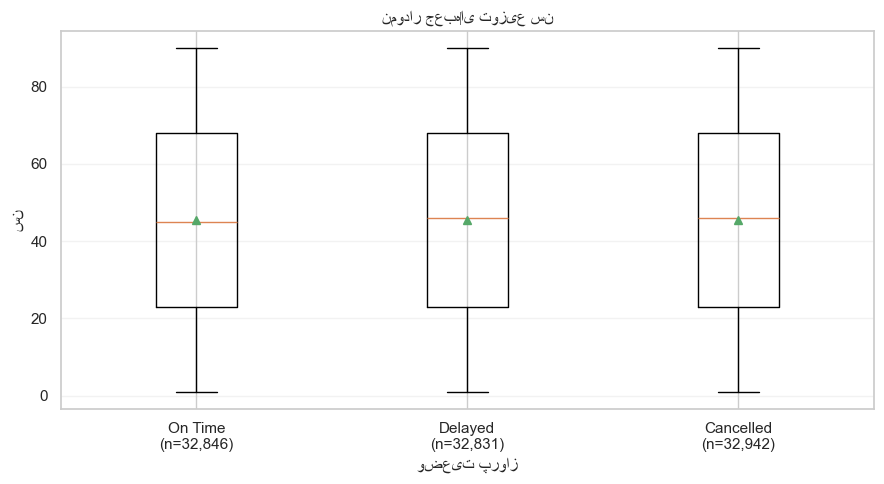

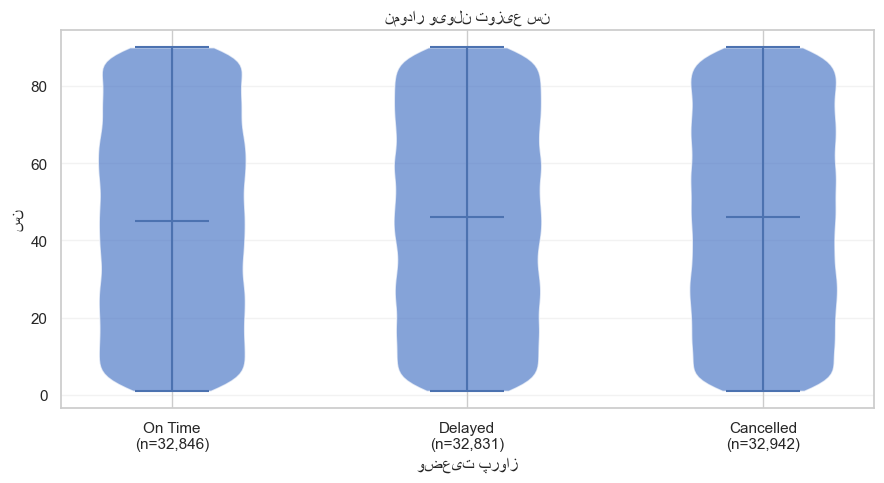

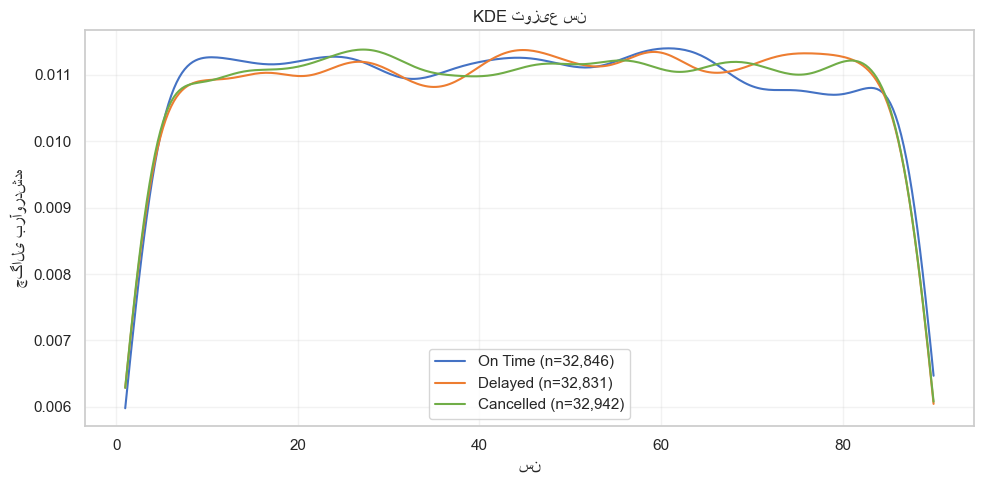

### آزمون آماری

آزمون ناپارامتری **Kruskal–Wallis** با فرض صفر یکسان‌بودن توزیع رتبه‌ای سن در سه گروه اجرا شد. آماره **0.4647** و `p-value` برابر **0.792682** است. پهنای‌باند KDE از قاعدهٔ `Scott` تعیین شد؛ KDE شکل چگالی را نشان می‌دهد و جایگزین تعداد نمونه نیست.

### پاسخ تحلیلی ۶.۱۰

تعداد نمونه‌ها و آمار توصیفی در جدول بالا آمده است. کمترین میانهٔ سن مربوط به «On Time» و بیشترین میانه مربوط به «Delayed» است. چارک‌ها، نمودار جعبه‌ای و ویولن برای مقایسهٔ پراکندگی و شکل توزیع استفاده شدند و نقاط پرت حذف نشدند.

آزمون Kruskal–Wallis آمارهٔ 0.4647 و `p-value` برابر 0.792682 داشت. این نتیجه فقط تفاوت آماری توزیع‌ها را بررسی می‌کند و رابطهٔ علّی میان سن و وضعیت پرواز را اثبات نمی‌کند.

In [42]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, kruskal
from IPython.display import Markdown, display

data_610 = pd.read_csv(Path.cwd() / "data" / "airline_cleaned.csv")
statuses_610 = ["On Time", "Delayed", "Cancelled"]
age_610 = pd.to_numeric(data_610["Age"], errors="coerce")
valid_age_610 = age_610.notna() & age_610.between(0, 120)
valid_status_610 = data_610["Flight Status"].isin(statuses_610)
analysis_610 = pd.DataFrame({"سن": age_610, "وضعیت پرواز": data_610["Flight Status"]}).loc[valid_age_610 & valid_status_610]
print(f"سن معتبر: {len(analysis_610):,}")
print(f"سن مفقود، منفی یا نامعتبر: {int((~valid_age_610).sum()):,}")
print(f"وضعیت مفقود یا نامعتبر: {int((~valid_status_610).sum()):,}")

summary_610 = analysis_610.groupby("وضعیت پرواز")["سن"].agg(
    تعداد_نمونه="count", میانگین="mean", میانه="median", انحراف_معیار="std",
    کمینه="min", چارک_اول=lambda s: s.quantile(.25),
    چارک_سوم=lambda s: s.quantile(.75), بیشینه="max").reindex(statuses_610)
summary_610["دامنهٔ میان‌چارکی"] = summary_610["چارک_سوم"] - summary_610["چارک_اول"]
summary_610 = summary_610.round(3)
display(Markdown("#### جدول آمار توصیفی سن\n\n" + summary_610.to_markdown()))

groups_610 = [analysis_610.loc[analysis_610["وضعیت پرواز"] == s, "سن"].to_numpy() for s in statuses_610]
labels_610 = [f"{s}\n(n={len(v):,})" for s, v in zip(statuses_610, groups_610)]
plt.figure(figsize=(9, 5))
plt.boxplot(groups_610, labels=labels_610, showmeans=True)
plt.xlabel("وضعیت پرواز"); plt.ylabel("سن"); plt.title("نمودار جعبه‌ای توزیع سن"); plt.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 5))
parts = plt.violinplot(groups_610, positions=range(1, 4), showmedians=True, showextrema=True)
for body in parts["bodies"]: body.set_facecolor("#4472C4"); body.set_alpha(.65)
plt.xticks(range(1, 4), labels_610); plt.xlabel("وضعیت پرواز"); plt.ylabel("سن"); plt.title("نمودار ویولن توزیع سن"); plt.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()

grid_610 = np.linspace(float(analysis_610["سن"].min()), float(analysis_610["سن"].max()), 300)
plt.figure(figsize=(10, 5))
for status, values, color in zip(statuses_610, groups_610, ["#4472C4", "#ED7D31", "#70AD47"]):
    plt.plot(grid_610, gaussian_kde(values, bw_method="scott")(grid_610), label=f"{status} (n={len(values):,})", color=color)
plt.xlabel("سن"); plt.ylabel("چگالی برآوردشده"); plt.title("KDE توزیع سن"); plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

stat_610, pvalue_610 = kruskal(*groups_610)
display(Markdown(f"""### آزمون آماری

آزمون ناپارامتری **Kruskal–Wallis** با فرض صفر یکسان‌بودن توزیع رتبه‌ای سن در سه گروه اجرا شد. آماره **{stat_610:.4f}** و `p-value` برابر **{pvalue_610:.6g}** است. پهنای‌باند KDE از قاعدهٔ `Scott` تعیین شد؛ KDE شکل چگالی را نشان می‌دهد و جایگزین تعداد نمونه نیست."""))

low_status_610 = summary_610["میانه"].idxmin()
high_status_610 = summary_610["میانه"].idxmax()
display(Markdown(f"""### پاسخ تحلیلی ۶.۱۰

تعداد نمونه‌ها و آمار توصیفی در جدول بالا آمده است. کمترین میانهٔ سن مربوط به «{low_status_610}» و بیشترین میانه مربوط به «{high_status_610}» است. چارک‌ها، نمودار جعبه‌ای و ویولن برای مقایسهٔ پراکندگی و شکل توزیع استفاده شدند و نقاط پرت حذف نشدند.

آزمون Kruskal–Wallis آمارهٔ {stat_610:.4f} و `p-value` برابر {pvalue_610:.6g} داشت. این نتیجه فقط تفاوت آماری توزیع‌ها را بررسی می‌کند و رابطهٔ علّی میان سن و وضعیت پرواز را اثبات نمی‌کند."""))


### مقایسهٔ توزیع سن در وضعیت‌های پرواز

توزیع سن در سه وضعیت `On Time`، `Delayed` و `Cancelled` بسیار مشابه است. میانگین سن به‌ترتیب **۴۵٫۴۶۴**، **۴۵٫۵۸۴** و **۴۵٫۴۶۴** سال و میانه‌ها به‌ترتیب **۴۵**، **۴۶** و **۴۶** سال هستند. چارک اول در هر سه گروه **۲۳**، چارک سوم **۶۸** و دامنهٔ میان‌چارکی **۴۵** سال است؛ انحراف معیار گروه‌ها نیز تقریباً یکسان و نزدیک به **۲۵٫۹** سال است.

نمودارهای جعبه‌ای، ویولن و KDE تفاوت بزرگی در مرکز یا پراکندگی توزیع‌ها نشان نمی‌دهند. آزمون Kruskal–Wallis نیز با آمارهٔ **۰٫۴۶۴۷** و `p-value=۰٫۷۹۲۶۸۲` شواهدی از تفاوت آماری معنادار ارائه نکرد. بنابراین در این داده تفاوت آشکاری میان توزیع سن سه وضعیت مشاهده نمی‌شود. این نتیجه توصیفی است و به‌تنهایی رابطهٔ علّی میان سن و تأخیر یا لغو پرواز را ثابت نمی‌کند.

### ۶.۱۱ تقویم تعداد پروازها و روزهای دارای تأخیر یا لغو بالا

این تحلیل فقط پروازهای سال ۲۰۲۲ را از دادهٔ پاک‌سازی‌شده بررسی می‌کند. روزهای فاقد رکورد به‌عنوان نبود پوشش داده نمایش داده می‌شوند و صفر واقعی فرض نمی‌شوند.

تاریخ معتبر: 76,691؛ تاریخ نامعتبر یا مفقود: 21,928؛ رکورد ۲۰۲۲: 76,691
روز دارای رکورد: 283؛ بدون رکورد: 82
آستانه حجم: 288.6؛ حداقل نمونه نرخ: 247؛ آستانه تأخیر: 36.81%؛ آستانه لغو: 37.62%
روزهای حجم بالا: 37؛ تأخیر بالا: 26؛ لغو بالا: 26


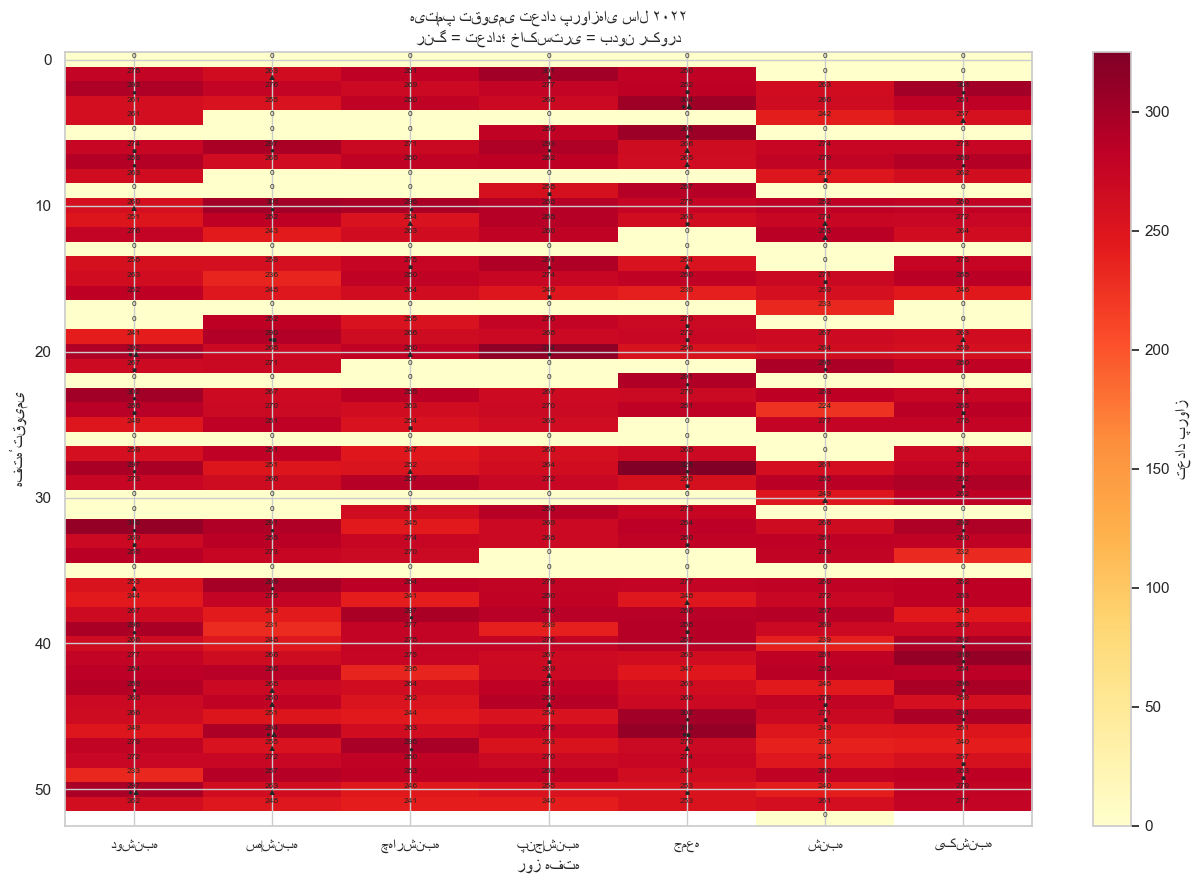

### روزهای با حجم یا نرخ تأخیر/لغو بالا (پاسخ کوتاه)

| تاریخ      | علت انتخاب               |
|:-----------|:-------------------------|
| 2022-01-11 | نرخ تأخیر بالا           |
| 2022-01-13 | حجم بالا                 |
| 2022-01-16 | حجم بالا                 |
| 2022-01-17 | حجم بالا                 |
| 2022-01-21 | نرخ لغو بالا             |
| 2022-01-28 | حجم بالا، نرخ تأخیر بالا |
| 2022-01-30 | نرخ تأخیر بالا           |
| 2022-02-11 | حجم بالا                 |
| 2022-02-14 | نرخ لغو بالا             |
| 2022-02-15 | حجم بالا                 |
| 2022-02-17 | حجم بالا                 |
| 2022-02-18 | نرخ تأخیر بالا           |
| 2022-02-20 | حجم بالا                 |
| 2022-02-21 | حجم بالا                 |
| 2022-02-25 | نرخ تأخیر بالا           |
| 2022-02-26 | نرخ لغو بالا             |
| 2022-03-10 | نرخ لغو بالا             |
| 2022-03-14 | نرخ تأخیر بالا           |
| 2022-03-15 | حجم بالا                 |
| 2022-03-16 | حجم بالا                 |
| 2022-03-19 | نرخ تأخیر بالا           |
| 2022-03-23 | نرخ تأخیر بالا           |
| 2022-03-25 | نرخ لغو بالا             |
| 2022-03-26 | نرخ تأخیر بالا           |
| 2022-04-13 | نرخ لغو بالا             |
| 2022-04-14 | حجم بالا                 |
| 2022-04-15 | نرخ تأخیر بالا           |
| 2022-04-16 | نرخ لغو بالا             |
| 2022-04-28 | نرخ لغو بالا             |
| 2022-05-13 | نرخ لغو بالا             |
| 2022-05-15 | نرخ تأخیر بالا           |
| 2022-05-17 | حجم بالا، نرخ لغو بالا   |
| 2022-05-20 | نرخ لغو بالا             |
| 2022-05-23 | حجم بالا، نرخ تأخیر بالا |
| 2022-05-25 | نرخ تأخیر بالا           |
| 2022-05-26 | حجم بالا                 |
| 2022-05-28 | حجم بالا                 |
| 2022-05-30 | نرخ لغو بالا             |
| 2022-06-10 | حجم بالا                 |
| 2022-06-13 | حجم بالا                 |
| 2022-06-19 | نرخ لغو بالا             |
| 2022-06-20 | نرخ لغو بالا             |
| 2022-06-29 | نرخ لغو بالا             |
| 2022-07-18 | حجم بالا                 |
| 2022-07-20 | نرخ تأخیر بالا           |
| 2022-07-22 | حجم بالا                 |
| 2022-07-24 | حجم بالا                 |
| 2022-07-29 | نرخ لغو بالا             |
| 2022-07-30 | نرخ تأخیر بالا           |
| 2022-08-14 | حجم بالا                 |
| 2022-08-15 | حجم بالا                 |
| 2022-08-16 | حجم بالا                 |
| 2022-08-22 | نرخ لغو بالا             |
| 2022-08-26 | نرخ لغو بالا             |
| 2022-09-12 | نرخ تأخیر بالا           |
| 2022-09-13 | حجم بالا                 |
| 2022-09-23 | نرخ تأخیر بالا           |
| 2022-09-28 | حجم بالا                 |
| 2022-10-03 | حجم بالا                 |
| 2022-10-07 | نرخ لغو بالا             |
| 2022-10-09 | حجم بالا                 |
| 2022-10-16 | حجم بالا                 |
| 2022-10-20 | نرخ لغو بالا             |
| 2022-10-27 | نرخ تأخیر بالا           |
| 2022-10-30 | حجم بالا                 |
| 2022-10-31 | حجم بالا                 |
| 2022-11-01 | نرخ تأخیر بالا           |
| 2022-11-05 | نرخ لغو بالا             |
| 2022-11-08 | نرخ تأخیر بالا           |
| 2022-11-10 | نرخ تأخیر بالا           |
| 2022-11-12 | نرخ لغو بالا             |
| 2022-11-13 | حجم بالا                 |
| 2022-11-18 | حجم بالا                 |
| 2022-11-22 | حجم بالا، نرخ تأخیر بالا |
| 2022-11-25 | حجم بالا، نرخ لغو بالا   |
| 2022-11-29 | نرخ تأخیر بالا           |
| 2022-11-30 | حجم بالا                 |
| 2022-12-02 | نرخ تأخیر بالا           |
| 2022-12-04 | نرخ لغو بالا             |
| 2022-12-11 | نرخ لغو بالا             |
| 2022-12-19 | حجم بالا، نرخ تأخیر بالا |
| 2022-12-20 | نرخ تأخیر بالا           |
| 2022-12-23 | نرخ لغو بالا             |

**آستانه‌ها:** حجم بالا از صدک ۹۰ یعنی 288.6 پرواز؛ نرخ‌های بالا از صدک ۹۰ پس از حداقل 247 پرواز محاسبه شدند. آستانه نرخ تأخیر 36.81% و نرخ لغو 37.62% بود.

### تفسیر هیت‌مپ سال ۲۰۲۲

از ۳۶۵ روز سال، 283 روز رکورد و 82 روز بدون رکورد داشتند؛ بنابراین خانه‌های بدون رکورد نبود پوشش هستند، نه صفر قطعی. رنگ فقط حجم روزانه را نشان می‌دهد و `●`، `▲` و `■` به‌ترتیب حجم، نرخ تأخیر و نرخ لغو بالا را مشخص می‌کنند. این الگوها علت را به روز هفته، تعطیلات یا عوامل بیرونی نسبت نمی‌دهند و نرخ‌ها باید همراه تعداد نمونه تفسیر شوند.

In [43]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

d = pd.read_csv(Path.cwd() / "data" / "airline_cleaned.csv")
parsed = pd.to_datetime(d["Departure Date"], errors="coerce")
bad = parsed.isna()
in_2022 = parsed.dt.year.eq(2022)
subset = d.loc[in_2022 & ~bad].copy()
subset["روز"] = parsed.loc[subset.index].dt.normalize()
print(f"تاریخ معتبر: {(~bad).sum():,}؛ تاریخ نامعتبر یا مفقود: {bad.sum():,}؛ رکورد ۲۰۲۲: {len(subset):,}")

idx = pd.date_range("2022-01-01", "2022-12-31", freq="D")
total = subset.groupby("روز").size().reindex(idx)
counts = pd.crosstab(subset["روز"], subset["Flight Status"]).reindex(idx, fill_value=0)
for s in ["Delayed", "Cancelled"]:
    if s not in counts: counts[s] = 0
daily = pd.DataFrame({"تعداد پرواز": total, "تعداد تأخیردار": counts["Delayed"], "تعداد لغوشده": counts["Cancelled"]})
observed = daily["تعداد پرواز"].notna()
daily["تعداد پرواز"] = daily["تعداد پرواز"].fillna(0).astype(int)
daily["تعداد تأخیردار"] = daily["تعداد تأخیردار"].fillna(0).astype(int)
daily["تعداد لغوشده"] = daily["تعداد لغوشده"].fillna(0).astype(int)
daily["نرخ تأخیر"] = daily["تعداد تأخیردار"].div(daily["تعداد پرواز"]).where(daily["تعداد پرواز"].gt(0))
daily["نرخ لغو"] = daily["تعداد لغوشده"].div(daily["تعداد پرواز"]).where(daily["تعداد پرواز"].gt(0))
volume_cut = daily["تعداد پرواز"].quantile(.9)
min_n = max(10, int(daily.loc[observed, "تعداد پرواز"].quantile(.1)))
eligible = observed & daily["تعداد پرواز"].ge(min_n)
delay_cut = daily.loc[eligible, "نرخ تأخیر"].quantile(.9)
cancel_cut = daily.loc[eligible, "نرخ لغو"].quantile(.9)
daily["حجم بالا"] = observed & daily["تعداد پرواز"].ge(volume_cut)
daily["نرخ تأخیر بالا"] = eligible & daily["نرخ تأخیر"].ge(delay_cut)
daily["نرخ لغو بالا"] = eligible & daily["نرخ لغو"].ge(cancel_cut)
print(f"روز دارای رکورد: {observed.sum()}؛ بدون رکورد: {(~observed).sum()}")
print(f"آستانه حجم: {volume_cut:.1f}؛ حداقل نمونه نرخ: {min_n}؛ آستانه تأخیر: {delay_cut:.2%}؛ آستانه لغو: {cancel_cut:.2%}")
print(f"روزهای حجم بالا: {daily['حجم بالا'].sum()}؛ تأخیر بالا: {daily['نرخ تأخیر بالا'].sum()}؛ لغو بالا: {daily['نرخ لغو بالا'].sum()}")

frame = daily.copy()
frame["هفته"] = ((frame.index - pd.Timestamp("2022-01-01")).days // 7) + 1
frame["روز هفته"] = frame.index.to_series().dt.weekday
heat = frame.pivot(index="هفته", columns="روز هفته", values="تعداد پرواز").reindex(index=range(1,54), columns=range(7))
coverage = frame.assign(_date=frame.index).pivot(index="هفته", columns="روز هفته", values="_date").reindex(index=range(1,54), columns=range(7))
fig, ax = plt.subplots(figsize=(13,9))
im = ax.imshow(np.ma.masked_invalid(heat.to_numpy(float)), cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(7), ["دوشنبه","سه‌شنبه","چهارشنبه","پنج‌شنبه","جمعه","شنبه","یکشنبه"])
ax.set_ylabel("هفتهٔ تقویمی"); ax.set_xlabel("روز هفته")
ax.set_title("هیت‌مپ تقویمی تعداد پروازهای سال ۲۰۲۲\nرنگ = تعداد؛ خاکستری = بدون رکورد")
cb = fig.colorbar(im, ax=ax); cb.set_label("تعداد پرواز")
for r in range(heat.shape[0]):
    for c in range(7):
        if pd.notna(coverage.iloc[r,c]):
            date = coverage.iloc[r,c]; mark = ""
            if daily.loc[date, "حجم بالا"]: mark += "●"
            if daily.loc[date, "نرخ تأخیر بالا"]: mark += "▲"
            if daily.loc[date, "نرخ لغو بالا"]: mark += "■"
            ax.text(c, r, f"{int(heat.iloc[r,c])}\n{mark}", ha="center", va="center", fontsize=6)
plt.tight_layout(); plt.show()

short = []
for date, row in daily.iterrows():
    reasons = [name for name, flag in [("حجم بالا", row["حجم بالا"]), ("نرخ تأخیر بالا", row["نرخ تأخیر بالا"]), ("نرخ لغو بالا", row["نرخ لغو بالا"])] if flag]
    if reasons: short.append({"تاریخ": date.strftime("%Y-%m-%d"), "علت انتخاب": "، ".join(reasons)})
short_df = pd.DataFrame(short)
display(Markdown("### روزهای با حجم یا نرخ تأخیر/لغو بالا (پاسخ کوتاه)\n\n" + short_df.to_markdown(index=False)))
display(Markdown(f"""**آستانه‌ها:** حجم بالا از صدک ۹۰ یعنی {volume_cut:.1f} پرواز؛ نرخ‌های بالا از صدک ۹۰ پس از حداقل {min_n} پرواز محاسبه شدند. آستانه نرخ تأخیر {delay_cut:.2%} و نرخ لغو {cancel_cut:.2%} بود."""))
display(Markdown(f"""### تفسیر هیت‌مپ سال ۲۰۲۲

از ۳۶۵ روز سال، {observed.sum()} روز رکورد و {(~observed).sum()} روز بدون رکورد داشتند؛ بنابراین خانه‌های بدون رکورد نبود پوشش هستند، نه صفر قطعی. رنگ فقط حجم روزانه را نشان می‌دهد و `●`، `▲` و `■` به‌ترتیب حجم، نرخ تأخیر و نرخ لغو بالا را مشخص می‌کنند. این الگوها علت را به روز هفته، تعطیلات یا عوامل بیرونی نسبت نمی‌دهند و نرخ‌ها باید همراه تعداد نمونه تفسیر شوند."""))


### ۶.۱۲ شناسایی و ارزیابی نقاط پرت سن

در این تحلیل، بازهٔ معقول سن به‌عنوان قاعدهٔ اعتبارسنجی از ۰ تا ۱۲۰ سال تعریف شده است. این قاعده با حدود آماری IQR یکی نیست؛ ممکن است مقداری از نظر آماری پرت باشد اما همچنان معتبر باشد.

In [44]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

airline_612 = pd.read_csv(Path.cwd() / "data" / "airline_cleaned.csv")
age_raw_612 = airline_612["Age"]
age_612 = pd.to_numeric(age_raw_612, errors="coerce")
missing_612 = age_raw_612.isna()
non_numeric_612 = age_612.isna() & ~missing_612
negative_612 = age_612.lt(0)
out_of_range_612 = age_612.gt(120)
valid_612 = age_612.notna() & age_612.between(0, 120)
values_612 = age_612[valid_612]

q1_612 = values_612.quantile(.25)
q3_612 = values_612.quantile(.75)
iqr_612 = q3_612 - q1_612
lower_612 = q1_612 - 1.5 * iqr_612
upper_612 = q3_612 + 1.5 * iqr_612
iqr_mask_612 = valid_612 & ~age_612.between(lower_612, upper_612)
mean_612 = values_612.mean()
std_612 = values_612.std(ddof=1)
z_scores_612 = (age_612 - mean_612) / std_612
z_mask_612 = valid_612 & z_scores_612.abs().gt(3)
common_612 = iqr_mask_612 & z_mask_612

print(f"مقادیر مفقود: {int(missing_612.sum()):,}")
print(f"مقادیر غیرعددی: {int(non_numeric_612.sum()):,}")
print(f"مقادیر منفی: {int(negative_612.sum()):,}")
print(f"مقادیر خارج از بازهٔ ۰ تا ۱۲۰: {int(out_of_range_612.sum()):,}")
print(f"تعداد سن معتبر برای روش‌های آماری: {len(values_612):,}")
print(f"Q1={q1_612:.3f}، Q3={q3_612:.3f}، IQR={iqr_612:.3f}")
print(f"حد پایین IQR={lower_612:.3f}، حد بالا IQR={upper_612:.3f}")
print(f"میانگین={mean_612:.3f}، انحراف معیار نمونه‌ای={std_612:.3f}؛ آستانهٔ Z برابر قدرمطلق ۳")
print(f"نقاط پرت IQR: {int(iqr_mask_612.sum()):,} ({100 * iqr_mask_612.sum() / len(values_612):.3f}٪)")
print(f"نقاط پرت Z-score: {int(z_mask_612.sum()):,} ({100 * z_mask_612.sum() / len(values_612):.3f}٪)")
print(f"نقاط مشترک دو روش: {int(common_612.sum()):,}")

summary_612 = pd.DataFrame([
    {"معیار": "IQR", "تعداد نقاط پرت": int(iqr_mask_612.sum()), "درصد از سن معتبر": round(100 * iqr_mask_612.sum() / len(values_612), 3)},
    {"معیار": "Z-score با آستانه |Z|>3", "تعداد نقاط پرت": int(z_mask_612.sum()), "درصد از سن معتبر": round(100 * z_mask_612.sum() / len(values_612), 3)},
    {"معیار": "مشترک دو روش", "تعداد نقاط پرت": int(common_612.sum()), "درصد از سن معتبر": round(100 * common_612.sum() / len(values_612), 3)},
])
display(Markdown("#### خلاصهٔ نقاط پرت\n\n" + summary_612.to_markdown(index=False)))
display(Markdown(f"""### پاسخ تحلیلی ۶.۱۲

قاعدهٔ اعتبارسنجی این تحلیل بازهٔ ۰ تا ۱۲۰ سال است؛ این قاعده برای تشخیص مقدار نامعتبر به‌کار رفت و با تعریف آماری پرت یکسان نیست. از {len(values_612):,} مقدار معتبر، Q1 برابر {q1_612:.1f}، Q3 برابر {q3_612:.1f} و IQR برابر {iqr_612:.1f} بود؛ بنابراین حدود IQR از {lower_612:.1f} تا {upper_612:.1f} به‌دست آمد. میانگین سن {mean_612:.3f} و انحراف معیار نمونه‌ای {std_612:.3f} بود.

مقدارهای مفقود و غیرعددی پیش از محاسبات آماری کنار گذاشته شدند؛ مقدارهای منفی یا بزرگ‌تر از ۱۲۰ نیز نامعتبر تلقی می‌شوند و نباید صرفاً با برچسب پرت اصلاح شوند. در دادهٔ واقعی هیچ مقدار مفقود، غیرعددی، منفی یا خارج از بازهٔ اعتبارسنجی وجود نداشت. بنابراین تعداد پرت‌های IQR برابر **۰**، تعداد پرت‌های Z-score برابر **۰** و تعداد مشترک دو روش نیز **۰** است.

راهبرد پیشنهادی این است که سن معتبر، حتی اگر از نظر آماری پرت باشد، بدون دلیل حذف یا محدود نشود؛ مقدار نامعتبر فقط پس از بررسی منبع معتبر به‌روزرسانی شود و در صورت نبود منبع، به مقدار مفقود تبدیل شود. حذف رکورد فقط زمانی انجام شود که مقدار نامعتبر برای تحلیل ضروری باشد و حذف آن توجیه مستند داشته باشد."""
))


مقادیر مفقود: 0
مقادیر غیرعددی: 0
مقادیر منفی: 0
مقادیر خارج از بازهٔ ۰ تا ۱۲۰: 0
تعداد سن معتبر برای روش‌های آماری: 98,619
Q1=23.000، Q3=68.000، IQR=45.000
حد پایین IQR=-44.500، حد بالا IQR=135.500
میانگین=45.504، انحراف معیار نمونه‌ای=25.930؛ آستانهٔ Z برابر قدرمطلق ۳
نقاط پرت IQR: 0 (0.000٪)
نقاط پرت Z-score: 0 (0.000٪)
نقاط مشترک دو روش: 0


#### خلاصهٔ نقاط پرت

| معیار                   |   تعداد نقاط پرت |   درصد از سن معتبر |
|:------------------------|-----------------:|-------------------:|
| IQR                     |                0 |                  0 |
| Z-score با آستانه |Z|>3 |                0 |                  0 |
| مشترک دو روش            |                0 |                  0 |

### پاسخ تحلیلی ۶.۱۲

قاعدهٔ اعتبارسنجی این تحلیل بازهٔ ۰ تا ۱۲۰ سال است؛ این قاعده برای تشخیص مقدار نامعتبر به‌کار رفت و با تعریف آماری پرت یکسان نیست. از 98,619 مقدار معتبر، Q1 برابر 23.0، Q3 برابر 68.0 و IQR برابر 45.0 بود؛ بنابراین حدود IQR از -44.5 تا 135.5 به‌دست آمد. میانگین سن 45.504 و انحراف معیار نمونه‌ای 25.930 بود.

مقدارهای مفقود و غیرعددی پیش از محاسبات آماری کنار گذاشته شدند؛ مقدارهای منفی یا بزرگ‌تر از ۱۲۰ نیز نامعتبر تلقی می‌شوند و نباید صرفاً با برچسب پرت اصلاح شوند. در دادهٔ واقعی هیچ مقدار مفقود، غیرعددی، منفی یا خارج از بازهٔ اعتبارسنجی وجود نداشت. بنابراین تعداد پرت‌های IQR برابر **۰**، تعداد پرت‌های Z-score برابر **۰** و تعداد مشترک دو روش نیز **۰** است.

راهبرد پیشنهادی این است که سن معتبر، حتی اگر از نظر آماری پرت باشد، بدون دلیل حذف یا محدود نشود؛ مقدار نامعتبر فقط پس از بررسی منبع معتبر به‌روزرسانی شود و در صورت نبود منبع، به مقدار مفقود تبدیل شود. حذف رکورد فقط زمانی انجام شود که مقدار نامعتبر برای تحلیل ضروری باشد و حذف آن توجیه مستند داشته باشد.

### ۶.۱۳ آزمون کای‌دو و اندازه‌گیری شدت ارتباط

این تحلیل از دادهٔ پاک‌سازی‌شده استفاده می‌کند. ستون قارهٔ فرودگاه مستقیماً از `Airport Continent` انتخاب شده و از نام فرودگاه قاره‌ای حدس زده نمی‌شود.

In [45]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from IPython.display import Markdown, display

airline_613 = pd.read_csv(Path.cwd() / "data" / "airline_cleaned.csv")
age_613 = pd.to_numeric(airline_613["Age"], errors="coerce")
age_labels_613 = ["کودک", "جوان", "بزرگسال", "سالمند", "کهنسال"]
airline_613["گروه سنی"] = pd.cut(
    age_613.where(age_613.between(0, 120)),
    bins=[0, 18, 36, 56, 76, np.inf],
    labels=age_labels_613,
    right=False,
)
feature_columns_613 = ["گروه سنی", "Nationality", "Airport Continent", "Flight Status"]
print("ستون‌های استفاده‌شده:", feature_columns_613)
print("قاره از ستون Airport Continent انتخاب شد؛ از نام فرودگاه استخراج یا حدس زده نشد.")

def benjamini_hochberg_613(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues)
    ranked = pvalues[order]
    adjusted = ranked * len(ranked) / np.arange(1, len(ranked) + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1].clip(0, 1)
    result = np.empty_like(adjusted)
    result[order] = adjusted
    return result

results_613 = []
for first, second in combinations(feature_columns_613, 2):
    table = pd.crosstab(airline_613[first], airline_613[second], dropna=False)
    if first == "گروه سنی":
        table = table.reindex(age_labels_613, fill_value=0)
    if second == "گروه سنی":
        table = table.reindex(columns=age_labels_613, fill_value=0)
    chi2, pvalue, dof, expected = chi2_contingency(table)
    n = int(table.to_numpy().sum())
    cramer_v = np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))
    results_613.append({
        "جفت ویژگی": f"{first} × {second}",
        "آماره کای‌دو": chi2,
        "درجه آزادی": dof,
        "p-value خام": pvalue,
        "Cramér's V خام": cramer_v,
        "تعداد مشاهدات": n,
        "درصد فراوانی مورد انتظار کمتر از ۵": 100 * (expected < 5).mean(),
        "حداقل فراوانی مورد انتظار": expected.min(),
    })
results_613 = pd.DataFrame(results_613)
results_613["p-value اصلاح‌شده BH"] = benjamini_hochberg_613(results_613["p-value خام"])
results_613["کفایت تقریبی"] = np.where(
    results_613["درصد فراوانی مورد انتظار کمتر از ۵"] <= 20,
    "مناسب‌تر",
    "احتیاط؛ خانه‌های کم‌انتظار",
)
results_613 = results_613.sort_values("Cramér's V خام", ascending=False).reset_index(drop=True)
display(Markdown("#### جدول مقایسهٔ آزمون‌ها\n\n" + results_613.round(6).to_markdown(index=False)))

strongest_613 = results_613.iloc[0]
display(Markdown(f"""### پاسخ تحلیلی ۶.۱۳

قوی‌ترین جفت بر اساس بیشترین Cramér’s V خام، نه صرفاً کمترین `p-value`، **{strongest_613["جفت ویژگی"]}** است. مقدار Cramér’s V برابر **{strongest_613["Cramér's V خام"]:.6f}** و `p-value` خام برابر **{strongest_613["p-value خام"]:.6g}** است؛ مقدار اصلاح‌شدهٔ Benjamini–Hochberg برای همین جفت **{strongest_613["p-value اصلاح‌شده BH"]:.6g}** است.

در محاسبه، مقدارهای مفقود به‌صورت حذف جفتی کنار گذاشته شدند و گروه سنی فقط با مرزهای ثابت تعریف شد. Cramér’s V خام با فرمول `sqrt(χ² / (n × min(r−1, c−1)))` محاسبه شد و اصلاح سوگیری جداگانه‌ای اعمال نشد. در جدول‌های شامل ملیت، تعداد دسته‌ها زیاد است و بخشی از فراوانی‌های مورد انتظار کمتر از ۵ است؛ بنابراین مفروضهٔ تقریبی کای‌دو در آن جفت‌ها ضعیف‌تر است و مقایسه باید با احتیاط انجام شود. Cramér’s V شدت ارتباط را نشان می‌دهد، نه جهت رابطه و نه علیت؛ p-value کوچک نیز به‌تنهایی به معنی ارتباط قوی نیست."""
))


ستون‌های استفاده‌شده: ['گروه سنی', 'Nationality', 'Airport Continent', 'Flight Status']
قاره از ستون Airport Continent انتخاب شد؛ از نام فرودگاه استخراج یا حدس زده نشد.


#### جدول مقایسهٔ آزمون‌ها

| جفت ویژگی                         |   آماره کای‌دو |   درجه آزادی |   p-value خام |   Cramér's V خام |   تعداد مشاهدات |   درصد فراوانی مورد انتظار کمتر از ۵ |   حداقل فراوانی مورد انتظار |   p-value اصلاح‌شده BH | کفایت تقریبی             |
|:----------------------------------|--------------:|-------------:|--------------:|-----------------:|----------------:|-------------------------------------:|----------------------------:|----------------------:|:-------------------------|
| گروه سنی × Nationality            |     957.144   |          956 |      0.48349  |         0.049258 |           98619 |                              33.6667 |                    0.165435 |              0.978048 | احتیاط؛ خانه‌های کم‌انتظار |
| Nationality × Flight Status       |     471.347   |          478 |      0.577139 |         0.048885 |           98619 |                              23.4722 |                    0.332907 |              0.978048 | احتیاط؛ خانه‌های کم‌انتظار |
| Nationality × Airport Continent   |    1166.49    |         1195 |      0.717099 |         0.048638 |           98619 |                              38.4722 |                    0.108681 |              0.978048 | احتیاط؛ خانه‌های کم‌انتظار |
| گروه سنی × Airport Continent      |      22.49    |           20 |      0.314523 |         0.007551 |           98619 |                               0      |                 1773.13     |              0.978048 | مناسب‌تر                  |
| Airport Continent × Flight Status |       5.65799 |           10 |      0.843132 |         0.005356 |           98619 |                               0      |                 3568.1      |              0.978048 | مناسب‌تر                  |
| گروه سنی × Flight Status          |       2.09238 |            8 |      0.978048 |         0.003257 |           98619 |                               0      |                 5431.39     |              0.978048 | مناسب‌تر                  |

### پاسخ تحلیلی ۶.۱۳

قوی‌ترین جفت بر اساس بیشترین Cramér’s V خام، نه صرفاً کمترین `p-value`، **گروه سنی × Nationality** است. مقدار Cramér’s V برابر **0.049258** و `p-value` خام برابر **0.48349** است؛ مقدار اصلاح‌شدهٔ Benjamini–Hochberg برای همین جفت **0.978048** است.

در محاسبه، مقدارهای مفقود به‌صورت حذف جفتی کنار گذاشته شدند و گروه سنی فقط با مرزهای ثابت تعریف شد. Cramér’s V خام با فرمول `sqrt(χ² / (n × min(r−1, c−1)))` محاسبه شد و اصلاح سوگیری جداگانه‌ای اعمال نشد. در جدول‌های شامل ملیت، تعداد دسته‌ها زیاد است و بخشی از فراوانی‌های مورد انتظار کمتر از ۵ است؛ بنابراین مفروضهٔ تقریبی کای‌دو در آن جفت‌ها ضعیف‌تر است و مقایسه باید با احتیاط انجام شود. Cramér’s V شدت ارتباط را نشان می‌دهد، نه جهت رابطه و نه علیت؛ p-value کوچک نیز به‌تنهایی به معنی ارتباط قوی نیست.

### قوی‌ترین جفت ویژگی

**گروه سنی × Nationality**

### Cramér’s V جفت منتخب

**۰٫۰۴۹۲۵۸**

### p-value جفت منتخب

p-value خام: **۰٫۴۸۳۴۹**  
p-value اصلاح‌شده با Benjamini–Hochberg: **۰٫۹۷۸۰۴۸**

### مقایسهٔ روابط و تفسیر

در میان شش جفت بررسی‌شده، بیشترین Cramér’s V مربوط به «گروه سنی × Nationality» با مقدار **۰٫۰۴۹۲۵۸** بود؛ با این حال، این مقدار شدت ارتباط پایینی را نشان می‌دهد. جفت «Nationality × Flight Status» با V برابر **۰٫۰۴۸۸۸۵** و جفت «Nationality × Airport Continent» با V برابر **۰٫۰۴۸۶۳۸** در رتبه‌های بعدی قرار گرفتند. ارتباط‌های مربوط به قاره و وضعیت پرواز یا گروه سنی و وضعیت پرواز بسیار ضعیف‌تر بودند.

برای جفت‌های شامل ملیت، به‌دلیل ۲۴۰ دستهٔ ملیت، بخشی از فراوانی‌های مورد انتظار کمتر از ۵ بود؛ بنابراین نتیجهٔ آزمون کای‌دو باید با احتیاط تفسیر شود. اصلاح Benjamini–Hochberg نیز برای مقایسهٔ چند آزمون انجام شد. Cramér’s V فقط شدت ارتباط را نشان می‌دهد و جهت یا علیت را مشخص نمی‌کند؛ p-value کوچک نیز به‌تنهایی به معنی ارتباط قوی نیست.

### ۶.۱۴ مسیرهای پرتکرار و عملکرد به‌موقع

مسیر به‌صورت زوج مرتب «فرودگاه مبدأ → فرودگاه مقصد» تعریف می‌شود؛ بنابراین مسیرهای رفت و برگشت دو مسیر متفاوت هستند. تحلیل از دادهٔ پاک‌سازی‌شده انجام می‌شود.

ستون مبدأ: Airport Name؛ ستون مقصد: Arrival Airport
رکوردهای دارای مبدأ، مقصد و وضعیت معتبر: 98,619
رکوردهای کنارگذاشته‌شده به‌دلیل مقدار مفقود یا نامعتبر: 0


تعداد مسیرهای یکتا: 9,127
صدک ۹۰ فراوانی مسیر: 15.0؛ مسیرهای محبوب: 1,213
صدک ۱۰ فراوانی مسیر: 7.0؛ مسیرهای کم‌تکرار: 1,446
میانگین ساده نرخ به‌موقع محبوب: 33.4809%
میانگین ساده نرخ به‌موقع کم‌تکرار: 32.6406%
نرخ تجمیعی محبوب: 33.4282%؛ نرخ تجمیعی کم‌تکرار: 32.6045%
آزمون Mann–Whitney U: آماره=919166.500، p-value=0.0322088


#### جدول ۲۰ مسیر پرتکرار

| مسیر                                                   |   تعداد پرواز |   تعداد به‌موقع |   تعداد تأخیردار |   تعداد لغوشده |   نرخ به‌موقع |   نرخ تأخیر |   نرخ لغو |
|:-------------------------------------------------------|--------------:|---------------:|-----------------:|---------------:|-------------:|------------:|----------:|
| Böblingen Flugfeld → PHM                               |            36 |             13 |               10 |             13 |       0.3611 |      0.2778 |    0.3611 |
| Punta Colorada Airport → PCO                           |            27 |              9 |               11 |              7 |       0.3333 |      0.4074 |    0.2593 |
| Yangzhou Taizhou Airport → YTY                         |            27 |              5 |                9 |             13 |       0.1852 |      0.3333 |    0.4815 |
| Zaraza Airport → ZRZ                                   |            26 |             12 |                7 |              7 |       0.4615 |      0.2692 |    0.2692 |
| Amchitka Army Airfield → AHT                           |            25 |              4 |               10 |             11 |       0.16   |      0.4    |    0.44   |
| Great Falls International Airport → GTF                |            25 |              7 |                9 |              9 |       0.28   |      0.36   |    0.36   |
| Lanzhou Zhongchuan Airport → LHW                       |            24 |              8 |               10 |              6 |       0.3333 |      0.4167 |    0.25   |
| Danilo Atienza Air Base → SGL                          |            24 |              8 |                4 |             12 |       0.3333 |      0.1667 |    0.5    |
| Sawan Airport → RZS                                    |            24 |              6 |               13 |              5 |       0.25   |      0.5417 |    0.2083 |
| Mampikony Airport → WMP                                |            23 |             10 |                8 |              5 |       0.4348 |      0.3478 |    0.2174 |
| Lonely Air Station → LNI                               |            23 |              5 |                8 |             10 |       0.2174 |      0.3478 |    0.4348 |
| Heho Airport → HEH                                     |            23 |              8 |                7 |              8 |       0.3478 |      0.3043 |    0.3478 |
| Witu Airport → WIU                                     |            23 |              9 |                6 |              8 |       0.3913 |      0.2609 |    0.3478 |
| OR Tambo International Airport → JNB                   |            23 |             13 |                7 |              3 |       0.5652 |      0.3043 |    0.1304 |
| Bangassou Airport → BGU                                |            23 |              6 |                8 |              9 |       0.2609 |      0.3478 |    0.3913 |
| Del Caribe Santiago Mariño International Airport → PMV |            23 |             13 |                5 |              5 |       0.5652 |      0.2174 |    0.2174 |
| Xai-Xai Airport → VJB                                  |            22 |             10 |                5 |              7 |       0.4545 |      0.2273 |    0.3182 |
| Shah Mokhdum Airport → RJH                             |            22 |              9 |                5 |              8 |       0.4091 |      0.2273 |    0.3636 |
| Koolatah Airport → KOH                                 |            22 |              7 |               10 |              5 |       0.3182 |      0.4545 |    0.2273 |
| New Amsterdam Airport → QSX                            |            22 |              6 |                9 |              7 |       0.2727 |      0.4091 |    0.3182 |

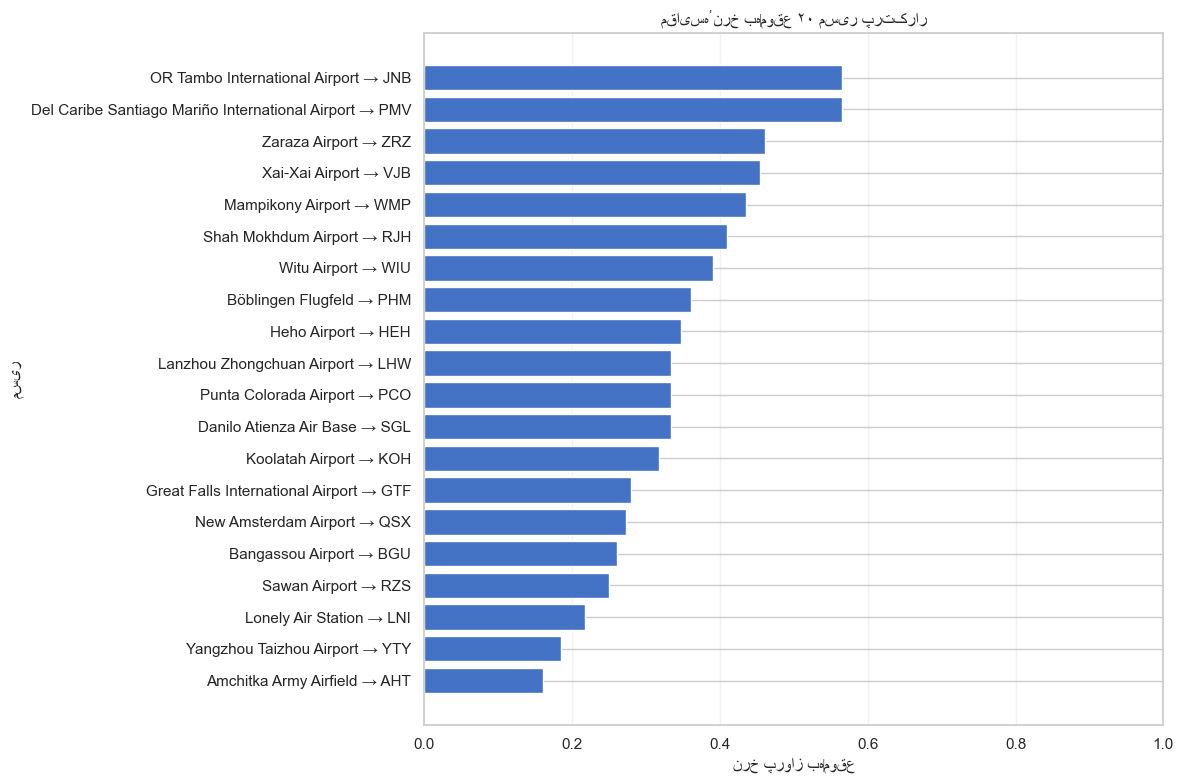

### پاسخ تحلیلی ۶.۱۴

ستون‌های واقعی مبدأ و مقصد به‌ترتیب `Airport Name` و `Arrival Airport` بودند. مسیر فقط زمانی وارد تحلیل شد که هر دو مقدار غیرخالی و وضعیت پرواز در مجموعهٔ سه‌گانهٔ مجاز باشد؛ مسیرهای رفت و برگشت جداگانه نگه داشته شدند. مخرج همهٔ نرخ‌های مسیر، تعداد پروازهای همان مسیر با وضعیت معتبر است.

معیار «محبوب» صدک ۹۰ فراوانی مسیر یعنی حداقل 15.0 پرواز و معیار «کم‌تکرار» صدک ۱۰ یعنی حداکثر 7.0 پرواز بود. مسیرهای محبوب 1,213 و مسیرهای کم‌تکرار 1,446 مسیر بودند. میانگین سادهٔ نرخ به‌موقع برای محبوب‌ها 33.48% و برای کم‌تکرارها 32.64% است؛ نرخ تجمیعی مبتنی بر تعداد پرواز نیز به‌ترتیب 33.43% و 32.60% بود.

آزمون Mann–Whitney برای مقایسهٔ نرخ‌های مسیر، آمارهٔ 919166.500 و `p-value=0.0322088` داشت. بنابراین بر اساس معیار تجمیعی تعریف‌شده، پاسخ «بله» است؛ اما اختلاف کوچک است و به تعریف محبوب‌بودن و وزن‌دهی مسیرها وابسته است. تفاوت مشاهده‌شده علت مسیر را ثابت نمی‌کند و ترکیب شرکت، زمان، مبدأ و مقصد و تعداد کم برخی مسیرها محدودیت تحلیل هستند.

In [46]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from IPython.display import Markdown, display

route_data_614 = pd.read_csv(Path.cwd() / "data" / "airline_cleaned.csv")
origin_614 = "Airport Name"
destination_614 = "Arrival Airport"
status_614 = "Flight Status"
valid_statuses_614 = ["On Time", "Delayed", "Cancelled"]
origin_text_614 = route_data_614[origin_614].astype("string").str.strip()
destination_text_614 = route_data_614[destination_614].astype("string").str.strip()
valid_route_614 = (
    origin_text_614.notna() & origin_text_614.ne("") &
    destination_text_614.notna() & destination_text_614.ne("") &
    route_data_614[status_614].isin(valid_statuses_614)
)
print(f"ستون مبدأ: {origin_614}؛ ستون مقصد: {destination_614}")
print(f"رکوردهای دارای مبدأ، مقصد و وضعیت معتبر: {int(valid_route_614.sum()):,}")
print(f"رکوردهای کنارگذاشته‌شده به‌دلیل مقدار مفقود یا نامعتبر: {int((~valid_route_614).sum()):,}")

routes_614 = pd.DataFrame({
    "مبدأ": origin_text_614.loc[valid_route_614],
    "مقصد": destination_text_614.loc[valid_route_614],
    "وضعیت": route_data_614.loc[valid_route_614, status_614],
})
route_counts_614 = routes_614.groupby(["مبدأ", "مقصد"]).size().rename("تعداد پرواز")
route_status_614 = pd.crosstab(
    [routes_614["مبدأ"], routes_614["مقصد"]], routes_614["وضعیت"]
).reindex(columns=valid_statuses_614, fill_value=0)
route_stats_614 = route_counts_614.to_frame().join(route_status_614)
route_stats_614 = route_stats_614.rename(columns={
    "On Time": "تعداد به‌موقع", "Delayed": "تعداد تأخیردار", "Cancelled": "تعداد لغوشده",
})
route_stats_614["نرخ به‌موقع"] = route_stats_614["تعداد به‌موقع"] / route_stats_614["تعداد پرواز"]
route_stats_614["نرخ تأخیر"] = route_stats_614["تعداد تأخیردار"] / route_stats_614["تعداد پرواز"]
route_stats_614["نرخ لغو"] = route_stats_614["تعداد لغوشده"] / route_stats_614["تعداد پرواز"]
route_stats_614 = route_stats_614.sort_values("تعداد پرواز", ascending=False)

route_frequency_614 = route_stats_614["تعداد پرواز"]
popular_cut_614 = route_frequency_614.quantile(.90)
rare_cut_614 = route_frequency_614.quantile(.10)
popular_614 = route_stats_614[route_stats_614["تعداد پرواز"] >= popular_cut_614]
rare_614 = route_stats_614[route_stats_614["تعداد پرواز"] <= rare_cut_614]
popular_simple_ontime_614 = popular_614["نرخ به‌موقع"].mean()
rare_simple_ontime_614 = rare_614["نرخ به‌موقع"].mean()
popular_weighted_ontime_614 = popular_614["تعداد به‌موقع"].sum() / popular_614["تعداد پرواز"].sum()
rare_weighted_ontime_614 = rare_614["تعداد به‌موقع"].sum() / rare_614["تعداد پرواز"].sum()
test_614 = mannwhitneyu(popular_614["نرخ به‌موقع"], rare_614["نرخ به‌موقع"], alternative="two-sided")

print(f"تعداد مسیرهای یکتا: {len(route_stats_614):,}")
print(f"صدک ۹۰ فراوانی مسیر: {popular_cut_614:.1f}؛ مسیرهای محبوب: {len(popular_614):,}")
print(f"صدک ۱۰ فراوانی مسیر: {rare_cut_614:.1f}؛ مسیرهای کم‌تکرار: {len(rare_614):,}")
print(f"میانگین ساده نرخ به‌موقع محبوب: {popular_simple_ontime_614:.4%}")
print(f"میانگین ساده نرخ به‌موقع کم‌تکرار: {rare_simple_ontime_614:.4%}")
print(f"نرخ تجمیعی محبوب: {popular_weighted_ontime_614:.4%}؛ نرخ تجمیعی کم‌تکرار: {rare_weighted_ontime_614:.4%}")
print(f"آزمون Mann–Whitney U: آماره={test_614.statistic:.3f}، p-value={test_614.pvalue:.6g}")

top_routes_614 = route_stats_614.head(20).reset_index()
top_routes_614["مسیر"] = top_routes_614["مبدأ"] + " → " + top_routes_614["مقصد"]
top_table_614 = top_routes_614[["مسیر", "تعداد پرواز", "تعداد به‌موقع", "تعداد تأخیردار", "تعداد لغوشده", "نرخ به‌موقع", "نرخ تأخیر", "نرخ لغو"]].copy()
for column in ["نرخ به‌موقع", "نرخ تأخیر", "نرخ لغو"]:
    top_table_614[column] = top_table_614[column].round(4)
display(Markdown("#### جدول ۲۰ مسیر پرتکرار\n\n" + top_table_614.to_markdown(index=False)))

plot_routes_614 = top_routes_614.sort_values("نرخ به‌موقع")
plt.figure(figsize=(12, 8))
plt.barh(plot_routes_614["مسیر"], plot_routes_614["نرخ به‌موقع"], color="#4472C4")
plt.xlabel("نرخ پرواز به‌موقع")
plt.ylabel("مسیر")
plt.title("مقایسهٔ نرخ به‌موقع ۲۰ مسیر پرتکرار")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()

best_route_614 = route_stats_614.index[0]
best_route_text_614 = f"{best_route_614[0]} → {best_route_614[1]}"
popular_answer_614 = "بله" if popular_weighted_ontime_614 > rare_weighted_ontime_614 else "خیر"
display(Markdown(f"""### پاسخ تحلیلی ۶.۱۴

ستون‌های واقعی مبدأ و مقصد به‌ترتیب `{origin_614}` و `{destination_614}` بودند. مسیر فقط زمانی وارد تحلیل شد که هر دو مقدار غیرخالی و وضعیت پرواز در مجموعهٔ سه‌گانهٔ مجاز باشد؛ مسیرهای رفت و برگشت جداگانه نگه داشته شدند. مخرج همهٔ نرخ‌های مسیر، تعداد پروازهای همان مسیر با وضعیت معتبر است.

معیار «محبوب» صدک ۹۰ فراوانی مسیر یعنی حداقل {popular_cut_614:.1f} پرواز و معیار «کم‌تکرار» صدک ۱۰ یعنی حداکثر {rare_cut_614:.1f} پرواز بود. مسیرهای محبوب {len(popular_614):,} و مسیرهای کم‌تکرار {len(rare_614):,} مسیر بودند. میانگین سادهٔ نرخ به‌موقع برای محبوب‌ها {popular_simple_ontime_614:.2%} و برای کم‌تکرارها {rare_simple_ontime_614:.2%} است؛ نرخ تجمیعی مبتنی بر تعداد پرواز نیز به‌ترتیب {popular_weighted_ontime_614:.2%} و {rare_weighted_ontime_614:.2%} بود.

آزمون Mann–Whitney برای مقایسهٔ نرخ‌های مسیر، آمارهٔ {test_614.statistic:.3f} و `p-value={test_614.pvalue:.6g}` داشت. بنابراین بر اساس معیار تجمیعی تعریف‌شده، پاسخ «{popular_answer_614}» است؛ اما اختلاف کوچک است و به تعریف محبوب‌بودن و وزن‌دهی مسیرها وابسته است. تفاوت مشاهده‌شده علت مسیر را ثابت نمی‌کند و ترکیب شرکت، زمان، مبدأ و مقصد و تعداد کم برخی مسیرها محدودیت تحلیل هستند."""
))


### تعداد مسیرهای یکتا

**۹٬۱۲۷ مسیر یکتا** شناسایی شد.

### پرتکرارترین مسیر

**Böblingen Flugfeld → PHM** با **۳۶ پرواز** پرتکرارترین مسیر بود.

### آیا مسیرهای محبوب عملکرد به‌موقع بهتری دارند؟

**بله**؛ بر اساس نرخ تجمیعی تعریف‌شده برای معیار صدک ۹۰، نرخ به‌موقع مسیرهای محبوب **۳۳٫۴۳٪** و مسیرهای کم‌تکرار **۳۲٫۶۰٪** بود.

### شواهد و تحلیل

مسیرهای محبوب با حداقل ۱۵ پرواز (صدک ۹۰) و مسیرهای کم‌تکرار با حداکثر ۷ پرواز (صدک ۱۰) تعریف شدند. این دو گروه به‌ترتیب ۱٬۲۱۳ و ۱٬۴۴۶ مسیر داشتند. میانگین سادهٔ نرخ به‌موقع نیز برای دو گروه ۳۳٫۴۸٪ و ۳۲٫۶۴٪ بود. آزمون Mann–Whitney روی نرخ مسیرها `p-value=0.0322088` داد، اما اختلاف اندازهٔ کوچکی دارد و به تعریف محبوب‌بودن و ترکیب مسیرها وابسته است؛ بنابراین از آن رابطهٔ علّی نتیجه نمی‌شود.